# Colab experiment
Run from the top in Google Colab. Choose the required runtime first. If dependency installation asks for a runtime restart, restart and run from the top again. Set RESUME_RUN_ID only for an explicitly verified compatible checkpoint. Use RECOVER_RUN_ID to deliver staged results without rerunning compute. For a shared folder, add its shortcut in My Drive or set PROJECT_PATH_OVERRIDE to the actual mounted folder path. Put credentials in Colab Secrets; never paste them into this notebook.


In [1]:
import json, sys, subprocess, importlib.metadata, time, uuid
from pathlib import Path
CONFIG = json.loads('{"budget":{"estimated_hours":0.15,"max_hours":2.0},"confirmed":true,"context":{"dataset_id":"rdd2020_datasprint_2_0","dataset_revision":"2026-11-23","evaluation_config_hash":"tide_tf50_tb10_dece10_dri4_eigencam","evaluator_id":"official_score_py_plus_tide_dece","evaluator_revision":"v1","n_samples":2150,"split_hash":"val2150_gt2561","split_id":"official_val"},"dependency_check":"required","drive_folder_id":"1n8ddoVvmlpff1ScGLi_WPw-pPBe_AyC1","drive_relative_path":"DataSprint_2.0_Road_Damage","experiment":{"conf_floor":0.001,"imgsz":"AUTO","iou_nms":0.6,"knn_k":15,"max_det":100,"n_clusters":6,"reuse_cached_preds":true,"seed":42,"stress_sample_n_cpu":400,"stress_sample_n_gpu":2150,"target_run_id":"9e682727-8382-46b2-bdb9-747d3df1cd08","top_k_visual":8,"val_pred_csv_override":""},"experiment_name":"datasprint2_reusable_error_analysis_v1","gpu_required":false,"metric_context":{"clean_road_fp_rate_at_opt_thr":{"higher_is_better":false,"split":"val_image_level","unit":"ratio_0_1"},"clean_vs_defect_roc_auc":{"higher_is_better":true,"split":"val_image_level","unit":"ratio_0_1"},"conf_iou_spearman":{"higher_is_better":true,"split":"val_calibration","unit":"ratio_neg1_1"},"dece_overall":{"higher_is_better":false,"split":"val_calibration","unit":"ratio_0_1"},"dri_mean_stress":{"higher_is_better":true,"split":"val_degraded_4bucket","unit":"ratio_0_1"},"oof_postproc_accuracy_gain_pts":{"higher_is_better":true,"split":"val_5fold_cv","unit":"score_delta_pts"},"suspected_unlabeled_gt_count":{"higher_is_better":false,"split":"val_audit","unit":"count"},"tide_delta_bkg":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"tide_delta_both":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"tide_delta_cls":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"tide_delta_dupe":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"tide_delta_loc":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"tide_delta_miss":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"val_accuracy_score_100":{"higher_is_better":true,"split":"val_clean","unit":"score_0_100"},"val_mAP50":{"higher_is_better":true,"split":"val_clean","unit":"ratio_0_1"},"val_mAP50_95":{"higher_is_better":true,"split":"val_clean","unit":"ratio_0_1"},"val_precision":{"higher_is_better":true,"split":"val_clean","unit":"ratio_0_1"},"val_recall":{"higher_is_better":true,"split":"val_clean","unit":"ratio_0_1"}},"min_free_disk_gib":10,"min_gpu_memory_gib":0,"packages":["ultralytics==8.4.216","albumentations==2.0.8"],"project_id":"datasprint-2-0-road-damage","schema_version":"colab-builder-config/1","source_fingerprints":{"builder_sha256":"40efd2603d219b5ffce5bca7f5149ed20644fb0e49db68cc529b6b4f86a998a0","runtime_sha256":"e30c67b27342488b5304b3b938070e2fbe06c8a8cdcc3064cc645e732c2f906c","task_sha256":"87abe03dec70567b01f49570270e5f713c5f9e64334e1e305bc7a31f83b01d42"},"workload":"evaluation"}')
RESUME_RUN_ID = ''  # Set an existing run ID only when resuming.
RECOVER_RUN_ID = ''  # Deliver saved results only; does not rerun the task.
PROJECT_PATH_OVERRIDE = ''  # Optional path inside /content/drive.
START_NEW_RUN = False  # Set True for a fresh independent attempt.
if not RECOVER_RUN_ID and CONFIG.get('python_min') and sys.version_info[:2] < tuple(map(int, CONFIG['python_min'].split('.'))):
    raise RuntimeError('Python version below project requirement; choose a compatible Colab runtime')
if not RECOVER_RUN_ID and CONFIG.get('python_max_exclusive') and sys.version_info[:2] >= tuple(map(int, CONFIG['python_max_exclusive'].split('.'))):
    raise RuntimeError('Python version outside project compatibility range')
if RESUME_RUN_ID and RECOVER_RUN_ID:
    raise ValueError('Select recovery or checkpoint resumption, not both')
if RESUME_RUN_ID or RECOVER_RUN_ID:
    RUN_ID = RESUME_RUN_ID or RECOVER_RUN_ID
elif START_NEW_RUN or 'RUN_ID' not in globals() or globals().get('RUN_PROJECT_ID') != CONFIG['project_id']:
    RUN_ID = str(uuid.uuid4())
RUN_PROJECT_ID = CONFIG['project_id']
print('Run ID:', RUN_ID)
import importlib.util
RUNTIME_SOURCE = '"""Standard-library logging/recovery. No network calls or ML dependencies.\n\nAuditing third-party requirement markers uses the installed packaging parser.\nStandard-library-only EDA and event recovery do not require that package.\n\nLocal locks/CAS do not provide distributed locking on a mounted Google Drive.\nSerialize remote writers and reconcile destination markers before retrying writes.\n"""\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport math\nimport os\nimport re\nimport tempfile\nimport uuid\nimport importlib.metadata\nimport subprocess\nimport sys\nfrom contextlib import contextmanager\nfrom datetime import datetime, timezone\nfrom pathlib import Path\n\nSCHEMA_VERSION = 2\n_ID = re.compile(r"[A-Za-z0-9][A-Za-z0-9_-]{0,95}\\Z")\n_SECRET = re.compile(r"(?:^|_)(?:api_key|access_token|refresh_token|hf_token|password|secret|authorization|cookie|credentials|private_key|secret_access_key|access_key_id)$")\nDEFAULT_CONTEXT_KEYS = (\n    "dataset_id", "dataset_revision", "split_id", "split_hash",\n    "evaluator_id", "evaluator_revision", "evaluation_config_hash", "n_samples",\n)\n\n\ndef utc_now():\n    return datetime.now(timezone.utc).isoformat(timespec="microseconds")\n\n\ndef check_json(value, path="root"):\n    """Reject non-JSON objects, non-finite values, and credential-bearing keys."""\n    if value is None or isinstance(value, (str, bool, int)):\n        return\n    if isinstance(value, float):\n        if not math.isfinite(value):\n            raise ValueError(f"Non-finite number at {path}")\n        return\n    if isinstance(value, list):\n        for i, child in enumerate(value):\n            check_json(child, f"{path}[{i}]")\n        return\n    if isinstance(value, dict):\n        for key, child in value.items():\n            if not isinstance(key, str):\n                raise TypeError("JSON object keys must be strings")\n            snake = re.sub(r"([a-z0-9])([A-Z])", r"\\1_\\2", key)\n            normalized = re.sub(r"[^a-z0-9]+", "_", snake.lower()).strip("_")\n            if _SECRET.search(normalized) or normalized in {"token", "apikey"}:\n                raise ValueError("Credential-bearing field rejected; use Colab Secrets")\n            check_json(child, f"{path}.{key}")\n        return\n    raise TypeError(f"Unsupported JSON value at {path}; convert explicitly")\n\n\ndef canonical(value):\n    check_json(value)\n    return json.dumps(value, sort_keys=True, ensure_ascii=False,\n                      separators=(",", ":"), allow_nan=False).encode("utf-8")\n\n\ndef digest(value):\n    return hashlib.sha256(canonical(value)).hexdigest()\n\n\ndef file_digest(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as stream:\n        for block in iter(lambda: stream.read(1024 * 1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef strict_loads(text):\n    # Reject NaN/Infinity rather than silently accepting JavaScript extensions.\n    def reject(_):\n        raise ValueError("Invalid JSON numeric constant")\n    def unique_pairs(pairs):\n        result = {}\n        for key, value in pairs:\n            if key in result:\n                raise ValueError("Duplicate JSON object key")\n            result[key] = value\n        return result\n    def finite_float(raw):\n        number = float(raw)\n        if not math.isfinite(number):\n            raise ValueError("Invalid JSON numeric constant")\n        return number\n    return json.loads(text, parse_constant=reject, object_pairs_hook=unique_pairs, parse_float=finite_float)\n\n\ndef read_json(path):\n    return strict_loads(Path(path).read_text(encoding="utf-8"))\n\n\ndef component(value):\n    if not isinstance(value, str) or not _ID.fullmatch(value):\n        raise ValueError("Use a nonempty, safe ID (letters, digits, hyphen, underscore)")\n    return value\n\n\ndef within(root, relative):\n    root = Path(root).resolve()\n    rel = Path(relative)\n    if rel.is_absolute() or ".." in rel.parts:\n        raise ValueError("Expected a project-relative path")\n    target = (root / rel).resolve()\n    if target == root or root not in target.parents:\n        raise ValueError("Path escapes project or names its root")\n    return target\n\n\ndef resolve_project_root(mount_root, relative_path, project_id, *, override=\'\', folder_id=None):\n    """Resolve an explicit mounted path and verify identity before ANY write.\n\n    Shared-folder visibility is not inferred from connector access. An override\n    must remain inside the mount and point at the verified project registry.\n    """\n    mount = Path(mount_root).resolve()\n    if override:\n        target = Path(override)\n        if not target.is_absolute():\n            target = mount / target\n        target = target.resolve()\n        if mount not in target.parents:\n            raise ValueError(\'Project override must be inside the mounted Drive\')\n    else:\n        target = within(mount / \'MyDrive\', relative_path)\n    state_path = target / \'05_reports/autopilot/project_state.json\'\n    if not state_path.is_file():\n        raise FileNotFoundError(\'Project is not visible in mounted Drive. Add its shortcut to My Drive, \'\n                                \'or set PROJECT_PATH_OVERRIDE to its mounted path. Mount an account \'\n                                \'that can access the folder. No replacement project was created.\')\n    state = read_json(state_path)\n    if state.get(\'schema_version\') != SCHEMA_VERSION or state.get(\'project_id\') != project_id:\n        raise ValueError(\'Mounted project identity/schema mismatch\')\n    if folder_id and state.get(\'registry\', {}).get(\'root_folder\', {}).get(\'id\') != folder_id:\n        raise ValueError(\'Mounted Drive folder ID mismatch\')\n    return target\n\n\ndef dependency_report(pins, *, policy=\'required\', run=subprocess.run,\n                      requires=importlib.metadata.requires):\n    """Inspect pip check, blocking workload dependency conflicts.\n\n    Unrelated preinstalled conflicts are surfaced separately; unknown checker\n    failures still stop execution. No environment-wide repair or uninstall.\n    """\n    if policy not in {\'required\', \'all\'}:\n        raise ValueError(\'Unknown dependency policy\')\n    normalize = lambda name: re.sub(r\'[-_.]+\', \'-\', name.lower())\n    roots = {normalize(pin.split(\'==\', 1)[0]) for pin in pins}\n    required = set(roots)\n    requested_extras = {name: set() for name in roots}\n    processed = {}\n    queue = list(required)\n    while queue:\n        name = queue.pop()\n        active_extras = requested_extras[name]\n        if name in processed and processed[name] == active_extras:\n            continue\n        processed[name] = set(active_extras)\n        try:\n            dependencies = requires(name) or []\n        except importlib.metadata.PackageNotFoundError:\n            if name in roots:\n                raise RuntimeError(\'A required package is missing\') from None\n            continue  # Optional/conditional requirement; pip check judges runtime applicability.\n        for requirement in dependencies:\n            try:\n                from packaging.requirements import Requirement\n            except ImportError:\n                raise RuntimeError(\'Requirement metadata needs the packaging parser; include a compatible packaging pin\') from None\n            try:\n                parsed = Requirement(requirement)\n                if parsed.marker and not any(parsed.marker.evaluate({\'extra\': extra})\n                                             for extra in {\'\'} | active_extras):\n                    continue\n            except (ValueError, KeyError):\n                raise RuntimeError(\'Cannot interpret a required dependency marker\') from None\n            child = normalize(parsed.name)\n            extras = {normalize(extra) for extra in parsed.extras}\n            if child not in requested_extras or not extras <= requested_extras[child]:\n                requested_extras.setdefault(child, set()).update(extras)\n                required.add(child)\n                queue.append(child)\n    checked = run([sys.executable, \'-m\', \'pip\', \'check\'], capture_output=True, text=True)\n    if checked.returncode == 0:\n        return {\'status\': \'clean\', \'unrelated_conflicts\': 0, \'required_packages\': sorted(required)}\n    conflicts = []\n    for line in checked.stdout.splitlines():\n        match = re.match(r\'^([A-Za-z0-9_.-]+)\\s+\\S+\\s+(?:requires|has requirement)\\s+([A-Za-z0-9_.-]+)\', line)\n        if not match:\n            raise RuntimeError(\'Dependency checker failed or returned an unrecognized conflict\')\n        conflicts.append((normalize(match[1]), normalize(match[2])))\n    if not conflicts or checked.stderr.strip():\n        raise RuntimeError(\'Dependency checker did not produce a valid report\')\n    # Only requirements OF the workload closure constrain this run. An unrelated\n    # reverse dependent (for example an unused app constraining numpy) does not.\n    if policy == \'all\' or any(a in required for a, b in conflicts):\n        raise RuntimeError(\'Required dependency conflict; diagnose before running this workload\')\n    return {\'status\': \'unrelated_conflicts\', \'unrelated_conflicts\': len(conflicts),\n            \'required_packages\': sorted(required)}\n\n\n@contextmanager\ndef local_lock(path):\n    """Fail closed on contention. Never auto-delete another writer\'s lock."""\n    lock = Path(str(path) + ".lock")\n    lock.parent.mkdir(parents=True, exist_ok=True)\n    fd = os.open(str(lock), os.O_CREAT | os.O_EXCL | os.O_WRONLY, 0o600)\n    try:\n        os.write(fd, str(os.getpid()).encode("ascii"))\n        os.close(fd)\n        fd = None\n        yield\n    finally:\n        if fd is not None:\n            os.close(fd)\n        lock.unlink()\n\n\ndef atomic_json(path, value, *, expected=None, absent=False):\n    """Atomic same-directory replace plus a local cooperative lock and SHA CAS."""\n    path = Path(path)\n    payload = canonical(value)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    with local_lock(path):\n        if absent and path.exists():\n            raise FileExistsError(str(path))\n        if expected is not None and (not path.exists() or file_digest(path) != expected):\n            raise RuntimeError("State changed; reload and reconcile")\n        fd, temporary = tempfile.mkstemp(prefix=".pending-", dir=path.parent)\n        try:\n            with os.fdopen(fd, "wb") as out:\n                out.write(payload)\n                out.flush()\n                os.fsync(out.fileno())\n            os.replace(temporary, path)\n        finally:\n            if os.path.exists(temporary):\n                os.unlink(temporary)\n    # Readback checks local bytes only; it cannot prove Drive server durability.\n    if path.read_bytes() != payload:\n        raise IOError("JSON write readback mismatch")\n    return path\n\n\ndef _numeric(value):\n    return (not isinstance(value, bool) and\n            (isinstance(value, int) or isinstance(value, float) and math.isfinite(value)))\n\n\ndef validate_metrics(metrics):\n    if not isinstance(metrics, dict):\n        raise TypeError("metrics must be a JSON object")\n    for name, value in metrics.items():\n        if not isinstance(name, str) or not name or not _numeric(value):\n            raise ValueError("Metric names must be nonempty strings and values finite numbers")\n\n\nclass LogDeliveryError(OSError):\n    """The log is staged locally but its project destination was not verified."""\n    def __init__(self, spool_path, error_category):\n        self.spool_path = Path(spool_path)\n        self.error_category = error_category\n        super().__init__(f"Log delivery pending ({error_category}); recover from {self.spool_path}")\n\n\ndef _write_event(path, record):\n    try:\n        atomic_json(path, record, absent=True)\n    except FileExistsError:\n        if not path.is_file():\n            raise\n        prior = read_json(path)\n        body = {k: v for k, v in prior.items() if k not in {"timestamp_utc", "payload_digest"}}\n        expected = record["payload_digest"]\n        if prior.get("payload_digest") != expected or digest(body) != expected:\n            raise FileExistsError("Event ID already contains different data; choose a revision ID") from None\n    return path\n\n\ndef validate_context(context, metric_context):\n    if not isinstance(context,dict) or not isinstance(metric_context,dict):\n        raise ValueError(\'Evaluation context and metric_context must be objects\')\n    if any(not isinstance(key,str) or not key.strip() or not isinstance(value,dict)\n           for key,value in metric_context.items()):\n        raise ValueError(\'Each metric context must be a named object\')\n    check_json(context)\n    check_json(metric_context)\n\n\ndef validate_event(record, *, run_id=None, project_id=None):\n    """Validate a saved event before sync or recovery; never execute its source."""\n    check_json(record)\n    if not isinstance(record, dict) or record.get(\'schema_version\') != SCHEMA_VERSION:\n        raise ValueError(\'Unsupported event schema\')\n    component(record.get(\'run_id\'))\n    component(record.get(\'event_id\'))\n    if run_id and record[\'run_id\'] != run_id:\n        raise ValueError(\'Event run identity mismatch\')\n    if not isinstance(record.get(\'config\'), dict):\n        raise ValueError(\'Event configuration is missing\')\n    if project_id and record[\'config\'].get(\'project_id\') != project_id:\n        raise ValueError(\'Event project identity mismatch\')\n    if record.get(\'status\') not in {\'completed\', \'partial\', \'failed\', \'interrupted\'}:\n        raise ValueError(\'Invalid event status\')\n    validate_context(record.get(\'context\', {}), record.get(\'metric_context\', {}))\n    validate_metrics(record.get(\'metrics\'))\n    if record[\'status\'] == \'completed\' and not record[\'metrics\']:\n        raise ValueError(\'Completed event lacks metrics\')\n    body = {k: v for k, v in record.items() if k not in {\'timestamp_utc\', \'payload_digest\'}}\n    if digest(body) != record.get(\'payload_digest\'):\n        raise ValueError(\'Event payload checksum mismatch\')\n    return record\n\n\ndef copy_immutable_file(source, destination, expected_sha256, *, max_bytes=16 * 1024 * 1024):\n    """Recover bounded task artifacts; refuse oversized files and replacements."""\n    source, destination = Path(source), Path(destination)\n    if source.stat().st_size > max_bytes:\n        raise ValueError(\'Recovery artifact is too large or has a mismatched checksum\')\n    with source.open(\'rb\') as stream:\n        payload = stream.read(max_bytes + 1)\n    if len(payload) > max_bytes or hashlib.sha256(payload).hexdigest() != expected_sha256:\n        raise ValueError(\'Recovery artifact is too large or has a mismatched checksum\')\n    destination.parent.mkdir(parents=True, exist_ok=True)\n    with local_lock(destination):\n        if destination.exists():\n            if file_digest(destination) != expected_sha256:\n                raise FileExistsError(\'Recovery destination contains different content\')\n            return destination\n        fd, temporary = tempfile.mkstemp(prefix=\'.recovery-\', dir=destination.parent)\n        try:\n            with os.fdopen(fd, \'wb\') as stream:\n                stream.write(payload)\n                stream.flush()\n                os.fsync(stream.fileno())\n            os.replace(temporary, destination)\n        finally:\n            if os.path.exists(temporary):\n                os.unlink(temporary)\n    if file_digest(destination) != expected_sha256:\n        raise IOError(\'Recovery artifact readback mismatch\')\n    return destination\n\n\ndef recover_spooled_events(project_root, spool_root, run_id, *, project_id):\n    """Deliver original staged events and bounded artifacts WITHOUT recompute."""\n    run_id = component(run_id)\n    state = read_json(within(project_root, \'05_reports/autopilot/project_state.json\'))\n    if state.get(\'schema_version\') != SCHEMA_VERSION or state.get(\'project_id\') != project_id:\n        raise ValueError(\'Recovery project mismatch\')\n    events = within(spool_root, f\'03_results/runs/{run_id}/events\')\n    delivered = []\n    for source in sorted(events.glob(\'*.json\')):\n        source = within(spool_root, f\'03_results/runs/{run_id}/events/{source.name}\')\n        record = validate_event(read_json(source), run_id=run_id, project_id=project_id)\n        if source.stem != record[\'event_id\']:\n            raise ValueError(\'Event path identity mismatch\')\n        artifacts = record.get(\'artifacts\', {}).get(\'files\', {})\n        if not isinstance(artifacts, dict):\n            raise ValueError(\'Invalid artifact manifest\')\n        for relative, sha256 in artifacts.items():\n            copy_immutable_file(within(spool_root, relative), within(project_root, relative), sha256)\n        destination = within(project_root, f\'03_results/runs/{run_id}/events/{source.name}\')\n        _write_event(destination, record)\n        observed = validate_event(read_json(destination), run_id=run_id, project_id=project_id)\n        if observed[\'payload_digest\'] != record[\'payload_digest\']:\n            raise IOError(\'Recovered event readback mismatch\')\n        delivered.append({\'event_id\': record[\'event_id\'], \'status\': record[\'status\']})\n    return delivered\n\n\ndef log_experiment(project_root, exp_id, metrics, *, run_id=None, event_id="final",\n                   status="completed", model_name=None, config=None, context=None,\n                   metric_context=None, artifacts=None, notes="", errors=None,\n                   spool_root=None):\n    """Write an immutable run event. Retry with the SAME run_id/event_id.\n\n    A different payload at an existing ID raises; log corrections under a new\n    event_id. Returned files contain JSON primitives only. No secret values print.\n    """\n    run_id = component(run_id or str(uuid.uuid4()))\n    event_id = component(event_id)\n    if status not in {"completed", "partial", "failed", "interrupted"}:\n        raise ValueError("Unknown run status")\n    if config is not None and not isinstance(config,dict):\n        raise ValueError("Experiment config must be an object")\n    validate_context({} if context is None else context, {} if metric_context is None else metric_context)\n    validate_metrics(metrics)\n    if status == "completed" and not metrics:\n        raise ValueError("Completed runs need observed metrics")\n    if artifacts is not None and not isinstance(artifacts, dict):\n        raise ValueError(\'Artifacts must be an object\')\n    files = (artifacts or {}).get(\'files\', {})\n    if not isinstance(files, dict) or any(not isinstance(path, str) or not isinstance(sha, str)\n            or not re.fullmatch(\'[0-9a-f]{64}\', sha) for path, sha in files.items()):\n        raise ValueError(\'Artifact files need relative paths and SHA-256 strings\')\n    # Invalid local exports are task/export failures, not completed results to\n    # recover. Validate before staging an immutable terminal event. Delivery\n    # still copies/checks again to detect a subsequent source change.\n    if spool_root is not None:\n        for relative, expected_hash in files.items():\n            source = within(spool_root, relative)\n            if not source.is_file() or source.stat().st_size > 16 * 1024 * 1024 or file_digest(source) != expected_hash:\n                raise ValueError(\'Staged task artifact is missing, oversized, or has a mismatched checksum\')\n    body = {\n        "schema_version": SCHEMA_VERSION, "run_id": run_id, "event_id": event_id,\n        "exp_id": exp_id, "status": status, "model_name": model_name,\n        "metrics": metrics, "config": config or {}, "context": context or {},\n        "metric_context": metric_context or {}, "artifacts": artifacts or {},\n        "notes": notes, "errors": errors or [],\n    }\n    payload_digest = digest(body)\n    path = within(project_root, f"03_results/runs/{run_id}/events/{event_id}.json")\n    record = {**body, "timestamp_utc": utc_now(), "payload_digest": payload_digest}\n    # Reuse the immutable destination timestamp when the same event is restaged\n    # into a new spool. A mount/read failure must not prevent local staging.\n    try:\n        previous = validate_event(read_json(path), run_id=run_id)\n    except (OSError, ValueError, TypeError):\n        previous = None\n    if previous is not None and previous[\'payload_digest\'] == payload_digest:\n        record = previous\n    spool_path = None\n    if spool_root is not None:\n        if Path(spool_root).resolve() == Path(project_root).resolve():\n            raise ValueError("Use separate local spool storage")\n        spool_path = within(spool_root, f"03_results/runs/{run_id}/events/{event_id}.json")\n        _write_event(spool_path, record)\n        # Deliver the original staged bytes/UTC time after an uncertain retry.\n        record = read_json(spool_path)\n    try:\n        for relative, expected_hash in record[\'artifacts\'].get(\'files\', {}).items():\n            destination = within(project_root, relative)\n            if spool_root is not None:\n                copy_immutable_file(within(spool_root, relative), destination, expected_hash)\n            elif not destination.is_file() or file_digest(destination) != expected_hash:\n                raise ValueError(\'Task artifact could not be verified\')\n        return _write_event(path, record)\n    except (OSError, ValueError) as error:\n        if spool_path is not None:\n            raise LogDeliveryError(spool_path, type(error).__name__) from None\n        raise\n\n\ndef save_checkpoint_manifest(project_root, run_id, checkpoint_id, config, files):\n    """Call only AFTER model/optimizer/RNG artifacts have been fully written."""\n    run_id, checkpoint_id = component(run_id), component(checkpoint_id)\n    if not files or not isinstance(files, list):\n        raise ValueError("List at least one finalized checkpoint artifact")\n    hashes = {}\n    for relative in files:\n        target = within(project_root, relative)\n        if not target.is_file():\n            raise FileNotFoundError(str(target))\n        hashes[Path(relative).as_posix()] = file_digest(target)\n    payload = {"schema_version": SCHEMA_VERSION, "run_id": run_id,\n               "checkpoint_id": checkpoint_id, "config_digest": digest(config),\n               "files": hashes, "complete": True}\n    path = within(project_root, f"03_results/runs/{run_id}/checkpoints/{checkpoint_id}.json")\n    try:\n        return atomic_json(path, payload, absent=True)\n    except FileExistsError:\n        if read_json(path) != payload:\n            raise FileExistsError("Checkpoint manifest is immutable") from None\n        return path\n\n\ndef verify_checkpoint(project_root, manifest_path, config, *, run_id):\n    manifest = read_json(manifest_path)\n    if (manifest.get("schema_version") != SCHEMA_VERSION or manifest.get("complete") is not True\n            or manifest.get("run_id") != component(run_id)\n            or manifest.get("config_digest") != digest(config) or not manifest.get("files")):\n        raise ValueError("Checkpoint context/run mismatch or incomplete manifest")\n    for relative, expected in manifest["files"].items():\n        if file_digest(within(project_root, relative)) != expected:\n            raise ValueError("Checkpoint artifact checksum mismatch")\n    return manifest\n\n\ndef seed_everything(seed=42, *, deterministic=True):\n    """Lock Python and any already-loaded NumPy/PyTorch RNGs; return JSON receipt."""\n    if isinstance(seed, bool) or not isinstance(seed, int) or seed < 0:\n        raise ValueError("seed must be a non-negative integer")\n    import random\n    os.environ["PYTHONHASHSEED"] = str(seed)\n    random.seed(seed)\n    seeded = ["python_random"]\n    np_mod = sys.modules.get("numpy")\n    if np_mod is not None and hasattr(np_mod, "random"):\n        np_mod.random.seed(seed)\n        seeded.append("numpy")\n    torch_mod = sys.modules.get("torch")\n    if torch_mod is not None and hasattr(torch_mod, "manual_seed"):\n        torch_mod.manual_seed(seed)\n        seeded.append("torch_cpu")\n        if hasattr(torch_mod, "cuda") and torch_mod.cuda.is_available():\n            torch_mod.cuda.manual_seed_all(seed)\n            seeded.append("torch_cuda")\n        if hasattr(torch_mod, "backends") and hasattr(torch_mod.backends, "cudnn"):\n            torch_mod.backends.cudnn.deterministic = bool(deterministic)\n            torch_mod.backends.cudnn.benchmark = not bool(deterministic)\n    return {"seed": seed, "deterministic": bool(deterministic), "seeded_modules": seeded}\n\n\ndef stage_to_local_cache(project_root, relative_path, cache_root="/content/autopilot_cache", *, expected_sha256=None):\n    """Stage a Drive file to fast local Colab disk with SHA-256 verification."""\n    source = within(project_root, relative_path)\n    if not source.is_file():\n        raise FileNotFoundError(str(source))\n    target = within(cache_root, relative_path)\n    source_size = source.stat().st_size\n    if target.is_file() and target.stat().st_size == source_size:\n        cached_sha = file_digest(target)\n        if expected_sha256 is None or cached_sha == expected_sha256:\n            if expected_sha256 is not None or cached_sha == file_digest(source):\n                return {"local_path": str(target), "sha256": cached_sha,\n                        "size_bytes": source_size, "cache_hit": True}\n    source_sha = file_digest(source)\n    if expected_sha256 is not None and source_sha != expected_sha256:\n        raise ValueError("Source file SHA-256 mismatch before local caching")\n    target.parent.mkdir(parents=True, exist_ok=True)\n    fd, temporary = tempfile.mkstemp(prefix=".cache-", dir=target.parent)\n    try:\n        with os.fdopen(fd, "wb") as out, source.open("rb") as inp:\n            for block in iter(lambda: inp.read(1024 * 1024), b""):\n                out.write(block)\n            out.flush()\n            os.fsync(out.fileno())\n        os.replace(temporary, target)\n    finally:\n        if os.path.exists(temporary):\n            os.unlink(temporary)\n    if file_digest(target) != source_sha:\n        raise IOError("Local cache readback checksum mismatch")\n    return {"local_path": str(target), "sha256": source_sha,\n            "size_bytes": source_size, "cache_hit": False}\n\n\ndef collect_colab_telemetry(elapsed_seconds, *, burn_rate_cu_per_hour=None):\n    """Collect JSON-safe Colab compute telemetry (elapsed, peak VRAM, estimated CUs)."""\n    if isinstance(elapsed_seconds, bool) or not _numeric(elapsed_seconds) or elapsed_seconds < 0:\n        raise ValueError("elapsed_seconds must be a non-negative finite number")\n    telemetry = {"elapsed_seconds": float(elapsed_seconds)}\n    if burn_rate_cu_per_hour is not None:\n        if isinstance(burn_rate_cu_per_hour, bool) or not _numeric(burn_rate_cu_per_hour) or burn_rate_cu_per_hour < 0:\n            raise ValueError("burn_rate_cu_per_hour must be a non-negative finite number")\n        telemetry["burn_rate_cu_per_hour"] = float(burn_rate_cu_per_hour)\n        telemetry["estimated_compute_units"] = round((float(elapsed_seconds) / 3600.0) * float(burn_rate_cu_per_hour), 4)\n    torch_mod = sys.modules.get("torch")\n    if torch_mod is not None and hasattr(torch_mod, "cuda") and torch_mod.cuda.is_available():\n        try:\n            telemetry["peak_vram_gib"] = round(float(torch_mod.cuda.max_memory_allocated()) / (1024 ** 3), 4)\n        except Exception:\n            pass\n    return telemetry\n\n\nPROJECT_MEMORY_SCHEMA = "ml-project-memory/1"\nPROJECT_MEMORY_RELPATH = "05_reports/autopilot/project_memory.json"\n_MEMORY_SECTIONS = (\n    "setup_context", "destinations", "active_lineage",\n    "experiment_memory", "publication_memory", "next_experiments_queue",\n)\n\nDOMAIN_CATALOG = {\n    "classical": {\n        "display_name": "Classical Tabular ML",\n        "terminology": {"model_unit": "Estimator / Pipeline", "data_unit": "Feature matrix (rows/cols)", "split_strategy": "Stratified / Group K-Fold", "tuning_knobs": "n_estimators, max_depth, learning_rate, regularization, class_weight, decision_threshold"},\n        "tracked_parameters": ["estimator", "n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree", "reg_alpha", "reg_lambda", "class_weight", "decision_threshold", "cv_folds"],\n        "candidate_metrics": ["roc_auc", "pr_auc", "f1_macro", "log_loss", "rmse", "mae", "r2", "brier_score"],\n        "extra_context_keys": ["cv_folds", "Positive_class_or_averaging", "decision_threshold"],\n        "leakage_and_split_controls": ["Fit imputers, scalers, and target encoders strictly on training folds", "Group split by entity_id when multiple rows share an entity"],\n        "sheets_views": ["Ablations & Hyperparameters", "EDA Findings"],\n        "docs_focus": "Feature engineering pipeline, out-of-fold validation vs held-out test, threshold calibration, and feature importance / SHAP ablations.",\n    },\n    "unsupervised": {\n        "display_name": "Unsupervised & Representation Learning",\n        "terminology": {"model_unit": "Clustering / Projection / Anomaly Detector", "data_unit": "Unlabeled feature vectors", "split_strategy": "Stability / Cohort Bootstrap", "tuning_knobs": "n_clusters, eps, min_samples, n_components, contamination, distance_metric"},\n        "tracked_parameters": ["algorithm", "n_clusters_or_components", "distance_metric", "contamination", "scaling_method"],\n        "candidate_metrics": ["silhouette_score", "davies_bouldin_index", "calinski_harabasz", "reconstruction_error", "cluster_stability_ari"],\n        "extra_context_keys": ["distance_metric", "feature_scaling"],\n        "leakage_and_split_controls": ["Do not fabricate supervised accuracy without ground-truth labels", "Evaluate stability across bootstrap resamples or temporal cohorts"],\n        "sheets_views": ["EDA Findings", "Ablations & Hyperparameters"],\n        "docs_focus": "Cluster/anomaly stability, representation quality, distance metric sensitivity, and domain sanity checks.",\n    },\n    "deep_learning": {\n        "display_name": "Deep Learning & Neural Architectures",\n        "terminology": {"model_unit": "Neural Backbone / Head", "data_unit": "Mini-batch tensors", "split_strategy": "Train / Val / Held-out Test", "tuning_knobs": "architecture, optimizer, lr_schedule, warmup_steps, batch_size, weight_decay, dropout, mixed_precision, grad_clip"},\n        "tracked_parameters": ["architecture", "optimizer", "learning_rate", "lr_scheduler", "warmup_ratio", "batch_size", "epochs_or_steps", "weight_decay", "dropout", "precision_dtype", "grad_accum_steps"],\n        "candidate_metrics": ["val_loss", "train_loss", "top1_accuracy", "f1_score", "throughput_samples_per_sec", "peak_vram_gib"],\n        "extra_context_keys": ["checkpoint_selection_metric", "precision_dtype"],\n        "leakage_and_split_controls": ["Select best checkpoint on validation split only, never held-out test", "Verify complete optimizer/scheduler/scaler/RNG state before claiming training resume"],\n        "sheets_views": ["Training Curves", "Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Convergence curves, train-val generalization gap, architecture & regularization ablations, and checkpoint resume verification.",\n    },\n    "computer_vision": {\n        "display_name": "Computer Vision (Classification, Detection, Segmentation)",\n        "terminology": {"model_unit": "Vision Backbone / Detector / Segmenter", "data_unit": "Images / Video frames / Bounding boxes / Masks", "split_strategy": "Scene / Patient / Camera Group Split", "tuning_knobs": "backbone, image_resolution, augmentation_policy, iou_threshold, conf_threshold, anchor_or_query_config, focal_loss_gamma"},\n        "tracked_parameters": ["backbone", "pretrained_weights", "image_size", "augmentation_policy", "iou_threshold", "conf_threshold", "nms_type", "batch_size", "learning_rate", "precision_dtype"],\n        "candidate_metrics": ["mAP_50", "mAP_50_95", "mean_iou", "dice_score", "top1_accuracy", "fps_throughput", "latency_p95_ms"],\n        "extra_context_keys": ["image_resolution", "iou_threshold", "eval_augmentation_tta"],\n        "leakage_and_split_controls": ["Group split by video/patient/scene/camera to prevent near-duplicate frame leakage", "Apply random augmentations (MixUp, CutMix, flips) to training split only", "Stage image archives to /content/autopilot_cache to avoid Google Drive FUSE I/O bottlenecks"],\n        "sheets_views": ["Ablations & Hyperparameters", "Training Curves", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Resolution & augmentation ablations, mAP/IoU across object sizes/classes, qualitative failure modes (occlusion, small objects), and FPS/latency tradeoff.",\n    },\n    "time_series": {\n        "display_name": "Time Series Forecasting & Sequential Modeling",\n        "terminology": {"model_unit": "Forecaster / Sequential Architecture", "data_unit": "Temporal series (entity x timestamp)", "split_strategy": "Rolling / Expanding Walk-Forward Window with Embargo", "tuning_knobs": "forecast_horizon, lookback_window, seasonality_periods, lag_features, exogenous_vars, scaling_per_series"},\n        "tracked_parameters": ["model_type", "forecast_horizon", "lookback_window", "frequency", "lag_features", "rolling_aggregations", "exogenous_features", "target_transform", "cv_windows"],\n        "candidate_metrics": ["mase", "smape", "wape", "rmse", "mae", "quantile_pinball_loss", "directional_accuracy"],\n        "extra_context_keys": ["forecast_horizon", "lookback_window", "temporal_cutoff_dates", "target_scale_space"],\n        "leakage_and_split_controls": ["Strict causal ordering: never use random K-Fold on time series", "Enforce embargo/gap between train end and validation forecast origin", "Compute rolling stats and scalers strictly using past window data (no future lookahead)", "Always compare against a Seasonal Naive / Last-Value baseline"],\n        "sheets_views": ["Ablations & Hyperparameters", "Dataset Splits", "EDA Findings"],\n        "docs_focus": "Walk-forward validation windows, Seasonal Naive baseline comparison, horizon decay analysis, lag/exogenous feature ablations, and regime-shift errors.",\n    },\n    "nlp": {\n        "display_name": "Natural Language Processing (Classification, NER, Sequence Tasks)",\n        "terminology": {"model_unit": "Language Encoder / Sequence Tagger", "data_unit": "Documents / Sentences / Token spans", "split_strategy": "Document / Author / Source-Deduplicated Split", "tuning_knobs": "pretrained_checkpoint, tokenizer, max_seq_length, pooling_strategy, learning_rate, warmup_ratio, label_smoothing"},\n        "tracked_parameters": ["pretrained_model", "tokenizer_revision", "max_seq_length", "learning_rate", "batch_size", "warmup_ratio", "weight_decay", "aggregation_level"],\n        "candidate_metrics": ["f1_macro", "f1_micro", "exact_match", "span_f1", "matthews_corrcoef", "roc_auc"],\n        "extra_context_keys": ["tokenizer_revision", "max_seq_length", "span_or_token_granularity"],\n        "leakage_and_split_controls": ["Deduplicate near-identical texts before splitting", "Keep all chunks/sentences from the same source document in the same split"],\n        "sheets_views": ["Ablations & Hyperparameters", "EDA Findings"],\n        "docs_focus": "Tokenizer & sequence-length sensitivity, entity/class slice performance, out-of-vocabulary / rare-class errors, and latency vs accuracy.",\n    },\n    "llm_genai": {\n        "display_name": "LLMs, Prompt Engineering & Generative AI",\n        "terminology": {"model_unit": "Foundation Model / Prompt Template / Decoding Policy", "data_unit": "Prompts / Completions / Multimodal generations", "split_strategy": "Decontaminated Eval Benchmark / Frozen Prompt Set", "tuning_knobs": "model_id, prompt_template_version, system_prompt_hash, temperature, top_p, max_new_tokens, few_shot_count, structured_schema"},\n        "tracked_parameters": ["model_id", "prompt_template_version", "few_shot_examples", "temperature", "top_p", "max_new_tokens", "judge_model_and_rubric", "response_format"],\n        "candidate_metrics": ["exact_match", "pass_at_k", "rubric_judge_score", "bleu_or_rouge_l", "bertscore", "format_validity_rate", "tokens_per_sec", "cost_per_1k_calls"],\n        "extra_context_keys": ["prompt_template_hash", "decoding_temperature", "judge_model_revision", "judge_rubric_hash"],\n        "leakage_and_split_controls": ["Never tune few-shot examples on the final test prompts", "Separate deterministic task accuracy from LLM-as-a-Judge scores and lock judge model/temperature=0", "Check format/JSON schema compliance separately from semantic quality"],\n        "sheets_views": ["Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Prompt template & few-shot ablations, deterministic vs judge-based metrics, hallucination/refusal taxonomy, and latency/token cost pareto frontier.",\n    },\n    "finetuning": {\n        "display_name": "LLM / Foundation Model Fine-Tuning (SFT, PEFT, LoRA/QLoRA, DPO)",\n        "terminology": {"model_unit": "Base Checkpoint + PEFT Adapter / Merged Weights", "data_unit": "Instruction-Response pairs / Preference triples", "split_strategy": "Prompt-Family Deduplicated Train / Val / Eval", "tuning_knobs": "base_model, peft_method, lora_r, lora_alpha, lora_dropout, target_modules, quant_bits, lr, effective_batch_size, max_seq_len, chat_template, dpo_beta"},\n        "tracked_parameters": ["base_model_revision", "finetuning_method", "lora_r", "lora_alpha", "lora_dropout", "target_modules", "quantization_bits", "learning_rate", "effective_batch_size", "max_seq_length", "chat_template", "epochs_or_steps", "dpo_beta"],\n        "candidate_metrics": ["val_perplexity_or_loss", "downstream_task_score", "instruction_following_rate", "win_rate_vs_base", "catastrophic_forgetting_delta", "peak_vram_gib", "training_tokens_per_sec"],\n        "extra_context_keys": ["base_model_revision", "chat_template_hash", "quantization_bits", "eval_decoding_config"],\n        "leakage_and_split_controls": ["Decontaminate instruction tuning data against downstream evaluation benchmarks (n-gram / embedding overlap check)", "Verify exact chat template & EOS token parity between training and inference", "Track base model zero-shot baseline AND general capability retention (catastrophic forgetting check)"],\n        "sheets_views": ["Training Curves", "Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Base vs LoRA/QLoRA adapter comparison, rank (r/alpha) & target-module ablations, training loss vs downstream eval curves, VRAM/Colab CU efficiency, and forgetting diagnostics.",\n    },\n    "rag": {\n        "display_name": "Retrieval-Augmented Generation (RAG, Vector/Hybrid Search, GraphRAG)",\n        "terminology": {"model_unit": "Ingestion + Retriever + Reranker + Generator Pipeline", "data_unit": "Corpus Documents -> Chunks -> Queries -> Grounded Answers", "split_strategy": "Frozen Corpus Snapshot + Disjoint Query/Document Eval Set", "tuning_knobs": "chunk_size, chunk_overlap, embedding_model, index_type, retrieval_mode, top_k_retrieve, reranker_model, top_k_rerank, generator_model, citation_prompt"},\n        "tracked_parameters": ["corpus_revision", "chunk_strategy_and_size", "chunk_overlap", "embedding_model", "hybrid_bm25_alpha", "top_k_retrieve", "reranker_model", "top_k_rerank", "generator_model", "prompt_template"],\n        "candidate_metrics": ["recall_at_k", "ndcg_at_k", "mrr_at_k", "context_precision", "faithfulness_groundedness", "answer_correctness", "citation_f1", "end_to_end_latency_ms"],\n        "extra_context_keys": ["corpus_revision", "index_revision", "top_k_cutoff", "stage_retrieval_vs_generation"],\n        "leakage_and_split_controls": ["Separate Retrieval metrics (Recall@k, MRR, nDCG) from Generation metrics (Faithfulness, Answer Correctness, Citation F1)", "Lock corpus snapshot & index revision across retriever comparisons", "Ensure evaluation queries were not synthesized directly from the top-1 chunk without multi-hop / paraphrase verification"],\n        "sheets_views": ["Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Two-stage evaluation tables (Retrieval stage vs Answer/Faithfulness stage), chunking & embedding ablations, reranker impact vs latency, and unanswerable/hallucination error slices.",\n    },\n    "agentic": {\n        "display_name": "Agentic AI, Multi-Agent Workflows & Tool-Use Systems",\n        "terminology": {"model_unit": "Agent Policy / Orchestration Graph / Toolset", "data_unit": "Task Episodes -> Multi-Step Trajectories -> Tool Calls", "split_strategy": "Sandboxed Task Suite with Deterministic Environment Reset", "tuning_knobs": "planner_model, worker_models, architecture_pattern, tool_schema_version, max_steps_budget, retry_policy, memory_strategy, guardrail_policy"},\n        "tracked_parameters": ["agent_architecture", "backbone_models", "tool_schema_version", "max_steps_budget", "max_retries", "memory_or_reflection_mode", "sandbox_environment_version", "temperature"],\n        "candidate_metrics": ["episode_success_rate", "pass_at_1", "tool_call_validity_rate", "avg_steps_to_completion", "policy_violation_count", "loop_or_timeout_rate", "cost_or_tokens_per_episode", "p95_episode_latency_sec"],\n        "extra_context_keys": ["sandbox_env_revision", "tool_schema_hash", "max_steps_budget", "granularity_episode_vs_step"],\n        "leakage_and_split_controls": ["Reset sandbox/environment state deterministically before every episode", "Never conflate step-level tool call syntax success with end-to-end episode task completion", "Redact credentials and sensitive payloads from saved trajectory traces"],\n        "sheets_views": ["Agent Traces", "Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "End-to-end episode success vs step-level tool reliability, planner/reflection ablations, trajectory failure taxonomy (infinite loops, wrong tool args, premature stop), and token/latency cost per solved task.",\n    },\n    "multimodal": {\n        "display_name": "Multimodal AI (Vision-Language, Audio-Text, Cross-Modal)",\n        "terminology": {"model_unit": "Multimodal Encoder-Decoder / VLM", "data_unit": "Aligned Image/Audio/Video + Text tuples", "split_strategy": "Entity / Media-Asset Disjoint Split", "tuning_knobs": "vision_encoder, language_backbone, projector_type, frame_sample_rate, image_tiles, fusion_strategy"},\n        "tracked_parameters": ["vision_or_audio_encoder", "language_model", "connector_or_projector", "input_resolution_or_fps", "max_tokens", "finetuning_recipe"],\n        "candidate_metrics": ["multimodal_task_accuracy", "vqa_score", "clip_score", "cross_modal_recall_at_k", "hallucination_rate", "latency_p95_ms"],\n        "extra_context_keys": ["modality_inputs", "media_resolution_or_sampling"],\n        "leakage_and_split_controls": ["Group split by underlying media asset so multiple captions/questions on the same image/video never cross train and test", "Verify modality alignment and missing-modality fallback behavior"],\n        "sheets_views": ["Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Modality contribution ablations (unimodal vs multimodal baseline), resolution/frame-sampling tradeoffs, and cross-modal hallucination analysis.",\n    },\n    "audio_speech": {\n        "display_name": "Audio & Speech Processing (ASR, TTS, Diarization, Audio Events)",\n        "terminology": {"model_unit": "Acoustic / Speech Model", "data_unit": "Waveforms / Log-Mel Spectrograms / Utterances", "split_strategy": "Speaker / Recording-Session Disjoint Split", "tuning_knobs": "sample_rate, n_mels, window_stride, backbone, language_model_decoder, spec_augment"},\n        "tracked_parameters": ["backbone", "sample_rate_hz", "feature_frontend", "spec_augment_config", "decoder_type", "chunk_duration_sec"],\n        "candidate_metrics": ["wer", "cer", "der_diarization", "pesq_or_mos", "f1_macro", "real_time_factor_rtf"],\n        "extra_context_keys": ["sample_rate_hz", "text_normalizer_version", "snr_noise_condition"],\n        "leakage_and_split_controls": ["Split strictly by speaker_id and recording session to prevent voice/channel leakage", "Apply identical text normalization before computing WER/CER"],\n        "sheets_views": ["Ablations & Hyperparameters", "Training Curves"],\n        "docs_focus": "Speaker-disjoint WER/CER results, noise/accent robustness slices, SpecAugment ablations, and Real-Time Factor (RTF) efficiency.",\n    },\n    "recommender_ranking": {\n        "display_name": "Recommender Systems & Learning-to-Rank",\n        "terminology": {"model_unit": "Candidate Retriever + Ranking Model", "data_unit": "User-Item Interactions / Query-Candidate Slates", "split_strategy": "Temporal Global Cutoff or Leave-Last-k-Out per User", "tuning_knobs": "embedding_dim, negative_sampling_ratio, loss_function, top_k_cutoff, cold_start_fallback"},\n        "tracked_parameters": ["model_architecture", "embedding_dim", "negative_sampling", "ranking_loss", "top_k_cutoff", "feature_crosses"],\n        "candidate_metrics": ["ndcg_at_k", "recall_at_k", "map_at_k", "hit_rate_at_k", "catalog_coverage", "inference_latency_ms"],\n        "extra_context_keys": ["top_k_cutoff", "negative_sampling_eval_pool", "cold_vs_warm_slice"],\n        "leakage_and_split_controls": ["Enforce global temporal cutoff so future interactions never leak into user/item history features", "Evaluate on full or consistent negative candidate pools, never biased random mini-samples without disclosure"],\n        "sheets_views": ["Ablations & Hyperparameters", "EDA Findings"],\n        "docs_focus": "Retrieval vs re-ranking stage metrics (@k), warm vs cold-start user/item slices,popularity-bias analysis, and serving latency.",\n    },\n    "custom": {\n        "display_name": "Custom / Hybrid / Scientific / Domain-Specific ML",\n        "terminology": {"model_unit": "Domain Model / Pipeline", "data_unit": "Domain observations", "split_strategy": "Domain-validated independent split", "tuning_knobs": "Task-defined experimental factors"},\n        "tracked_parameters": ["model_or_method", "experimental_factor", "key_hyperparameters", "preprocessing_version"],\n        "candidate_metrics": ["primary_objective_metric", "secondary_constraint_metric", "runtime_seconds"],\n        "extra_context_keys": ["evaluation_protocol_version"],\n        "leakage_and_split_controls": ["Establish domain unit of independence before splitting", "Separate exploratory diagnostics from ranked evaluation claims"],\n        "sheets_views": ["Ablations & Hyperparameters"],\n        "docs_focus": "Domain problem formulation, custom evaluation contract, baseline vs experimental variants, and reproducibility.",\n    },\n}\n\n\ndef resolve_domain_profile(families, *, custom_overrides=None):\n    """Synthesize a polymorphic domain profile by inheriting across 1+ ML domains.\n\n    Supports any single domain, multi-domain hybrid (e.g. [\'computer_vision\', \'finetuning\']\n    or [\'rag\', \'agentic\']), and project-specific custom_overrides for terminology,\n    tracked parameters, metrics, context keys, leakage rules, and Docs/Sheets style.\n    """\n    if not isinstance(families, list) or not families:\n        families = ["custom"]\n    cleaned = []\n    for fam in families:\n        if not isinstance(fam, str) or fam not in DOMAIN_CATALOG:\n            raise ValueError(f"Unsupported domain family: {fam!r}. Supported: {sorted(DOMAIN_CATALOG)}")\n        if fam not in cleaned:\n            cleaned.append(fam)\n\n    merged_terminology = {}\n    tracked_parameters = []\n    candidate_metrics = []\n    extra_context_keys = []\n    leakage_controls = []\n    sheets_views = []\n    docs_focus_parts = []\n    display_names = []\n\n    for fam in cleaned:\n        spec = DOMAIN_CATALOG[fam]\n        display_names.append(spec["display_name"])\n        for k, v in spec["terminology"].items():\n            merged_terminology[k] = f"{merged_terminology[k]} + {v}" if k in merged_terminology and v not in merged_terminology[k] else v\n        for item in spec["tracked_parameters"]:\n            if item not in tracked_parameters:\n                tracked_parameters.append(item)\n        for item in spec["candidate_metrics"]:\n            if item not in candidate_metrics:\n                candidate_metrics.append(item)\n        for item in spec["extra_context_keys"]:\n            if item not in extra_context_keys:\n                extra_context_keys.append(item)\n        for item in spec["leakage_and_split_controls"]:\n            if item not in leakage_controls:\n                leakage_controls.append(item)\n        for item in spec["sheets_views"]:\n            if item not in sheets_views:\n                sheets_views.append(item)\n        docs_focus_parts.append(f"[{spec[\'display_name\']}] {spec[\'docs_focus\']}")\n\n    profile = {\n        "inherited_families": cleaned,\n        "is_hybrid": len(cleaned) > 1,\n        "display_title": " × ".join(display_names),\n        "terminology": merged_terminology,\n        "tracked_parameters": tracked_parameters,\n        "candidate_metrics": candidate_metrics,\n        "extra_context_keys": extra_context_keys,\n        "leakage_and_split_controls": leakage_controls,\n        "sheets_views": sheets_views,\n        "docs_narrative_focus": " | ".join(docs_focus_parts),\n    }\n\n    if custom_overrides is not None:\n        if not isinstance(custom_overrides, dict):\n            raise ValueError("custom_overrides must be a JSON object")\n        check_json(custom_overrides)\n        if isinstance(custom_overrides.get("terminology"), dict):\n            profile["terminology"] = {**profile["terminology"], **custom_overrides["terminology"]}\n        for list_key in ("tracked_parameters", "candidate_metrics", "extra_context_keys",\n                         "leakage_and_split_controls", "sheets_views"):\n            if isinstance(custom_overrides.get(list_key), list):\n                for item in custom_overrides[list_key]:\n                    if isinstance(item, str) and item.strip() and item not in profile[list_key]:\n                        profile[list_key].append(item.strip())\n        if isinstance(custom_overrides.get("docs_narrative_focus"), str) and custom_overrides["docs_narrative_focus"].strip():\n            profile["docs_narrative_focus"] = custom_overrides["docs_narrative_focus"].strip()\n\n    check_json(profile)\n    return profile\n\n\n_DOMAIN_DETECTION_RULES = (\n    ("finetuning", {\n        "files": (r"lora", r"qlora", r"peft", r"sft", r"dpo", r"rlhf", r"adapter_config\\.json", r"instruction"),\n        "columns": ("instruction", "chosen", "rejected", "system_prompt", "conversations", "messages", "prompt_response"),\n        "imports": ("peft", "trl", "unsloth", "bitsandbytes", "axolotl"),\n        "keywords": (r"\\blora\\b", r"\\bqlora\\b", r"\\bpeft\\b", r"\\bfine[- ]?tun(?:e|ing)\\b", r"\\bsft\\b", r"\\bdpo\\b", r"\\brlhf\\b"),\n    }),\n    ("rag", {\n        "files": (r"corpus", r"chunks?", r"faiss", r"chroma", r"qdrant", r"bm25", r"retriever", r"rerank", r"knowledge_base"),\n        "columns": ("retrieved_chunks", "context_chunks", "ground_truth_answer", "chunk_id", "doc_id", "query_text"),\n        "imports": ("faiss", "chromadb", "qdrant_client", "llama_index", "ragas", "rank_bm25", "sentence_transformers"),\n        "keywords": (r"\\brag\\b", r"retrieval[- ]augmented", r"\\brecall@\\d+", r"\\bndcg@\\d+", r"\\bfaithfulness\\b", r"\\brerank(?:er|ing)\\b", r"\\bchunk(?:ing|_size)\\b"),\n    }),\n    ("agentic", {\n        "files": (r"agent", r"trajector(?:y|ies)", r"episodes?", r"tool_schema", r"sandbox", r"mcp"),\n        "columns": ("episode_id", "trajectory", "tool_calls", "observation", "step_budget", "agent_action"),\n        "imports": ("langgraph", "autogen", "crewai", "smolagents", "gymnasium"),\n        "keywords": (r"\\bagentic\\b", r"\\bmulti[- ]agent\\b", r"\\btool[- ]call(?:ing|s)?\\b", r"\\bepisode_success\\b", r"\\btrajectory\\b", r"\\breact\\s+(?:agent|loop|prompt)\\b"),\n    }),\n    ("computer_vision", {\n        "files": (r"\\.(?:jpg|jpeg|png|bmp|tif|tiff|webp|mp4|avi)\\Z", r"coco", r"yolo", r"bboxes", r"segmentation", r"masks?", r"images\\.zip"),\n        "columns": ("image_path", "image_id", "bbox", "xmin", "ymin", "xmax", "ymax", "rle_mask", "mask_path", "frame_id"),\n        "imports": ("cv2", "timm", "ultralytics", "torchvision", "albumentations", "kornia", "mmdet"),\n        "keywords": (r"\\bcomputer vision\\b", r"\\bobject detection\\b", r"\\bsegmentation\\b", r"\\bmap@\\d+|\\bmean average precision\\b", r"\\biou\\b", r"\\bdice score\\b", r"\\byolo\\b"),\n    }),\n    ("time_series", {\n        "files": (r"timeseries", r"forecast", r"horizon", r"ohlcv", r"seasonal", r"telemetry"),\n        "columns": ("timestamp", "datetime", "date", "ds", "forecast_horizon", "series_id", "lag_1", "lookback"),\n        "imports": ("statsforecast", "neuralforecast", "prophet", "pmdarima", "tsfresh", "sktime", "darts"),\n        "keywords": (r"\\btime[- ]series\\b", r"\\bforecast(?:ing)?\\b", r"\\bmase\\b", r"\\bsmape\\b", r"\\bwalk[- ]forward\\b", r"\\bhorizon\\b", r"\\bseasonality\\b"),\n    }),\n    ("audio_speech", {\n        "files": (r"\\.(?:wav|mp3|flac|ogg|m4a)\\Z", r"diarization", r"utterances?", r"spectrogram"),\n        "columns": ("audio_path", "speaker_id", "sample_rate", "duration_sec", "utterance_id", "waveform"),\n        "imports": ("librosa", "torchaudio", "soundfile", "whisper", "pyannote", "speechbrain"),\n        "keywords": (r"\\basr\\b", r"\\bspeech[- ]to[- ]text\\b", r"\\bdiarization\\b", r"\\bwer\\b", r"\\bcer\\b", r"\\blog[- ]mel\\b", r"\\bspecaugment\\b"),\n    }),\n    ("multimodal", {\n        "files": (r"multimodal", r"vqa", r"vlm", r"image_text", r"video_caption", r"cross_modal"),\n        "columns": ("image_caption", "visual_question", "audio_transcript", "modality"),\n        "imports": ("open_clip", "llava", "qwen_vl_utils"),\n        "keywords": (r"\\bmultimodal\\b", r"\\bvlm\\b", r"\\bvision[- ]language\\b", r"\\bvqa\\b", r"\\bclip[- ]?score\\b", r"\\bcross[- ]modal\\b"),\n    }),\n    ("recommender_ranking", {\n        "files": (r"interactions", r"user_item", r"clickstream", r"impressions", r"movielens", r"recsys"),\n        "columns": ("user_id", "item_id", "rating", "impression_id", "candidate_id", "slate_id"),\n        "imports": ("lightfm", "implicit", "recbole", "surprise"),\n        "keywords": (r"\\brecommender\\b", r"\\brecsys\\b", r"\\blearning[- ]to[- ]rank\\b", r"\\bcollaborative filtering\\b", r"\\bcold[- ]start\\b", r"\\bhit_rate@\\d+"),\n    }),\n    ("llm_genai", {\n        "files": (r"prompts?", r"few_shot", r"rubric", r"completions", r"generations"),\n        "columns": ("prompt", "completion", "response", "rubric_score", "judge_rationale"),\n        "imports": ("openai", "anthropic", "google.genai", "vllm", "litellm"),\n        "keywords": (r"\\bprompt engineering\\b", r"\\bfew[- ]shot\\b", r"\\bllm[- ]as[- ]a[- ]judge\\b", r"\\bpass@\\d+", r"\\bgenerative ai\\b"),\n    }),\n    ("nlp", {\n        "files": (r"conll", r"ner", r"sentiment", r"token_classification", r"text_classification"),\n        "columns": ("text", "sentence", "tokens", "ner_tags", "span_start", "span_end", "document_text"),\n        "imports": ("spacy", "nltk", "seqeval"),\n        "keywords": (r"\\bner\\b", r"\\bnamed entity\\b", r"\\btext classification\\b", r"\\bsentiment\\b", r"\\bspan[- ]f1\\b", r"\\btokenizer\\b"),\n    }),\n    ("deep_learning", {\n        "files": (r"\\.(?:pt|pth|ckpt|safetensors|onnx|h5)\\Z", r"backbone", r"checkpoints?"),\n        "columns": (),\n        "imports": ("torch", "pytorch_lightning", "lightning", "tensorflow", "keras", "jax", "flax"),\n        "keywords": (r"\\bdeep learning\\b", r"\\bneural network\\b", r"\\bbackprop\\b", r"\\badamw\\b", r"\\bcosine annealing\\b"),\n    }),\n    ("unsupervised", {\n        "files": (r"clustering", r"anomaly", r"outliers?", r"unsupervised", r"embeddings"),\n        "columns": ("cluster_id", "anomaly_score", "is_outlier"),\n        "imports": ("umap", "hdbscan"),\n        "keywords": (r"\\bunsupervised\\b", r"\\bclustering\\b", r"\\banomaly detection\\b", r"\\bsilhouette\\b", r"\\bdimensionality reduction\\b"),\n    }),\n    ("classical", {\n        "files": (r"\\.(?:csv|tsv|parquet|feather)\\Z", r"train\\.csv", r"test\\.csv", r"sample_submission\\.csv"),\n        "columns": ("target", "label", "class", "y", "prediction"),\n        "imports": ("sklearn", "scikit-learn", "xgboost", "lightgbm", "catboost", "optuna"),\n        "keywords": (r"\\btabular\\b", r"\\bxgboost\\b", r"\\blightgbm\\b", r"\\bcatboost\\b", r"\\bgradient boosting\\b", r"\\brandom forest\\b", r"\\broc[- ]auc\\b", r"\\bpr[- ]auc\\b"),\n    }),\n)\n\n\ndef auto_detect_domain(*, inventory=None, csv_headers=None, rules_text="", code_imports=None, custom_overrides=None):\n    """Auto-detect project ML domain(s), data schema signals, and inherited domain profile.\n\n    Inspects Drive file inventory names, CSV/table headers, rules/guidelines text,\n    and code imports without executing any untrusted files.\n    """\n    inventory = inventory or []\n    csv_headers = csv_headers or []\n    code_imports = code_imports or []\n    rules_text = rules_text or ""\n    if (not isinstance(inventory, list) or not isinstance(csv_headers, list)\n            or not isinstance(code_imports, list) or not isinstance(rules_text, str)):\n        raise ValueError("auto_detect_domain expects list inventory/csv_headers/code_imports and string rules_text")\n\n    file_names = []\n    for item in inventory:\n        if isinstance(item, dict) and isinstance(item.get("name"), str):\n            file_names.append(item["name"].strip().lower())\n        elif isinstance(item, str):\n            file_names.append(item.strip().lower())\n\n    norm_headers = [h.strip().lower() for h in csv_headers if isinstance(h, str) and h.strip()]\n    norm_imports = [imp.strip().lower() for imp in code_imports if isinstance(imp, str) and imp.strip()]\n    lower_rules = rules_text.lower()\n\n    evidence_by_family = {}\n    scores = {}\n\n    for family, matchers in _DOMAIN_DETECTION_RULES:\n        reasons = []\n        weight = 0\n        for pat in matchers["files"]:\n            matched_file = next((fn for fn in file_names if re.search(pat, fn, re.I)), None)\n            if matched_file:\n                reasons.append(f"file:{matched_file}")\n                weight += 2 if family != "classical" else 1\n        for col in matchers["columns"]:\n            if col in norm_headers:\n                reasons.append(f"column:{col}")\n                weight += 3\n        for imp in matchers["imports"]:\n            if any(imp == x or x.startswith(imp + ".") for x in norm_imports):\n                reasons.append(f"import:{imp}")\n                weight += 3\n        for kw in matchers["keywords"]:\n            if re.search(kw, lower_rules, re.I):\n                clean_kw = kw.replace(r"\\b", "").replace("\\\\", "")\n                reasons.append(f"rule:{clean_kw}")\n                weight += 3\n        if reasons:\n            evidence_by_family[family] = reasons\n            scores[family] = weight\n\n    # Schema signal extraction for leakage & split controls\n    temporal_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:timestamp|datetime|date|time|ds|year|month|week|day)(?:$|_)", h)]\n    group_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:user_id|patient_id|speaker_id|entity_id|group_id|session_id|customer_id|account_id|scene_id|video_id|doc_id)(?:$|_)", h)]\n    media_cols = [h for h in norm_headers if re.search(r"(?:image|audio|video|frame|mask|bbox|waveform)_(?:path|url|id)", h)]\n    text_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:text|prompt|instruction|query|question|sentence|document|transcript|completion|response)(?:$|_)", h)]\n    target_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:target|label|class|y|is_fraud|outcome|score|churn)(?:$|_)", h)]\n\n    # If user_id + item_id coexist in headers, strongly boost recommender_ranking\n    if "user_id" in norm_headers and any(c in norm_headers for c in ("item_id", "product_id", "movie_id", "candidate_id")):\n        evidence_by_family.setdefault("recommender_ranking", []).append("schema:user_item_pair")\n        scores["recommender_ranking"] = scores.get("recommender_ranking", 0) + 5\n\n    # If temporal columns + forecasting keywords or horizon exist, boost time_series\n    if temporal_cols and ("time_series" in scores or any("lag" in h or "horizon" in h for h in norm_headers)):\n        evidence_by_family.setdefault("time_series", []).append(f"schema:temporal({temporal_cols[0]})")\n        scores["time_series"] = scores.get("time_series", 0) + 3\n\n    ranked = sorted(scores.items(), key=lambda kv: (-kv[1], kv[0]))\n    if not ranked:\n        detected = ["custom"]\n        confidence = "none"\n    else:\n        top_score = ranked[0][1]\n        # Keep specialized families within strong evidence threshold; don\'t let generic CSV alone override a specific domain\n        selected = [fam for fam, sc in ranked if sc >= max(3, top_score - 3)]\n        if not selected:\n            selected = [ranked[0][0]]\n        if len(selected) > 1 and "classical" in selected and any(\n            f in selected for f in ("computer_vision", "time_series", "finetuning", "rag", "agentic", "audio_speech", "multimodal", "recommender_ranking")\n        ):\n            if scores.get("classical", 0) <= 2:\n                selected.remove("classical")\n        detected = selected[:3]\n        confidence = "high" if top_score >= 5 else "medium" if top_score >= 3 else "low"\n\n    profile = resolve_domain_profile(detected, custom_overrides=custom_overrides)\n    return {\n        "detected_families": detected,\n        "confidence": confidence,\n        "is_hybrid": len(detected) > 1,\n        "evidence_by_family": {k: evidence_by_family[k] for k in detected if k in evidence_by_family},\n        "all_candidate_scores": dict(ranked),\n        "schema_signals": {\n            "temporal_columns": temporal_cols,\n            "entity_or_group_columns": group_cols,\n            "media_columns": media_cols,\n            "text_or_prompt_columns": text_cols,\n            "candidate_target_columns": target_cols,\n        },\n        "domain_profile": profile,\n    }\n\n\n\ndef default_project_memory(project_id):\n    """Create an initial combined project-specific memory record (never global)."""\n    project_id = component(project_id)\n    return {\n        "schema_version": PROJECT_MEMORY_SCHEMA,\n        "memory_scope": "project_specific_only",\n        "global_memory_prohibited": True,\n        "project_id": project_id,\n        "updated_at_utc": utc_now(),\n        "last_writer_skill": "ml-project-setup",\n        "setup_context": {\n            "root_folder_id": None,\n            "task_families": [],\n            "domain_profile": None,\n            "objective": None,\n            "primary_metric_id": None,\n            "split_and_leakage_policy": None,\n            "folder_slots": {},\n            "hf_selected_assets": [],\n            "library_docs_verifications": [],\n        },\n        "destinations": {\n            "tracker_sheet_id": None,\n            "report_doc_id": None,\n            "presentation_slides_id": None,\n            "active_notebook_id": None,\n        },\n        "active_lineage": {\n            "baseline_run_id": None,\n            "baseline_revision_id": None,\n            "best_run_id": None,\n            "best_revision_id": None,\n            "best_metric_value": None,\n            "completed_run_count": 0,\n        },\n        "experiment_memory": {\n            "hyperparameter_lessons": [],\n            "ablation_findings": [],\n            "failed_runs_and_pitfalls": [],\n            "compute_units_total": 0.0,\n        },\n        "publication_memory": {\n            "sheets_last_operation_id": None,\n            "sheets_preserved_regions": [],\n            "docs_last_operation_id": None,\n            "docs_preserved_sections": [],\n            "slides_last_operation_id": None,\n            "slides_preserved_slide_ids": [],\n            "submission_validation_status": "not_run",\n            "validated_submission_artifacts": [],\n            "last_quality_gate_status": "not_run",\n        },\n        "next_experiments_queue": [],\n    }\n\n\ndef validate_project_memory(memory, *, project_id=None):\n    """Validate project-specific memory isolation, schema, and JSON safety."""\n    check_json(memory)\n    if not isinstance(memory, dict) or memory.get("schema_version") != PROJECT_MEMORY_SCHEMA:\n        raise ValueError("Unsupported project memory schema")\n    if memory.get("memory_scope") != "project_specific_only" or memory.get("global_memory_prohibited") is not True:\n        raise ValueError("Project memory must remain strictly project-specific (never global)")\n    pid = component(memory.get("project_id"))\n    if project_id is not None and pid != component(project_id):\n        raise ValueError("Cross-project memory contamination rejected")\n    for section in ("setup_context", "destinations", "active_lineage", "experiment_memory", "publication_memory"):\n        if not isinstance(memory.get(section), dict):\n            raise ValueError(f"Project memory section {section} must be an object")\n    if not isinstance(memory.get("next_experiments_queue"), list):\n        raise ValueError("next_experiments_queue must be a list")\n    return memory\n\n\ndef load_project_memory(project_root, *, project_id=None):\n    """Load combined project-specific memory from 05_reports/autopilot/project_memory.json."""\n    path = within(project_root, PROJECT_MEMORY_RELPATH)\n    if not path.is_file():\n        if project_id is None:\n            raise FileNotFoundError(str(path))\n        return default_project_memory(project_id)\n    return validate_project_memory(read_json(path), project_id=project_id)\n\n\ndef update_project_memory(project_root, project_id, *, skill_name, patch):\n    """Atomically update combined project-specific memory inside the project root."""\n    project_id = component(project_id)\n    skill_name = component(skill_name)\n    if not isinstance(patch, dict) or not patch or any(k not in _MEMORY_SECTIONS for k in patch):\n        raise ValueError("Memory patch must target valid project memory sections")\n    check_json(patch)\n    path = within(project_root, PROJECT_MEMORY_RELPATH)\n    expected = file_digest(path) if path.is_file() else None\n    current = load_project_memory(project_root, project_id=project_id)\n    for section, updates in patch.items():\n        if section == "next_experiments_queue":\n            if not isinstance(updates, list):\n                raise ValueError("next_experiments_queue patch must be a list")\n            current[section] = list(updates)\n        else:\n            if not isinstance(updates, dict):\n                raise ValueError(f"Section {section} patch must be an object")\n            current[section] = {**current[section], **updates}\n    current["updated_at_utc"] = utc_now()\n    current["last_writer_skill"] = skill_name\n    validate_project_memory(current, project_id=project_id)\n    atomic_json(path, current, expected=expected)\n    return current\n\n\n\n'
helper = Path('/content') / ('autopilot_runtime_' + CONFIG['project_id'] + '.py')
helper.write_text(RUNTIME_SOURCE, encoding='utf-8')
spec = importlib.util.spec_from_file_location('autopilot_runtime', helper)
autopilot = importlib.util.module_from_spec(spec)
spec.loader.exec_module(autopilot)
autopilot.component(RUN_ID)
missing = []
for pin in ([] if RECOVER_RUN_ID else CONFIG.get('packages', [])):
    name, version = pin.split('==', 1)
    try:
        installed = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(pin)
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--no-cache-dir', '--upgrade-strategy', 'only-if-needed', *missing], check=True)
    raise RuntimeError('Dependencies installed. Restart the Colab runtime, then run from the top.')
DEPENDENCIES = ({'status': 'recovery_only'} if RECOVER_RUN_ID else autopilot.dependency_report(CONFIG.get('packages', []), policy=CONFIG.get('dependency_check', 'required')))
if DEPENDENCIES['status'] == 'unrelated_conflicts':
    print('Environment note:', DEPENDENCIES['unrelated_conflicts'], 'preinstalled conflicts outside this workload; no packages changed.')


Run ID: c63e3536-4431-4eeb-8837-89ae396a01de
Environment note: 1 preinstalled conflicts outside this workload; no packages changed.


In [2]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT_ROOT = autopilot.resolve_project_root('/content/drive', CONFIG['drive_relative_path'], CONFIG['project_id'], override=PROJECT_PATH_OVERRIDE, folder_id=CONFIG.get('drive_folder_id'))
print('Project:', PROJECT_ROOT)


Mounted at /content/drive
Project: /content/drive/MyDrive/DataSprint_2.0_Road_Damage


In [3]:
import shutil, platform, hashlib, importlib.util
SPOOL_ROOT = Path('/content/autopilot_spool') / CONFIG['project_id']
if RECOVER_RUN_ID:
    recovered = autopilot.recover_spooled_events(PROJECT_ROOT, SPOOL_ROOT, RUN_ID, project_id=CONFIG['project_id'])
    print('Recovered', len(recovered), 'staged events. No experiment was rerun.')
    raise RuntimeError('Recovery-only mode finished. Request a project sync; do not run the task cell.')
free_gib = shutil.disk_usage('/content').free / 2**30
if free_gib < CONFIG.get('min_free_disk_gib', 0):
    raise RuntimeError('Insufficient local disk for this task')
gpu_query = shutil.which('nvidia-smi')
gpu_description = None
if gpu_query and (CONFIG.get('gpu_required') or CONFIG.get('min_gpu_memory_gib', 0) > 0):
    gpu_description = subprocess.check_output([gpu_query, '--query-gpu=name,memory.total', '--format=csv,noheader,nounits'], text=True).strip()
if CONFIG.get('gpu_required') or CONFIG.get('min_gpu_memory_gib', 0) > 0:
    if not gpu_description:
        raise RuntimeError('Select a compatible GPU runtime in Colab')
    memories = [float(line.rsplit(',', 1)[1].strip()) / 1024 for line in gpu_description.splitlines()]
    if max(memories) < CONFIG.get('min_gpu_memory_gib', 0):
        raise RuntimeError('GPU memory below configured minimum')
ENVIRONMENT = {'python': platform.python_version(), 'platform': platform.platform(), 'gpu': gpu_description, 'packages': {pin.split('==')[0]: importlib.metadata.version(pin.split('==')[0]) for pin in CONFIG.get('packages', [])}}
CHECKPOINT_CONFIG = {'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'evaluation': CONFIG.get('context', {}), 'metric_context': CONFIG.get('metric_context', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}
if RESUME_RUN_ID:
    manifest = CONFIG.get('resume_manifest')
    if not manifest:
        raise RuntimeError('Set resume_manifest and restore task-specific optimizer/RNG/model state explicitly')
    autopilot.verify_checkpoint(PROJECT_ROOT, autopilot.within(PROJECT_ROOT, manifest), CHECKPOINT_CONFIG, run_id=RUN_ID)
print('Preflight passed. Local free GiB:', round(free_gib, 1))


Preflight passed. Local free GiB: 225.7


## Task and logging
The task must assign `metrics` from actual observations and call `check_budget()` at safe loop boundaries. Write model, optimizer, scheduler, step, and RNG state to finalized checkpoint artifacts, then call `autopilot.save_checkpoint_manifest(PROJECT_ROOT, RUN_ID, checkpoint_id, CHECKPOINT_CONFIG, files)`. Restore that state explicitly on resume. The helper verifies artifacts; it does not serialize models. Budget checks cannot interrupt a blocking GPU operation. Estimated cost is user-supplied and does not cap Colab billing. After a completed run, start a fresh run ID for another experiment.


In [4]:
if globals().get('RECOVER_RUN_ID'):
    raise RuntimeError('Recovery-only mode cannot execute the experiment task.')
EVENT_DIRS = [root / '03_results' / 'runs' / RUN_ID / 'events' for root in (PROJECT_ROOT, SPOOL_ROOT)]
if any((directory / 'final.json').exists() for directory in EVENT_DIRS):
    raise RuntimeError('This run already completed or has a staged final result. Use RECOVER_RUN_ID for delivery, or START_NEW_RUN for an independent attempt.')
if not RESUME_RUN_ID and any(directory.exists() and any(directory.glob('start-*.json')) for directory in EVENT_DIRS):
    raise RuntimeError('An attempt already exists for this run. Use a fresh RUN_ID or explicitly resume a verified checkpoint.')
STARTED = time.monotonic()
metrics = {}
TASK_ARTIFACTS = {}
def check_budget():
    limit = CONFIG.get('budget', {}).get('max_hours')
    if limit is not None and time.monotonic() - STARTED > limit * 3600:
        raise RuntimeError('Runtime budget reached; save a checkpoint and stop')
autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), {}, run_id=RUN_ID, event_id='start-' + str(uuid.uuid4()), status='partial', spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})})
_STAGE_STATE = {'next': 0, 'failed': False, 'finalized': False}
def _execute_stage(index, source):
    if _STAGE_STATE['failed'] or _STAGE_STATE['finalized'] or index != _STAGE_STATE['next']:
        raise RuntimeError('Run task sections once in order; recover or create a new run after failure')
    try:
        check_budget()
        exec(compile(source, '<experiment-stage>', 'exec'), globals())
        check_budget()
    except autopilot.LogDeliveryError:
        _STAGE_STATE['failed'] = True
        print('Delivery pending; preserve spool and recover without repeating compute:', RUN_ID)
        raise
    except BaseException as error:
        _STAGE_STATE['failed'] = True
        status = 'interrupted' if isinstance(error, KeyboardInterrupt) else 'failed'
        try:
            autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), {}, run_id=RUN_ID, event_id='failure-' + str(uuid.uuid4()), status=status, spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}, errors=[{'type': type(error).__name__, 'stage': index}])
        except Exception:
            print('Failure delivery pending; preserve local runtime files.')
        raise
    _STAGE_STATE['next'] += 1


## 1. Preflight, Reusable Target Resolution & Fast Val-Only SSD Staging
Auto-detect GPU vs CPU (safe while L4 v3 runs), resolve TARGET_RUN_ID (or override CSV) and IMGSZ, verify APIs, and stage ONLY the 2,150 val images + target weights to local SSD.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
import importlib.util
import inspect
import json
import os
import re
import shutil
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import albumentations as A
import cv2
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix as sk_confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from ultralytics import YOLO
from ultralytics.cfg import DEFAULT_CFG_DICT

EXP_CFG = CONFIG['experiment']
SEED = int(EXP_CFG.get('seed', 42))
SEED_RECEIPT = autopilot.seed_everything(SEED, deterministic=False)
CONFIG['experiment']['seed_receipt'] = SEED_RECEIPT

IS_CUDA = torch.cuda.is_available()
DEVICE = 0 if IS_CUDA else 'cpu'
if IS_CUDA:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision('high')
    torch.backends.cudnn.benchmark = True
    BATCH_SIZE = 32
    STRESS_SAMPLE_N = int(EXP_CFG.get('stress_sample_n_gpu', 2150))
    FP16_KWARGS = {'quantize': 16} if 'quantize' in DEFAULT_CFG_DICT else {'half': True}
    RUNTIME_TAG = f"CUDA: {torch.cuda.get_device_name(0)}"
else:
    BATCH_SIZE = 8
    STRESS_SAMPLE_N = int(EXP_CFG.get('stress_sample_n_cpu', 400))
    FP16_KWARGS = {}
    RUNTIME_TAG = f"CPU ({os.cpu_count() or 2} cores)"

assert any(p.kind == inspect.Parameter.VAR_KEYWORD for p in inspect.signature(YOLO.predict).parameters.values())
assert all(k in DEFAULT_CFG_DICT for k in ('conf', 'iou', 'max_det', 'agnostic_nms'))
_dry = A.Compose([
    A.ImageCompression(compression_type='jpeg', quality_range=(8, 18), p=1.0),
    A.GaussianBlur(blur_limit=(9, 13), p=0.5),
])(image=np.zeros((64, 64, 3), dtype=np.uint8))
assert _dry['image'].shape == (64, 64, 3)

RUNS_ROOT = PROJECT_ROOT / '03_results' / 'runs'
DRIVE_DATA_DIR = PROJECT_ROOT / '01_data'
SUBMISSIONS_DIR = PROJECT_ROOT / '04_submissions'

VAL_PRED_OVERRIDE = str(EXP_CFG.get('val_pred_csv_override', '')).strip()
RAW_TARGET = str(EXP_CFG.get('target_run_id', '9e682727-8382-46b2-bdb9-747d3df1cd08')).strip()

if RAW_TARGET.upper() == 'AUTO_LATEST':
    cand_dirs = [
        d for d in RUNS_ROOT.iterdir()
        if d.is_dir() and (d / 'weights' / 'best.pt').is_file()
    ]
    if not cand_dirs:
        raise FileNotFoundError(f'No training run with weights/best.pt found in {RUNS_ROOT}')
    cand_dirs.sort(key=lambda d: (d / 'weights' / 'best.pt').stat().st_mtime, reverse=True)
    TARGET_RUN_ID = cand_dirs[0].name
elif VAL_PRED_OVERRIDE and RAW_TARGET in ('', 'NONE', 'EXTERNAL'):
    TARGET_RUN_ID = Path(VAL_PRED_OVERRIDE).stem
else:
    TARGET_RUN_ID = RAW_TARGET

TARGET_RUN_DIR = RUNS_ROOT / TARGET_RUN_ID
TARGET_BEST_PT = TARGET_RUN_DIR / 'weights' / 'best.pt'
TARGET_INFER_PY = TARGET_RUN_DIR / 'inference.py'
HAS_YOLO_CKPT = TARGET_BEST_PT.is_file() and TARGET_BEST_PT.suffix.lower() == '.pt'
if not HAS_YOLO_CKPT and not VAL_PRED_OVERRIDE:
    raise FileNotFoundError(f'Missing checkpoint {TARGET_BEST_PT} and val_pred_csv_override is empty.')

cfg_imgsz = EXP_CFG.get('imgsz', 'AUTO')
IMGSZ = 640
if str(cfg_imgsz).upper() == 'AUTO':
    if TARGET_INFER_PY.is_file():
        m_img = re.search(r'IMGSZ\s*=\s*(\d+)', TARGET_INFER_PY.read_text(encoding='utf-8', errors='ignore'))
        if m_img:
            IMGSZ = int(m_img.group(1))
else:
    IMGSZ = int(cfg_imgsz)

EA_OUT_DIR = PROJECT_ROOT / '03_results' / 'error_analysis' / TARGET_RUN_ID
EA_PLOTS_DIR = EA_OUT_DIR / 'plots'
EA_OUT_DIR.mkdir(parents=True, exist_ok=True)
EA_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

RUN_DRIVE_DIR = RUNS_ROOT / RUN_ID
RUN_PLOTS_DIR = RUN_DRIVE_DIR / 'plots'
RUN_DRIVE_DIR.mkdir(parents=True, exist_ok=True)
RUN_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

def save_ea_json(filename: str, payload: dict) -> Path:
    txt = json.dumps(payload, indent=2)
    p1 = EA_OUT_DIR / filename
    p2 = RUN_DRIVE_DIR / filename
    p1.write_text(txt, encoding='utf-8')
    p2.write_text(txt, encoding='utf-8')
    return p1

def save_ea_plot(fig, filename: str, art_key: str) -> Path:
    p1 = EA_PLOTS_DIR / filename
    p2 = RUN_PLOTS_DIR / filename
    fig.savefig(p1, dpi=150, bbox_inches='tight')
    fig.savefig(p2, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    TASK_ARTIFACTS[art_key] = f'03_results/runs/{RUN_ID}/plots/{filename}'
    return p1

CACHE_ROOT = Path('/content/autopilot_cache')
KIT_LOCAL = CACHE_ROOT / 'datasprint_kit'
KIT_LOCAL.mkdir(parents=True, exist_ok=True)

for rel_path, dst_name in [
    ('01_data/val_labels.csv', 'val_labels.csv'),
    ('01_data/val_image_ids.csv', 'val_image_ids.csv'),
    ('02_notebooks/starter_kit/score.py', 'score.py'),
]:
    rec = autopilot.stage_to_local_cache(PROJECT_ROOT, rel_path, cache_root=str(CACHE_ROOT))
    shutil.copy2(rec['local_path'], KIT_LOCAL / dst_name)

_score_spec = importlib.util.spec_from_file_location('official_score', KIT_LOCAL / 'score.py')
official_score = importlib.util.module_from_spec(_score_spec)
_score_spec.loader.exec_module(official_score)

CLASS_NAMES = list(official_score.CLASS_NAMES)
CLASS_SHORT = {0: 'D00 Long.', 1: 'D10 Trans.', 2: 'D20 Allig.', 3: 'D40 Pothole'}
CLASS_CODES = {0: 'D00', 1: 'D10', 2: 'D20', 3: 'D40'}
CLASS_COLORS = {0: '#2563eb', 1: '#16a34a', 2: '#ea580c', 3: '#dc2626'}

BEST_PT_LOCAL = CACHE_ROOT / 'target_models' / TARGET_RUN_ID / 'best.pt'
if HAS_YOLO_CKPT:
    BEST_PT_LOCAL.parent.mkdir(parents=True, exist_ok=True)
    if not BEST_PT_LOCAL.is_file() or BEST_PT_LOCAL.stat().st_size != TARGET_BEST_PT.stat().st_size:
        shutil.copy2(TARGET_BEST_PT, BEST_PT_LOCAL)

val_src_dir = DRIVE_DATA_DIR / 'val_images'
val_dst_dir = KIT_LOCAL / 'val_images'
val_dst_dir.mkdir(parents=True, exist_ok=True)
val_drive_files = [p for p in val_src_dir.iterdir() if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg'}]
t0_stage = time.monotonic()
def _stage_one(p: Path):
    tgt = val_dst_dir / p.name
    if not tgt.is_file() or tgt.stat().st_size != p.stat().st_size:
        shutil.copy2(p, tgt)
    return 1
with ThreadPoolExecutor(max_workers=24) as pool:
    n_staged_val = sum(pool.map(_stage_one, val_drive_files, chunksize=64))

val_ids = official_score.load_ids(str(KIT_LOCAL / 'val_image_ids.csv'))
gt_dict = official_score.load_gt(str(KIT_LOCAL / 'val_labels.csv'))
val_path_map = {p.stem: p for p in val_dst_dir.glob('*.jpg')}
missing_val = [iid for iid in val_ids if iid not in val_path_map]
if missing_val:
    raise FileNotFoundError(f'Missing {len(missing_val)} val images locally, e.g. {missing_val[:3]}')

print(f'Runtime: {RUNTIME_TAG} | batch={BATCH_SIZE} | stress_n={STRESS_SAMPLE_N} | FP16={FP16_KWARGS}')
print(f'Target Run: {TARGET_RUN_ID} | HAS_YOLO_CKPT={HAS_YOLO_CKPT} | IMGSZ={IMGSZ}')
print(f'Staged {n_staged_val} val images in {time.monotonic() - t0_stage:.1f}s | GT damaged imgs={len(gt_dict)}/{len(val_ids)}')
check_budget()
```


In [5]:
_execute_stage(0, 'import importlib.util\nimport inspect\nimport json\nimport os\nimport re\nimport shutil\nimport time\nfrom concurrent.futures import ThreadPoolExecutor\nfrom pathlib import Path\n\nimport albumentations as A\nimport cv2\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport matplotlib.patches as patches\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom PIL import Image\nfrom sklearn.cluster import KMeans\nfrom sklearn.decomposition import PCA\nfrom sklearn.metrics import (\n    average_precision_score,\n    confusion_matrix as sk_confusion_matrix,\n    precision_recall_curve,\n    roc_auc_score,\n    roc_curve,\n)\nfrom sklearn.model_selection import StratifiedKFold\nfrom ultralytics import YOLO\nfrom ultralytics.cfg import DEFAULT_CFG_DICT\n\nEXP_CFG = CONFIG[\'experiment\']\nSEED = int(EXP_CFG.get(\'seed\', 42))\nSEED_RECEIPT = autopilot.seed_everything(SEED, deterministic=False)\nCONFIG[\'experiment\'][\'seed_receipt\'] = SEED_RECEIPT\n\nIS_CUDA = torch.cuda.is_available()\nDEVICE = 0 if IS_CUDA else \'cpu\'\nif IS_CUDA:\n    torch.backends.cuda.matmul.allow_tf32 = True\n    torch.backends.cudnn.allow_tf32 = True\n    torch.set_float32_matmul_precision(\'high\')\n    torch.backends.cudnn.benchmark = True\n    BATCH_SIZE = 32\n    STRESS_SAMPLE_N = int(EXP_CFG.get(\'stress_sample_n_gpu\', 2150))\n    FP16_KWARGS = {\'quantize\': 16} if \'quantize\' in DEFAULT_CFG_DICT else {\'half\': True}\n    RUNTIME_TAG = f"CUDA: {torch.cuda.get_device_name(0)}"\nelse:\n    BATCH_SIZE = 8\n    STRESS_SAMPLE_N = int(EXP_CFG.get(\'stress_sample_n_cpu\', 400))\n    FP16_KWARGS = {}\n    RUNTIME_TAG = f"CPU ({os.cpu_count() or 2} cores)"\n\nassert any(p.kind == inspect.Parameter.VAR_KEYWORD for p in inspect.signature(YOLO.predict).parameters.values())\nassert all(k in DEFAULT_CFG_DICT for k in (\'conf\', \'iou\', \'max_det\', \'agnostic_nms\'))\n_dry = A.Compose([\n    A.ImageCompression(compression_type=\'jpeg\', quality_range=(8, 18), p=1.0),\n    A.GaussianBlur(blur_limit=(9, 13), p=0.5),\n])(image=np.zeros((64, 64, 3), dtype=np.uint8))\nassert _dry[\'image\'].shape == (64, 64, 3)\n\nRUNS_ROOT = PROJECT_ROOT / \'03_results\' / \'runs\'\nDRIVE_DATA_DIR = PROJECT_ROOT / \'01_data\'\nSUBMISSIONS_DIR = PROJECT_ROOT / \'04_submissions\'\n\nVAL_PRED_OVERRIDE = str(EXP_CFG.get(\'val_pred_csv_override\', \'\')).strip()\nRAW_TARGET = str(EXP_CFG.get(\'target_run_id\', \'9e682727-8382-46b2-bdb9-747d3df1cd08\')).strip()\n\nif RAW_TARGET.upper() == \'AUTO_LATEST\':\n    cand_dirs = [\n        d for d in RUNS_ROOT.iterdir()\n        if d.is_dir() and (d / \'weights\' / \'best.pt\').is_file()\n    ]\n    if not cand_dirs:\n        raise FileNotFoundError(f\'No training run with weights/best.pt found in {RUNS_ROOT}\')\n    cand_dirs.sort(key=lambda d: (d / \'weights\' / \'best.pt\').stat().st_mtime, reverse=True)\n    TARGET_RUN_ID = cand_dirs[0].name\nelif VAL_PRED_OVERRIDE and RAW_TARGET in (\'\', \'NONE\', \'EXTERNAL\'):\n    TARGET_RUN_ID = Path(VAL_PRED_OVERRIDE).stem\nelse:\n    TARGET_RUN_ID = RAW_TARGET\n\nTARGET_RUN_DIR = RUNS_ROOT / TARGET_RUN_ID\nTARGET_BEST_PT = TARGET_RUN_DIR / \'weights\' / \'best.pt\'\nTARGET_INFER_PY = TARGET_RUN_DIR / \'inference.py\'\nHAS_YOLO_CKPT = TARGET_BEST_PT.is_file() and TARGET_BEST_PT.suffix.lower() == \'.pt\'\nif not HAS_YOLO_CKPT and not VAL_PRED_OVERRIDE:\n    raise FileNotFoundError(f\'Missing checkpoint {TARGET_BEST_PT} and val_pred_csv_override is empty.\')\n\ncfg_imgsz = EXP_CFG.get(\'imgsz\', \'AUTO\')\nIMGSZ = 640\nif str(cfg_imgsz).upper() == \'AUTO\':\n    if TARGET_INFER_PY.is_file():\n        m_img = re.search(r\'IMGSZ\\s*=\\s*(\\d+)\', TARGET_INFER_PY.read_text(encoding=\'utf-8\', errors=\'ignore\'))\n        if m_img:\n            IMGSZ = int(m_img.group(1))\nelse:\n    IMGSZ = int(cfg_imgsz)\n\nEA_OUT_DIR = PROJECT_ROOT / \'03_results\' / \'error_analysis\' / TARGET_RUN_ID\nEA_PLOTS_DIR = EA_OUT_DIR / \'plots\'\nEA_OUT_DIR.mkdir(parents=True, exist_ok=True)\nEA_PLOTS_DIR.mkdir(parents=True, exist_ok=True)\n\nRUN_DRIVE_DIR = RUNS_ROOT / RUN_ID\nRUN_PLOTS_DIR = RUN_DRIVE_DIR / \'plots\'\nRUN_DRIVE_DIR.mkdir(parents=True, exist_ok=True)\nRUN_PLOTS_DIR.mkdir(parents=True, exist_ok=True)\n\ndef save_ea_json(filename: str, payload: dict) -> Path:\n    txt = json.dumps(payload, indent=2)\n    p1 = EA_OUT_DIR / filename\n    p2 = RUN_DRIVE_DIR / filename\n    p1.write_text(txt, encoding=\'utf-8\')\n    p2.write_text(txt, encoding=\'utf-8\')\n    return p1\n\ndef save_ea_plot(fig, filename: str, art_key: str) -> Path:\n    p1 = EA_PLOTS_DIR / filename\n    p2 = RUN_PLOTS_DIR / filename\n    fig.savefig(p1, dpi=150, bbox_inches=\'tight\')\n    fig.savefig(p2, dpi=150, bbox_inches=\'tight\')\n    plt.show()\n    plt.close(fig)\n    TASK_ARTIFACTS[art_key] = f\'03_results/runs/{RUN_ID}/plots/{filename}\'\n    return p1\n\nCACHE_ROOT = Path(\'/content/autopilot_cache\')\nKIT_LOCAL = CACHE_ROOT / \'datasprint_kit\'\nKIT_LOCAL.mkdir(parents=True, exist_ok=True)\n\nfor rel_path, dst_name in [\n    (\'01_data/val_labels.csv\', \'val_labels.csv\'),\n    (\'01_data/val_image_ids.csv\', \'val_image_ids.csv\'),\n    (\'02_notebooks/starter_kit/score.py\', \'score.py\'),\n]:\n    rec = autopilot.stage_to_local_cache(PROJECT_ROOT, rel_path, cache_root=str(CACHE_ROOT))\n    shutil.copy2(rec[\'local_path\'], KIT_LOCAL / dst_name)\n\n_score_spec = importlib.util.spec_from_file_location(\'official_score\', KIT_LOCAL / \'score.py\')\nofficial_score = importlib.util.module_from_spec(_score_spec)\n_score_spec.loader.exec_module(official_score)\n\nCLASS_NAMES = list(official_score.CLASS_NAMES)\nCLASS_SHORT = {0: \'D00 Long.\', 1: \'D10 Trans.\', 2: \'D20 Allig.\', 3: \'D40 Pothole\'}\nCLASS_CODES = {0: \'D00\', 1: \'D10\', 2: \'D20\', 3: \'D40\'}\nCLASS_COLORS = {0: \'#2563eb\', 1: \'#16a34a\', 2: \'#ea580c\', 3: \'#dc2626\'}\n\nBEST_PT_LOCAL = CACHE_ROOT / \'target_models\' / TARGET_RUN_ID / \'best.pt\'\nif HAS_YOLO_CKPT:\n    BEST_PT_LOCAL.parent.mkdir(parents=True, exist_ok=True)\n    if not BEST_PT_LOCAL.is_file() or BEST_PT_LOCAL.stat().st_size != TARGET_BEST_PT.stat().st_size:\n        shutil.copy2(TARGET_BEST_PT, BEST_PT_LOCAL)\n\nval_src_dir = DRIVE_DATA_DIR / \'val_images\'\nval_dst_dir = KIT_LOCAL / \'val_images\'\nval_dst_dir.mkdir(parents=True, exist_ok=True)\nval_drive_files = [p for p in val_src_dir.iterdir() if p.is_file() and p.suffix.lower() in {\'.jpg\', \'.jpeg\'}]\nt0_stage = time.monotonic()\ndef _stage_one(p: Path):\n    tgt = val_dst_dir / p.name\n    if not tgt.is_file() or tgt.stat().st_size != p.stat().st_size:\n        shutil.copy2(p, tgt)\n    return 1\nwith ThreadPoolExecutor(max_workers=24) as pool:\n    n_staged_val = sum(pool.map(_stage_one, val_drive_files, chunksize=64))\n\nval_ids = official_score.load_ids(str(KIT_LOCAL / \'val_image_ids.csv\'))\ngt_dict = official_score.load_gt(str(KIT_LOCAL / \'val_labels.csv\'))\nval_path_map = {p.stem: p for p in val_dst_dir.glob(\'*.jpg\')}\nmissing_val = [iid for iid in val_ids if iid not in val_path_map]\nif missing_val:\n    raise FileNotFoundError(f\'Missing {len(missing_val)} val images locally, e.g. {missing_val[:3]}\')\n\nprint(f\'Runtime: {RUNTIME_TAG} | batch={BATCH_SIZE} | stress_n={STRESS_SAMPLE_N} | FP16={FP16_KWARGS}\')\nprint(f\'Target Run: {TARGET_RUN_ID} | HAS_YOLO_CKPT={HAS_YOLO_CKPT} | IMGSZ={IMGSZ}\')\nprint(f\'Staged {n_staged_val} val images in {time.monotonic() - t0_stage:.1f}s | GT damaged imgs={len(gt_dict)}/{len(val_ids)}\')\ncheck_budget()')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Runtime: CPU (2 cores) | batch=8 | stress_n=400 | FP16={}
Target Run: 9e682727-8382-46b2-bdb9-747d3df1cd08 | HAS_YOLO_CKPT=True | IMGSZ=640
Staged 2150 val images in 72.0s | GT damaged imgs=1254/2150


## 2. Batched Inference (Cached), Official Score, TIDE 6-Error Oracles & LRP
Run or load cached val predictions, score via official score.py, compute exact Bolya et al. (ECCV 2020) TIDE 6-error Delta mAP@50, LRP breakdown, and 5x5 confusion matrix.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
CONF_FLOOR = float(EXP_CFG.get('conf_floor', 0.001))
IOU_NMS = float(EXP_CFG.get('iou_nms', 0.6))
MAX_DET = int(EXP_CFG.get('max_det', 100))
REUSE_CACHE = bool(EXP_CFG.get('reuse_cached_preds', True))

RAW_PRED_CSV_DRIVE = EA_OUT_DIR / 'val_pred_raw.csv'
RAW_PRED_CSV_LOCAL = CACHE_ROOT / 'target_models' / TARGET_RUN_ID / 'val_pred_raw.csv'
RAW_PRED_CSV_LOCAL.parent.mkdir(parents=True, exist_ok=True)

detector = None
if HAS_YOLO_CKPT:
    detector = YOLO(str(BEST_PT_LOCAL))

pred_source_desc = ''
if VAL_PRED_OVERRIDE:
    ov_path = PROJECT_ROOT / VAL_PRED_OVERRIDE
    if not ov_path.is_file():
        raise FileNotFoundError(f'val_pred_csv_override not found: {ov_path}')
    shutil.copy2(ov_path, RAW_PRED_CSV_LOCAL)
    pred_source_desc = f'override:{VAL_PRED_OVERRIDE}'
elif REUSE_CACHE and RAW_PRED_CSV_DRIVE.is_file():
    shutil.copy2(RAW_PRED_CSV_DRIVE, RAW_PRED_CSV_LOCAL)
    pred_source_desc = f'cached:{RAW_PRED_CSV_DRIVE.name}'
else:
    if detector is None:
        raise RuntimeError('Cannot run inference without YOLO checkpoint or cached predictions CSV.')
    rows_pred = []
    ordered_paths = [str(val_path_map[iid]) for iid in val_ids]
    t0_inf = time.monotonic()
    for start in range(0, len(ordered_paths), BATCH_SIZE):
        batch_p = ordered_paths[start:start + BATCH_SIZE]
        batch_ids = val_ids[start:start + BATCH_SIZE]
        res_list = detector.predict(
            batch_p,
            imgsz=IMGSZ,
            conf=CONF_FLOOR,
            iou=IOU_NMS,
            max_det=MAX_DET,
            agnostic_nms=False,
            device=DEVICE,
            verbose=False,
            **FP16_KWARGS,
        )
        for iid, r in zip(batch_ids, res_list):
            if r.boxes is None or len(r.boxes) == 0:
                continue
            xyxy = r.boxes.xyxy.detach().cpu().numpy()
            confs = r.boxes.conf.detach().cpu().numpy()
            clss = r.boxes.cls.detach().cpu().numpy().astype(np.int64)
            for c, s, b in zip(clss, confs, xyxy):
                x1, y1, x2, y2 = float(b[0]), float(b[1]), float(b[2]), float(b[3])
                if x2 > x1 and y2 > y1:
                    rows_pred.append((iid, int(c), round(float(s), 6), round(x1, 2), round(y1, 2), round(x2, 2), round(y2, 2)))
        if (start + BATCH_SIZE) % (BATCH_SIZE * 30) == 0 or (start + BATCH_SIZE) >= len(ordered_paths):
            done = min(start + BATCH_SIZE, len(ordered_paths))
            print(f'  Val inference: {done}/{len(ordered_paths)} ({done / max(0.01, time.monotonic() - t0_inf):.1f} img/s)')
    pred_out_df = pd.DataFrame(rows_pred, columns=official_score.PRED_COLS)
    pred_out_df.to_csv(RAW_PRED_CSV_LOCAL, index=False)
    shutil.copy2(RAW_PRED_CSV_LOCAL, RAW_PRED_CSV_DRIVE)
    shutil.copy2(RAW_PRED_CSV_LOCAL, RUN_DRIVE_DIR / 'val_pred_raw.csv')
    pred_source_desc = f'fresh_inference_{len(pred_out_df)}_boxes'

print('Loaded validation predictions via:', pred_source_desc)
preds_dict = official_score.load_predictions(str(RAW_PRED_CSV_LOCAL), valid_ids=set(val_ids))
base_eval = official_score.evaluate(gt_dict, preds_dict, val_ids)
base_combined = official_score.combine(base_eval)
OPT_THR = float(base_eval['confidence_threshold'])
BASE_MAP50 = float(base_eval['mAP50'])
BASE_ACC_SCORE = float(base_combined['accuracy_score'])

print(f"Official Baseline Score -> Acc={BASE_ACC_SCORE:.2f}/100 | mAP@50={BASE_MAP50:.4f} | mAP@50:95={base_eval['mAP50_95']:.4f} | P={base_eval['precision']:.4f} | R={base_eval['recall']:.4f} | opt_thr={OPT_THR:.3f}")

def _clip_top100(p_dict):
    out = {}
    for iid in val_ids:
        d = p_dict.get(iid)
        if d is not None and len(d) > 0:
            if len(d) > official_score.MAX_DETS:
                d = d[np.argsort(-d[:, 1], kind='stable')[:official_score.MAX_DETS]]
            out[iid] = d
    return out

preds_100 = _clip_top100(preds_dict)

def _fast_map50(gt_sub: dict, preds_sub: dict, ids_list: list[str]) -> tuple[float, dict[int, float]]:
    n_gt = np.zeros(4, dtype=np.int64)
    scores_c = [[] for _ in range(4)]
    tps_c = [[] for _ in range(4)]
    empty_b, empty_k = np.zeros((0, 4)), np.zeros(0, dtype=np.int64)
    for iid in ids_list:
        gb, gc = gt_sub.get(iid, (empty_b, empty_k))
        d = preds_sub.get(iid)
        for c in range(4):
            g = gb[gc == c]
            n_gt[c] += len(g)
            if d is None or len(d) == 0:
                continue
            dc = d[d[:, 0] == c]
            if len(dc) == 0:
                continue
            dc = dc[np.argsort(-dc[:, 1], kind='stable')]
            tp = np.zeros(len(dc), dtype=bool)
            if len(g) > 0:
                ious = official_score.box_iou(dc[:, 2:6], g)
                matched = np.zeros(len(g), dtype=bool)
                for di in range(len(dc)):
                    cand = np.where(matched, -1.0, ious[di])
                    j = int(np.argmax(cand))
                    if cand[j] >= 0.50:
                        matched[j] = True
                        tp[di] = True
            scores_c[c].append(dc[:, 1])
            tps_c[c].append(tp)
    per_c = {}
    for c in range(4):
        if n_gt[c] == 0:
            continue
        if scores_c[c]:
            s = np.concatenate(scores_c[c])
            tp = np.concatenate(tps_c[c])
            ord_idx = np.argsort(-s, kind='stable')
            per_c[c] = official_score._average_precision(tp[ord_idx], int(n_gt[c]))
        else:
            per_c[c] = 0.0
    return (float(np.mean(list(per_c.values()))) if per_c else 0.0), per_c

fast_m50, _ = _fast_map50(gt_dict, preds_100, val_ids)
assert abs(fast_m50 - BASE_MAP50) < 1e-6, f'Fast mAP50 mismatch: {fast_m50} vs {BASE_MAP50}'

# Exact TIDE (Bolya et al., ECCV 2020) diagnosis: t_f=0.50, t_b=0.10
TF, TB = 0.50, 0.10
gt_records = []
det_records = []
gt_uid_counter = 0

for iid in val_ids:
    gb, gc = gt_dict.get(iid, (np.zeros((0, 4)), np.zeros(0, dtype=np.int64)))
    n_g = len(gb)
    img_gt_uids = list(range(gt_uid_counter, gt_uid_counter + n_g))
    gt_uid_counter += n_g
    matched_tp = np.zeros(n_g, dtype=bool)
    matched_tp_conf = np.full(n_g, -1.0, dtype=np.float64)
    matched_tp_iou = np.full(n_g, 0.0, dtype=np.float64)
    covered_cls = np.zeros(n_g, dtype=bool)
    covered_loc = np.zeros(n_g, dtype=bool)

    d = preds_100.get(iid)
    if d is not None and len(d) > 0:
        # Sort within each class descending, tracking original slot
        d_sorted_idx = np.argsort(-d[:, 1], kind='stable')
        d_ord = d[d_sorted_idx]
        det_tags = [''] * len(d_ord)
        det_info = [None] * len(d_ord)

        # Pass 1: greedy same-class TP matching at IoU >= 0.50 (matches score.py exactly)
        for c in range(4):
            g_mask = (gc == c)
            g_indices = np.where(g_mask)[0]
            d_indices = np.where(d_ord[:, 0].astype(np.int64) == c)[0]
            if len(d_indices) == 0:
                continue
            if len(g_indices) > 0:
                ious_cg = official_score.box_iou(d_ord[d_indices, 2:6], gb[g_indices])
                local_matched = np.zeros(len(g_indices), dtype=bool)
                for row_k, di in enumerate(d_indices):
                    cand = np.where(local_matched, -1.0, ious_cg[row_k])
                    best_k = int(np.argmax(cand))
                    if cand[best_k] >= TF:
                        local_matched[best_k] = True
                        gi = int(g_indices[best_k])
                        matched_tp[gi] = True
                        matched_tp_conf[gi] = float(d_ord[di, 1])
                        matched_tp_iou[gi] = float(cand[best_k])
                        det_tags[di] = 'TP'
                        det_info[di] = {'iou_match': float(cand[best_k]), 'same_gt_idx': gi, 'diff_gt_idx': -1, 'diff_cls': -1}

        # Pass 2: classify all non-TP detections cleanly into TIDE buckets
        all_ious = official_score.box_iou(d_ord[:, 2:6], gb) if n_g > 0 else np.zeros((len(d_ord), 0))
        for di in range(len(d_ord)):
            if det_tags[di] == 'TP':
                continue
            c = int(d_ord[di, 0])
            if n_g == 0:
                det_tags[di] = 'Bkg'
                det_info[di] = {'iou_match': 0.0, 'same_gt_idx': -1, 'diff_gt_idx': -1, 'diff_cls': -1}
                continue
            row_iou = all_ious[di]
            same_mask = (gc == c)
            diff_mask = ~same_mask
            best_same_iou = float(row_iou[same_mask].max()) if np.any(same_mask) else 0.0
            best_same_gi = int(np.where(same_mask)[0][np.argmax(row_iou[same_mask])]) if np.any(same_mask) else -1
            best_diff_iou = float(row_iou[diff_mask].max()) if np.any(diff_mask) else 0.0
            best_diff_gi = int(np.where(diff_mask)[0][np.argmax(row_iou[diff_mask])]) if np.any(diff_mask) else -1
            best_diff_cls = int(gc[best_diff_gi]) if best_diff_gi >= 0 else -1

            if best_same_iou >= TF:
                det_tags[di] = 'Dupe'
                top_iou = best_same_iou
            elif best_diff_iou >= TF:
                det_tags[di] = 'Cls'
                covered_cls[best_diff_gi] = True
                top_iou = best_diff_iou
            elif best_same_iou >= TB:
                det_tags[di] = 'Loc'
                covered_loc[best_same_gi] = True
                top_iou = best_same_iou
            elif best_diff_iou >= TB:
                det_tags[di] = 'Both'
                top_iou = best_diff_iou
            else:
                det_tags[di] = 'Bkg'
                top_iou = max(best_same_iou, best_diff_iou)
            det_info[di] = {
                'iou_match': top_iou,
                'same_gt_idx': best_same_gi,
                'diff_gt_idx': best_diff_gi,
                'diff_cls': best_diff_cls,
            }

        for di in range(len(d_ord)):
            inf = det_info[di]
            sg_idx = inf['same_gt_idx']
            dg_idx = inf['diff_gt_idx']
            det_records.append({
                'image_id': iid,
                'is_damaged_img': int(n_g > 0),
                'pred_cls': int(d_ord[di, 0]),
                'score': float(d_ord[di, 1]),
                'x1': float(d_ord[di, 2]),
                'y1': float(d_ord[di, 3]),
                'x2': float(d_ord[di, 4]),
                'y2': float(d_ord[di, 5]),
                'tide_tag': det_tags[di],
                'iou_match': float(inf['iou_match']),
                'same_gt_uid': img_gt_uids[sg_idx] if sg_idx >= 0 else -1,
                'diff_gt_uid': img_gt_uids[dg_idx] if dg_idx >= 0 else -1,
                'diff_cls': int(inf['diff_cls']),
            })

    for gi in range(n_g):
        gt_records.append({
            'gt_uid': img_gt_uids[gi],
            'image_id': iid,
            'gt_cls': int(gc[gi]),
            'x1': float(gb[gi, 0]),
            'y1': float(gb[gi, 1]),
            'x2': float(gb[gi, 2]),
            'y2': float(gb[gi, 3]),
            'matched_tp': int(matched_tp[gi]),
            'matched_tp_conf': float(matched_tp_conf[gi]),
            'matched_tp_iou': float(matched_tp_iou[gi]),
            'covered_cls': int(covered_cls[gi]),
            'covered_loc': int(covered_loc[gi]),
            'is_strict_miss': int((not matched_tp[gi]) and (not covered_loc[gi]) and (not covered_cls[gi])),
        })

DET_COLS = [
    'image_id', 'is_damaged_img', 'pred_cls', 'score', 'x1', 'y1', 'x2', 'y2',
    'tide_tag', 'iou_match', 'same_gt_uid', 'diff_gt_uid', 'diff_cls',
]
GT_REC_COLS = [
    'gt_uid', 'image_id', 'gt_cls', 'x1', 'y1', 'x2', 'y2',
    'matched_tp', 'matched_tp_conf', 'matched_tp_iou',
    'covered_cls', 'covered_loc', 'is_strict_miss',
]
det_df = pd.DataFrame(det_records, columns=DET_COLS)
gt_df = pd.DataFrame(gt_records, columns=GT_REC_COLS)
gt_box_by_uid = gt_df.set_index('gt_uid')[['x1', 'y1', 'x2', 'y2']].to_dict('index')
gt_matched_uid_set = set(gt_df.loc[gt_df['matched_tp'] == 1, 'gt_uid'].astype(int).tolist())

# Build TIDE Oracle dictionaries & compute Delta mAP@50
def _build_preds_from_det(df_sub: pd.DataFrame) -> dict:
    out = {}
    if df_sub.empty:
        return out
    for iid, grp in df_sub.groupby('image_id', sort=False):
        out[iid] = grp[['pred_cls', 'score', 'x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float64)
    return out

def _eval_tide_oracles():
    oracles = {}
    # 1. Suppress-based oracles
    for tag in ('Bkg', 'Dupe', 'Both'):
        sub = det_df[det_df['tide_tag'] != tag]
        m50, per_c = _fast_map50(gt_dict, _build_preds_from_det(sub), val_ids)
        oracles[tag] = (m50 - BASE_MAP50) * 100.0

    # 2. Cls Oracle: reclassify Cls detections to matched diff_cls, suppressing resulting duplicates
    cls_df = det_df.copy()
    cls_mask = cls_df['tide_tag'] == 'Cls'
    cls_df.loc[cls_mask, 'pred_cls'] = cls_df.loc[cls_mask, 'diff_cls']
    claimed_cls_uids = set(gt_matched_uid_set)
    keep_mask = np.ones(len(cls_df), dtype=bool)
    for idx in np.where(cls_mask.to_numpy())[0]:
        uid = int(cls_df.iat[idx, cls_df.columns.get_loc('diff_gt_uid')])
        if uid in claimed_cls_uids:
            keep_mask[idx] = False
        else:
            claimed_cls_uids.add(uid)
    m50_cls, _ = _fast_map50(gt_dict, _build_preds_from_det(cls_df[keep_mask]), val_ids)
    oracles['Cls'] = (m50_cls - BASE_MAP50) * 100.0

    # 3. Loc Oracle: snap Loc boxes to matched same-class GT boxes, suppressing duplicates
    loc_df = det_df.copy()
    loc_mask = loc_df['tide_tag'] == 'Loc'
    claimed_loc_uids = set(gt_matched_uid_set)
    keep_loc = np.ones(len(loc_df), dtype=bool)
    for idx in np.where(loc_mask.to_numpy())[0]:
        uid = int(loc_df.iat[idx, loc_df.columns.get_loc('same_gt_uid')])
        if uid < 0 or uid in claimed_loc_uids:
            keep_loc[idx] = False
        else:
            claimed_loc_uids.add(uid)
            gb_u = gt_box_by_uid[uid]
            loc_df.iat[idx, loc_df.columns.get_loc('x1')] = gb_u['x1']
            loc_df.iat[idx, loc_df.columns.get_loc('y1')] = gb_u['y1']
            loc_df.iat[idx, loc_df.columns.get_loc('x2')] = gb_u['x2']
            loc_df.iat[idx, loc_df.columns.get_loc('y2')] = gb_u['y2']
    m50_loc, _ = _fast_map50(gt_dict, _build_preds_from_det(loc_df[keep_loc]), val_ids)
    oracles['Loc'] = (m50_loc - BASE_MAP50) * 100.0

    # 4. Miss Oracle: remove strictly missed GTs (not TP, not Loc, not Cls)
    gt_miss_sub = gt_df[gt_df['is_strict_miss'] == 0]
    gt_miss_dict = {}
    for iid, grp in gt_miss_sub.groupby('image_id', sort=False):
        gt_miss_dict[iid] = (
            grp[['x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float64),
            grp['gt_cls'].to_numpy(dtype=np.int64),
        )
    m50_miss, _ = _fast_map50(gt_miss_dict, preds_100, val_ids)
    oracles['Miss'] = (m50_miss - BASE_MAP50) * 100.0

    # 5. Special FalsePos & FalseNeg bounds
    sub_fp = det_df[det_df['tide_tag'] == 'TP']
    m50_fp, _ = _fast_map50(gt_dict, _build_preds_from_det(sub_fp), val_ids)
    oracles['FalsePos'] = (m50_fp - BASE_MAP50) * 100.0
    gt_fn_sub = gt_df[gt_df['matched_tp'] == 1]
    gt_fn_dict = {iid: (grp[['x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float64), grp['gt_cls'].to_numpy(dtype=np.int64))
                  for iid, grp in gt_fn_sub.groupby('image_id', sort=False)}
    m50_fn, _ = _fast_map50(gt_fn_dict, preds_100, val_ids)
    oracles['FalseNeg'] = (m50_fn - BASE_MAP50) * 100.0
    return {k: round(float(v), 4) for k, v in oracles.items()}

tide_deltas = _eval_tide_oracles()
print('TIDE Oracle Delta mAP@50 (+pts if fixed):', json.dumps(tide_deltas, indent=2))

# LRP decomposition + 5x5 Box-Level Confusion Matrix at OPT_THR
lrp_per_class = {}
conf_mat_5x5 = np.zeros((5, 5), dtype=np.int64)  # rows=GT(0..3, Bkg=4), cols=Pred(0..3, Miss=4)
det_thr = det_df[det_df['score'] >= OPT_THR].copy()
for iid in val_ids:
    gb, gc = gt_dict.get(iid, (np.zeros((0, 4)), np.zeros(0, dtype=np.int64)))
    sub_d = det_thr[det_thr['image_id'] == iid].sort_values('score', ascending=False)
    gt_matched_any = np.zeros(len(gb), dtype=bool)
    if len(sub_d) > 0 and len(gb) > 0:
        iou_m = official_score.box_iou(sub_d[['x1', 'y1', 'x2', 'y2']].to_numpy(), gb)
        # First pass greedy same-class matching, then greedy cross-class matching for visualization
        d_clss = sub_d['pred_cls'].to_numpy(dtype=np.int64)
        used_d = np.zeros(len(sub_d), dtype=bool)
        for r_i, p_c in enumerate(d_clss):
            cand = np.where((~gt_matched_any) & (gc == p_c), iou_m[r_i], -1.0)
            best_j = int(np.argmax(cand))
            if cand[best_j] >= 0.50:
                gt_matched_any[best_j] = True
                used_d[r_i] = True
                conf_mat_5x5[int(gc[best_j]), int(p_c)] += 1
        for r_i, p_c in enumerate(d_clss):
            if used_d[r_i]:
                continue
            cand = np.where(~gt_matched_any, iou_m[r_i], -1.0)
            best_j = int(np.argmax(cand))
            if cand[best_j] >= 0.50:
                gt_matched_any[best_j] = True
                conf_mat_5x5[int(gc[best_j]), int(p_c)] += 1
            else:
                conf_mat_5x5[4, int(p_c)] += 1  # Background FP
    elif len(sub_d) > 0:
        for p_c in sub_d['pred_cls'].to_numpy(dtype=np.int64):
            conf_mat_5x5[4, int(p_c)] += 1
    for gi, matched in enumerate(gt_matched_any):
        if not matched:
            conf_mat_5x5[int(gc[gi]), 4] += 1  # Missed GT

for c in range(4):
    sub_gt_c = gt_df[gt_df['gt_cls'] == c]
    sub_tp_c = sub_gt_c[(sub_gt_c['matched_tp'] == 1) & (sub_gt_c['matched_tp_conf'] >= OPT_THR)]
    n_tp = int(len(sub_tp_c))
    n_tp_cm = int(conf_mat_5x5[c, c])
    n_fp_cm = int(conf_mat_5x5[:, c].sum() - n_tp_cm)
    n_fn_cm = int(conf_mat_5x5[c, :].sum() - n_tp_cm)
    z = max(1, n_tp_cm + n_fp_cm + n_fn_cm)
    loc_sum = float(((1.0 - np.clip(sub_tp_c['matched_tp_iou'].to_numpy(), 0.5, 1.0)) / 0.5).sum()) if n_tp > 0 else 0.0
    lrp_loc = loc_sum / z
    lrp_fp = n_fp_cm / z
    lrp_fn = n_fn_cm / z
    lrp_per_class[CLASS_CODES[c]] = {
        'LRP_total': round(lrp_loc + lrp_fp + lrp_fn, 4),
        'LRP_Loc': round(lrp_loc, 4),
        'LRP_FP': round(lrp_fp, 4),
        'LRP_FN': round(lrp_fn, 4),
        'TP': n_tp_cm, 'FP': n_fp_cm, 'FN': n_fn_cm,
    }

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=130)
main_keys = ['Cls', 'Loc', 'Both', 'Dupe', 'Bkg', 'Miss']
vals = [tide_deltas[k] for k in main_keys]
colors_tide = ['#6366f1', '#f59e0b', '#8b5cf6', '#06b6d4', '#ef4444', '#64748b']
bars = axes[0].barh(main_keys, vals, color=colors_tide)
axes[0].invert_yaxis()
axes[0].set_xlabel('Delta mAP@50 (+pts if oracle fixes error)')
axes[0].set_title(f'TIDE Error Impact (Base mAP@50={BASE_MAP50*100:.1f}%)')
axes[0].grid(axis='x', alpha=0.3)
pad_x = max(0.05, max(vals) * 0.02)
for b, v in zip(bars, vals):
    axes[0].text(v + pad_x, b.get_y() + b.get_height() / 2, f'+{v:.2f}', va='center', fontsize=9, fontweight='bold')

c_codes = [CLASS_CODES[c] for c in range(4)]
l_loc = [lrp_per_class[k]['LRP_Loc'] for k in c_codes]
l_fp = [lrp_per_class[k]['LRP_FP'] for k in c_codes]
l_fn = [lrp_per_class[k]['LRP_FN'] for k in c_codes]
x_c = np.arange(4)
axes[1].bar(x_c, l_loc, label='LRP Loc (Box tightness)', color='#f59e0b')
axes[1].bar(x_c, l_fp, bottom=l_loc, label='LRP FP (False Alarms)', color='#ef4444')
axes[1].bar(x_c, l_fn, bottom=np.array(l_loc) + np.array(l_fp), label='LRP FN (Missed)', color='#64748b')
axes[1].set_xticks(x_c)
axes[1].set_xticklabels(c_codes)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel('Error Share (lower is better)')
axes[1].set_title(f'LRP Error Breakdown @ conf>={OPT_THR:.3f}')
axes[1].legend(fontsize=8)
axes[1].grid(axis='y', alpha=0.3)

cm_norm = conf_mat_5x5 / np.maximum(1, conf_mat_5x5.sum(axis=1, keepdims=True))
im = axes[2].imshow(cm_norm, cmap='Blues', vmin=0.0, vmax=1.0)
lbls5 = ['D00', 'D10', 'D20', 'D40', 'Bkg/Miss']
axes[2].set_xticks(range(5))
axes[2].set_yticks(range(5))
axes[2].set_xticklabels(lbls5)
axes[2].set_yticklabels(lbls5)
axes[2].set_xlabel('Predicted Class / Missed')
axes[2].set_ylabel('True Class / Background')
axes[2].set_title(f'5x5 Confusion Matrix @ conf>={OPT_THR:.3f}')
for r in range(5):
    for c_i in range(5):
        if r == 4 and c_i == 4:
            continue
        axes[2].text(c_i, r, f"{conf_mat_5x5[r, c_i]}\n({cm_norm[r, c_i]*100:.0f}%)",
                     ha='center', va='center', fontsize=7.5,
                     color='white' if cm_norm[r, c_i] > 0.5 else 'black')
fig.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
save_ea_plot(fig, '01_tide_oracle_and_confusion_matrix.png', 'plot_tide_and_confusion')
check_budget()
```


  Val inference: 240/2150 (1.6 img/s)
  Val inference: 480/2150 (1.7 img/s)
  Val inference: 720/2150 (1.6 img/s)
  Val inference: 960/2150 (1.7 img/s)
  Val inference: 1200/2150 (1.7 img/s)
  Val inference: 1440/2150 (1.7 img/s)
  Val inference: 1680/2150 (1.7 img/s)
  Val inference: 1920/2150 (1.7 img/s)
  Val inference: 2150/2150 (1.7 img/s)
Loaded validation predictions via: fresh_inference_109296_boxes
Official Baseline Score -> Acc=27.92/100 | mAP@50=0.3159 | mAP@50:95=0.1248 | P=0.3559 | R=0.3862 | opt_thr=0.106
TIDE Oracle Delta mAP@50 (+pts if fixed): {
  "Bkg": 6.99,
  "Dupe": 1.1213,
  "Both": 1.2006,
  "Cls": 1.2902,
  "Loc": 9.9052,
  "Miss": 0.9695,
  "FalsePos": 53.5582,
  "FalseNeg": 4.8826
}


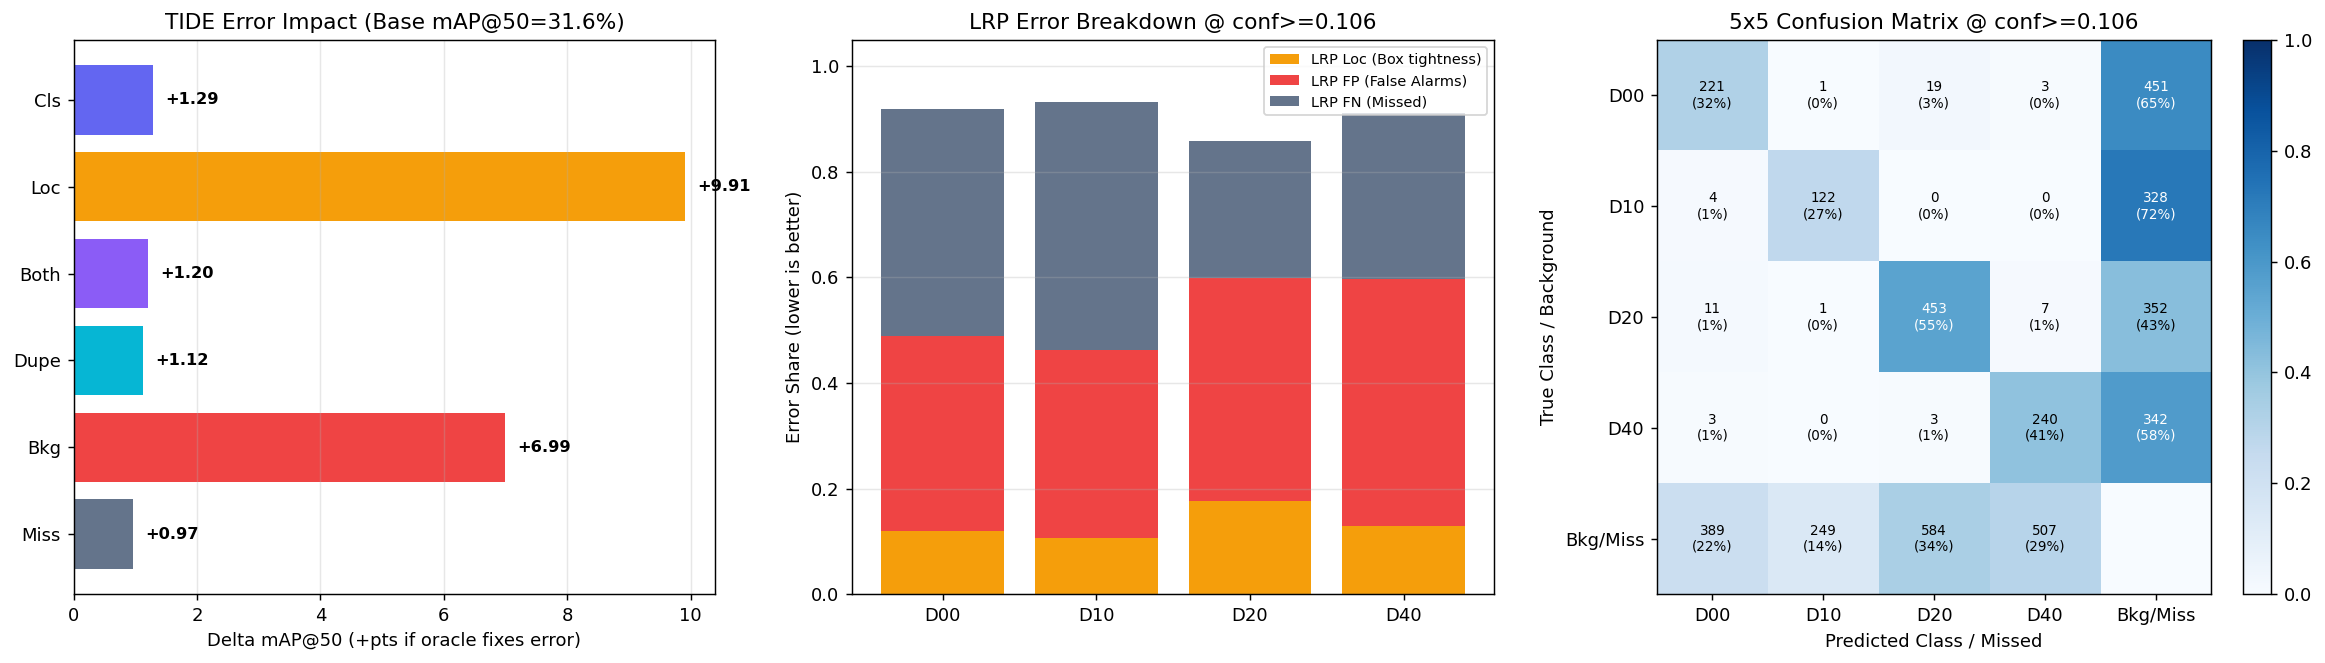

In [6]:
_execute_stage(1, 'CONF_FLOOR = float(EXP_CFG.get(\'conf_floor\', 0.001))\nIOU_NMS = float(EXP_CFG.get(\'iou_nms\', 0.6))\nMAX_DET = int(EXP_CFG.get(\'max_det\', 100))\nREUSE_CACHE = bool(EXP_CFG.get(\'reuse_cached_preds\', True))\n\nRAW_PRED_CSV_DRIVE = EA_OUT_DIR / \'val_pred_raw.csv\'\nRAW_PRED_CSV_LOCAL = CACHE_ROOT / \'target_models\' / TARGET_RUN_ID / \'val_pred_raw.csv\'\nRAW_PRED_CSV_LOCAL.parent.mkdir(parents=True, exist_ok=True)\n\ndetector = None\nif HAS_YOLO_CKPT:\n    detector = YOLO(str(BEST_PT_LOCAL))\n\npred_source_desc = \'\'\nif VAL_PRED_OVERRIDE:\n    ov_path = PROJECT_ROOT / VAL_PRED_OVERRIDE\n    if not ov_path.is_file():\n        raise FileNotFoundError(f\'val_pred_csv_override not found: {ov_path}\')\n    shutil.copy2(ov_path, RAW_PRED_CSV_LOCAL)\n    pred_source_desc = f\'override:{VAL_PRED_OVERRIDE}\'\nelif REUSE_CACHE and RAW_PRED_CSV_DRIVE.is_file():\n    shutil.copy2(RAW_PRED_CSV_DRIVE, RAW_PRED_CSV_LOCAL)\n    pred_source_desc = f\'cached:{RAW_PRED_CSV_DRIVE.name}\'\nelse:\n    if detector is None:\n        raise RuntimeError(\'Cannot run inference without YOLO checkpoint or cached predictions CSV.\')\n    rows_pred = []\n    ordered_paths = [str(val_path_map[iid]) for iid in val_ids]\n    t0_inf = time.monotonic()\n    for start in range(0, len(ordered_paths), BATCH_SIZE):\n        batch_p = ordered_paths[start:start + BATCH_SIZE]\n        batch_ids = val_ids[start:start + BATCH_SIZE]\n        res_list = detector.predict(\n            batch_p,\n            imgsz=IMGSZ,\n            conf=CONF_FLOOR,\n            iou=IOU_NMS,\n            max_det=MAX_DET,\n            agnostic_nms=False,\n            device=DEVICE,\n            verbose=False,\n            **FP16_KWARGS,\n        )\n        for iid, r in zip(batch_ids, res_list):\n            if r.boxes is None or len(r.boxes) == 0:\n                continue\n            xyxy = r.boxes.xyxy.detach().cpu().numpy()\n            confs = r.boxes.conf.detach().cpu().numpy()\n            clss = r.boxes.cls.detach().cpu().numpy().astype(np.int64)\n            for c, s, b in zip(clss, confs, xyxy):\n                x1, y1, x2, y2 = float(b[0]), float(b[1]), float(b[2]), float(b[3])\n                if x2 > x1 and y2 > y1:\n                    rows_pred.append((iid, int(c), round(float(s), 6), round(x1, 2), round(y1, 2), round(x2, 2), round(y2, 2)))\n        if (start + BATCH_SIZE) % (BATCH_SIZE * 30) == 0 or (start + BATCH_SIZE) >= len(ordered_paths):\n            done = min(start + BATCH_SIZE, len(ordered_paths))\n            print(f\'  Val inference: {done}/{len(ordered_paths)} ({done / max(0.01, time.monotonic() - t0_inf):.1f} img/s)\')\n    pred_out_df = pd.DataFrame(rows_pred, columns=official_score.PRED_COLS)\n    pred_out_df.to_csv(RAW_PRED_CSV_LOCAL, index=False)\n    shutil.copy2(RAW_PRED_CSV_LOCAL, RAW_PRED_CSV_DRIVE)\n    shutil.copy2(RAW_PRED_CSV_LOCAL, RUN_DRIVE_DIR / \'val_pred_raw.csv\')\n    pred_source_desc = f\'fresh_inference_{len(pred_out_df)}_boxes\'\n\nprint(\'Loaded validation predictions via:\', pred_source_desc)\npreds_dict = official_score.load_predictions(str(RAW_PRED_CSV_LOCAL), valid_ids=set(val_ids))\nbase_eval = official_score.evaluate(gt_dict, preds_dict, val_ids)\nbase_combined = official_score.combine(base_eval)\nOPT_THR = float(base_eval[\'confidence_threshold\'])\nBASE_MAP50 = float(base_eval[\'mAP50\'])\nBASE_ACC_SCORE = float(base_combined[\'accuracy_score\'])\n\nprint(f"Official Baseline Score -> Acc={BASE_ACC_SCORE:.2f}/100 | mAP@50={BASE_MAP50:.4f} | mAP@50:95={base_eval[\'mAP50_95\']:.4f} | P={base_eval[\'precision\']:.4f} | R={base_eval[\'recall\']:.4f} | opt_thr={OPT_THR:.3f}")\n\ndef _clip_top100(p_dict):\n    out = {}\n    for iid in val_ids:\n        d = p_dict.get(iid)\n        if d is not None and len(d) > 0:\n            if len(d) > official_score.MAX_DETS:\n                d = d[np.argsort(-d[:, 1], kind=\'stable\')[:official_score.MAX_DETS]]\n            out[iid] = d\n    return out\n\npreds_100 = _clip_top100(preds_dict)\n\ndef _fast_map50(gt_sub: dict, preds_sub: dict, ids_list: list[str]) -> tuple[float, dict[int, float]]:\n    n_gt = np.zeros(4, dtype=np.int64)\n    scores_c = [[] for _ in range(4)]\n    tps_c = [[] for _ in range(4)]\n    empty_b, empty_k = np.zeros((0, 4)), np.zeros(0, dtype=np.int64)\n    for iid in ids_list:\n        gb, gc = gt_sub.get(iid, (empty_b, empty_k))\n        d = preds_sub.get(iid)\n        for c in range(4):\n            g = gb[gc == c]\n            n_gt[c] += len(g)\n            if d is None or len(d) == 0:\n                continue\n            dc = d[d[:, 0] == c]\n            if len(dc) == 0:\n                continue\n            dc = dc[np.argsort(-dc[:, 1], kind=\'stable\')]\n            tp = np.zeros(len(dc), dtype=bool)\n            if len(g) > 0:\n                ious = official_score.box_iou(dc[:, 2:6], g)\n                matched = np.zeros(len(g), dtype=bool)\n                for di in range(len(dc)):\n                    cand = np.where(matched, -1.0, ious[di])\n                    j = int(np.argmax(cand))\n                    if cand[j] >= 0.50:\n                        matched[j] = True\n                        tp[di] = True\n            scores_c[c].append(dc[:, 1])\n            tps_c[c].append(tp)\n    per_c = {}\n    for c in range(4):\n        if n_gt[c] == 0:\n            continue\n        if scores_c[c]:\n            s = np.concatenate(scores_c[c])\n            tp = np.concatenate(tps_c[c])\n            ord_idx = np.argsort(-s, kind=\'stable\')\n            per_c[c] = official_score._average_precision(tp[ord_idx], int(n_gt[c]))\n        else:\n            per_c[c] = 0.0\n    return (float(np.mean(list(per_c.values()))) if per_c else 0.0), per_c\n\nfast_m50, _ = _fast_map50(gt_dict, preds_100, val_ids)\nassert abs(fast_m50 - BASE_MAP50) < 1e-6, f\'Fast mAP50 mismatch: {fast_m50} vs {BASE_MAP50}\'\n\n# Exact TIDE (Bolya et al., ECCV 2020) diagnosis: t_f=0.50, t_b=0.10\nTF, TB = 0.50, 0.10\ngt_records = []\ndet_records = []\ngt_uid_counter = 0\n\nfor iid in val_ids:\n    gb, gc = gt_dict.get(iid, (np.zeros((0, 4)), np.zeros(0, dtype=np.int64)))\n    n_g = len(gb)\n    img_gt_uids = list(range(gt_uid_counter, gt_uid_counter + n_g))\n    gt_uid_counter += n_g\n    matched_tp = np.zeros(n_g, dtype=bool)\n    matched_tp_conf = np.full(n_g, -1.0, dtype=np.float64)\n    matched_tp_iou = np.full(n_g, 0.0, dtype=np.float64)\n    covered_cls = np.zeros(n_g, dtype=bool)\n    covered_loc = np.zeros(n_g, dtype=bool)\n\n    d = preds_100.get(iid)\n    if d is not None and len(d) > 0:\n        # Sort within each class descending, tracking original slot\n        d_sorted_idx = np.argsort(-d[:, 1], kind=\'stable\')\n        d_ord = d[d_sorted_idx]\n        det_tags = [\'\'] * len(d_ord)\n        det_info = [None] * len(d_ord)\n\n        # Pass 1: greedy same-class TP matching at IoU >= 0.50 (matches score.py exactly)\n        for c in range(4):\n            g_mask = (gc == c)\n            g_indices = np.where(g_mask)[0]\n            d_indices = np.where(d_ord[:, 0].astype(np.int64) == c)[0]\n            if len(d_indices) == 0:\n                continue\n            if len(g_indices) > 0:\n                ious_cg = official_score.box_iou(d_ord[d_indices, 2:6], gb[g_indices])\n                local_matched = np.zeros(len(g_indices), dtype=bool)\n                for row_k, di in enumerate(d_indices):\n                    cand = np.where(local_matched, -1.0, ious_cg[row_k])\n                    best_k = int(np.argmax(cand))\n                    if cand[best_k] >= TF:\n                        local_matched[best_k] = True\n                        gi = int(g_indices[best_k])\n                        matched_tp[gi] = True\n                        matched_tp_conf[gi] = float(d_ord[di, 1])\n                        matched_tp_iou[gi] = float(cand[best_k])\n                        det_tags[di] = \'TP\'\n                        det_info[di] = {\'iou_match\': float(cand[best_k]), \'same_gt_idx\': gi, \'diff_gt_idx\': -1, \'diff_cls\': -1}\n\n        # Pass 2: classify all non-TP detections cleanly into TIDE buckets\n        all_ious = official_score.box_iou(d_ord[:, 2:6], gb) if n_g > 0 else np.zeros((len(d_ord), 0))\n        for di in range(len(d_ord)):\n            if det_tags[di] == \'TP\':\n                continue\n            c = int(d_ord[di, 0])\n            if n_g == 0:\n                det_tags[di] = \'Bkg\'\n                det_info[di] = {\'iou_match\': 0.0, \'same_gt_idx\': -1, \'diff_gt_idx\': -1, \'diff_cls\': -1}\n                continue\n            row_iou = all_ious[di]\n            same_mask = (gc == c)\n            diff_mask = ~same_mask\n            best_same_iou = float(row_iou[same_mask].max()) if np.any(same_mask) else 0.0\n            best_same_gi = int(np.where(same_mask)[0][np.argmax(row_iou[same_mask])]) if np.any(same_mask) else -1\n            best_diff_iou = float(row_iou[diff_mask].max()) if np.any(diff_mask) else 0.0\n            best_diff_gi = int(np.where(diff_mask)[0][np.argmax(row_iou[diff_mask])]) if np.any(diff_mask) else -1\n            best_diff_cls = int(gc[best_diff_gi]) if best_diff_gi >= 0 else -1\n\n            if best_same_iou >= TF:\n                det_tags[di] = \'Dupe\'\n                top_iou = best_same_iou\n            elif best_diff_iou >= TF:\n                det_tags[di] = \'Cls\'\n                covered_cls[best_diff_gi] = True\n                top_iou = best_diff_iou\n            elif best_same_iou >= TB:\n                det_tags[di] = \'Loc\'\n                covered_loc[best_same_gi] = True\n                top_iou = best_same_iou\n            elif best_diff_iou >= TB:\n                det_tags[di] = \'Both\'\n                top_iou = best_diff_iou\n            else:\n                det_tags[di] = \'Bkg\'\n                top_iou = max(best_same_iou, best_diff_iou)\n            det_info[di] = {\n                \'iou_match\': top_iou,\n                \'same_gt_idx\': best_same_gi,\n                \'diff_gt_idx\': best_diff_gi,\n                \'diff_cls\': best_diff_cls,\n            }\n\n        for di in range(len(d_ord)):\n            inf = det_info[di]\n            sg_idx = inf[\'same_gt_idx\']\n            dg_idx = inf[\'diff_gt_idx\']\n            det_records.append({\n                \'image_id\': iid,\n                \'is_damaged_img\': int(n_g > 0),\n                \'pred_cls\': int(d_ord[di, 0]),\n                \'score\': float(d_ord[di, 1]),\n                \'x1\': float(d_ord[di, 2]),\n                \'y1\': float(d_ord[di, 3]),\n                \'x2\': float(d_ord[di, 4]),\n                \'y2\': float(d_ord[di, 5]),\n                \'tide_tag\': det_tags[di],\n                \'iou_match\': float(inf[\'iou_match\']),\n                \'same_gt_uid\': img_gt_uids[sg_idx] if sg_idx >= 0 else -1,\n                \'diff_gt_uid\': img_gt_uids[dg_idx] if dg_idx >= 0 else -1,\n                \'diff_cls\': int(inf[\'diff_cls\']),\n            })\n\n    for gi in range(n_g):\n        gt_records.append({\n            \'gt_uid\': img_gt_uids[gi],\n            \'image_id\': iid,\n            \'gt_cls\': int(gc[gi]),\n            \'x1\': float(gb[gi, 0]),\n            \'y1\': float(gb[gi, 1]),\n            \'x2\': float(gb[gi, 2]),\n            \'y2\': float(gb[gi, 3]),\n            \'matched_tp\': int(matched_tp[gi]),\n            \'matched_tp_conf\': float(matched_tp_conf[gi]),\n            \'matched_tp_iou\': float(matched_tp_iou[gi]),\n            \'covered_cls\': int(covered_cls[gi]),\n            \'covered_loc\': int(covered_loc[gi]),\n            \'is_strict_miss\': int((not matched_tp[gi]) and (not covered_loc[gi]) and (not covered_cls[gi])),\n        })\n\nDET_COLS = [\n    \'image_id\', \'is_damaged_img\', \'pred_cls\', \'score\', \'x1\', \'y1\', \'x2\', \'y2\',\n    \'tide_tag\', \'iou_match\', \'same_gt_uid\', \'diff_gt_uid\', \'diff_cls\',\n]\nGT_REC_COLS = [\n    \'gt_uid\', \'image_id\', \'gt_cls\', \'x1\', \'y1\', \'x2\', \'y2\',\n    \'matched_tp\', \'matched_tp_conf\', \'matched_tp_iou\',\n    \'covered_cls\', \'covered_loc\', \'is_strict_miss\',\n]\ndet_df = pd.DataFrame(det_records, columns=DET_COLS)\ngt_df = pd.DataFrame(gt_records, columns=GT_REC_COLS)\ngt_box_by_uid = gt_df.set_index(\'gt_uid\')[[\'x1\', \'y1\', \'x2\', \'y2\']].to_dict(\'index\')\ngt_matched_uid_set = set(gt_df.loc[gt_df[\'matched_tp\'] == 1, \'gt_uid\'].astype(int).tolist())\n\n# Build TIDE Oracle dictionaries & compute Delta mAP@50\ndef _build_preds_from_det(df_sub: pd.DataFrame) -> dict:\n    out = {}\n    if df_sub.empty:\n        return out\n    for iid, grp in df_sub.groupby(\'image_id\', sort=False):\n        out[iid] = grp[[\'pred_cls\', \'score\', \'x1\', \'y1\', \'x2\', \'y2\']].to_numpy(dtype=np.float64)\n    return out\n\ndef _eval_tide_oracles():\n    oracles = {}\n    # 1. Suppress-based oracles\n    for tag in (\'Bkg\', \'Dupe\', \'Both\'):\n        sub = det_df[det_df[\'tide_tag\'] != tag]\n        m50, per_c = _fast_map50(gt_dict, _build_preds_from_det(sub), val_ids)\n        oracles[tag] = (m50 - BASE_MAP50) * 100.0\n\n    # 2. Cls Oracle: reclassify Cls detections to matched diff_cls, suppressing resulting duplicates\n    cls_df = det_df.copy()\n    cls_mask = cls_df[\'tide_tag\'] == \'Cls\'\n    cls_df.loc[cls_mask, \'pred_cls\'] = cls_df.loc[cls_mask, \'diff_cls\']\n    claimed_cls_uids = set(gt_matched_uid_set)\n    keep_mask = np.ones(len(cls_df), dtype=bool)\n    for idx in np.where(cls_mask.to_numpy())[0]:\n        uid = int(cls_df.iat[idx, cls_df.columns.get_loc(\'diff_gt_uid\')])\n        if uid in claimed_cls_uids:\n            keep_mask[idx] = False\n        else:\n            claimed_cls_uids.add(uid)\n    m50_cls, _ = _fast_map50(gt_dict, _build_preds_from_det(cls_df[keep_mask]), val_ids)\n    oracles[\'Cls\'] = (m50_cls - BASE_MAP50) * 100.0\n\n    # 3. Loc Oracle: snap Loc boxes to matched same-class GT boxes, suppressing duplicates\n    loc_df = det_df.copy()\n    loc_mask = loc_df[\'tide_tag\'] == \'Loc\'\n    claimed_loc_uids = set(gt_matched_uid_set)\n    keep_loc = np.ones(len(loc_df), dtype=bool)\n    for idx in np.where(loc_mask.to_numpy())[0]:\n        uid = int(loc_df.iat[idx, loc_df.columns.get_loc(\'same_gt_uid\')])\n        if uid < 0 or uid in claimed_loc_uids:\n            keep_loc[idx] = False\n        else:\n            claimed_loc_uids.add(uid)\n            gb_u = gt_box_by_uid[uid]\n            loc_df.iat[idx, loc_df.columns.get_loc(\'x1\')] = gb_u[\'x1\']\n            loc_df.iat[idx, loc_df.columns.get_loc(\'y1\')] = gb_u[\'y1\']\n            loc_df.iat[idx, loc_df.columns.get_loc(\'x2\')] = gb_u[\'x2\']\n            loc_df.iat[idx, loc_df.columns.get_loc(\'y2\')] = gb_u[\'y2\']\n    m50_loc, _ = _fast_map50(gt_dict, _build_preds_from_det(loc_df[keep_loc]), val_ids)\n    oracles[\'Loc\'] = (m50_loc - BASE_MAP50) * 100.0\n\n    # 4. Miss Oracle: remove strictly missed GTs (not TP, not Loc, not Cls)\n    gt_miss_sub = gt_df[gt_df[\'is_strict_miss\'] == 0]\n    gt_miss_dict = {}\n    for iid, grp in gt_miss_sub.groupby(\'image_id\', sort=False):\n        gt_miss_dict[iid] = (\n            grp[[\'x1\', \'y1\', \'x2\', \'y2\']].to_numpy(dtype=np.float64),\n            grp[\'gt_cls\'].to_numpy(dtype=np.int64),\n        )\n    m50_miss, _ = _fast_map50(gt_miss_dict, preds_100, val_ids)\n    oracles[\'Miss\'] = (m50_miss - BASE_MAP50) * 100.0\n\n    # 5. Special FalsePos & FalseNeg bounds\n    sub_fp = det_df[det_df[\'tide_tag\'] == \'TP\']\n    m50_fp, _ = _fast_map50(gt_dict, _build_preds_from_det(sub_fp), val_ids)\n    oracles[\'FalsePos\'] = (m50_fp - BASE_MAP50) * 100.0\n    gt_fn_sub = gt_df[gt_df[\'matched_tp\'] == 1]\n    gt_fn_dict = {iid: (grp[[\'x1\', \'y1\', \'x2\', \'y2\']].to_numpy(dtype=np.float64), grp[\'gt_cls\'].to_numpy(dtype=np.int64))\n                  for iid, grp in gt_fn_sub.groupby(\'image_id\', sort=False)}\n    m50_fn, _ = _fast_map50(gt_fn_dict, preds_100, val_ids)\n    oracles[\'FalseNeg\'] = (m50_fn - BASE_MAP50) * 100.0\n    return {k: round(float(v), 4) for k, v in oracles.items()}\n\ntide_deltas = _eval_tide_oracles()\nprint(\'TIDE Oracle Delta mAP@50 (+pts if fixed):\', json.dumps(tide_deltas, indent=2))\n\n# LRP decomposition + 5x5 Box-Level Confusion Matrix at OPT_THR\nlrp_per_class = {}\nconf_mat_5x5 = np.zeros((5, 5), dtype=np.int64)  # rows=GT(0..3, Bkg=4), cols=Pred(0..3, Miss=4)\ndet_thr = det_df[det_df[\'score\'] >= OPT_THR].copy()\nfor iid in val_ids:\n    gb, gc = gt_dict.get(iid, (np.zeros((0, 4)), np.zeros(0, dtype=np.int64)))\n    sub_d = det_thr[det_thr[\'image_id\'] == iid].sort_values(\'score\', ascending=False)\n    gt_matched_any = np.zeros(len(gb), dtype=bool)\n    if len(sub_d) > 0 and len(gb) > 0:\n        iou_m = official_score.box_iou(sub_d[[\'x1\', \'y1\', \'x2\', \'y2\']].to_numpy(), gb)\n        # First pass greedy same-class matching, then greedy cross-class matching for visualization\n        d_clss = sub_d[\'pred_cls\'].to_numpy(dtype=np.int64)\n        used_d = np.zeros(len(sub_d), dtype=bool)\n        for r_i, p_c in enumerate(d_clss):\n            cand = np.where((~gt_matched_any) & (gc == p_c), iou_m[r_i], -1.0)\n            best_j = int(np.argmax(cand))\n            if cand[best_j] >= 0.50:\n                gt_matched_any[best_j] = True\n                used_d[r_i] = True\n                conf_mat_5x5[int(gc[best_j]), int(p_c)] += 1\n        for r_i, p_c in enumerate(d_clss):\n            if used_d[r_i]:\n                continue\n            cand = np.where(~gt_matched_any, iou_m[r_i], -1.0)\n            best_j = int(np.argmax(cand))\n            if cand[best_j] >= 0.50:\n                gt_matched_any[best_j] = True\n                conf_mat_5x5[int(gc[best_j]), int(p_c)] += 1\n            else:\n                conf_mat_5x5[4, int(p_c)] += 1  # Background FP\n    elif len(sub_d) > 0:\n        for p_c in sub_d[\'pred_cls\'].to_numpy(dtype=np.int64):\n            conf_mat_5x5[4, int(p_c)] += 1\n    for gi, matched in enumerate(gt_matched_any):\n        if not matched:\n            conf_mat_5x5[int(gc[gi]), 4] += 1  # Missed GT\n\nfor c in range(4):\n    sub_gt_c = gt_df[gt_df[\'gt_cls\'] == c]\n    sub_tp_c = sub_gt_c[(sub_gt_c[\'matched_tp\'] == 1) & (sub_gt_c[\'matched_tp_conf\'] >= OPT_THR)]\n    n_tp = int(len(sub_tp_c))\n    n_tp_cm = int(conf_mat_5x5[c, c])\n    n_fp_cm = int(conf_mat_5x5[:, c].sum() - n_tp_cm)\n    n_fn_cm = int(conf_mat_5x5[c, :].sum() - n_tp_cm)\n    z = max(1, n_tp_cm + n_fp_cm + n_fn_cm)\n    loc_sum = float(((1.0 - np.clip(sub_tp_c[\'matched_tp_iou\'].to_numpy(), 0.5, 1.0)) / 0.5).sum()) if n_tp > 0 else 0.0\n    lrp_loc = loc_sum / z\n    lrp_fp = n_fp_cm / z\n    lrp_fn = n_fn_cm / z\n    lrp_per_class[CLASS_CODES[c]] = {\n        \'LRP_total\': round(lrp_loc + lrp_fp + lrp_fn, 4),\n        \'LRP_Loc\': round(lrp_loc, 4),\n        \'LRP_FP\': round(lrp_fp, 4),\n        \'LRP_FN\': round(lrp_fn, 4),\n        \'TP\': n_tp_cm, \'FP\': n_fp_cm, \'FN\': n_fn_cm,\n    }\n\nfig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=130)\nmain_keys = [\'Cls\', \'Loc\', \'Both\', \'Dupe\', \'Bkg\', \'Miss\']\nvals = [tide_deltas[k] for k in main_keys]\ncolors_tide = [\'#6366f1\', \'#f59e0b\', \'#8b5cf6\', \'#06b6d4\', \'#ef4444\', \'#64748b\']\nbars = axes[0].barh(main_keys, vals, color=colors_tide)\naxes[0].invert_yaxis()\naxes[0].set_xlabel(\'Delta mAP@50 (+pts if oracle fixes error)\')\naxes[0].set_title(f\'TIDE Error Impact (Base mAP@50={BASE_MAP50*100:.1f}%)\')\naxes[0].grid(axis=\'x\', alpha=0.3)\npad_x = max(0.05, max(vals) * 0.02)\nfor b, v in zip(bars, vals):\n    axes[0].text(v + pad_x, b.get_y() + b.get_height() / 2, f\'+{v:.2f}\', va=\'center\', fontsize=9, fontweight=\'bold\')\n\nc_codes = [CLASS_CODES[c] for c in range(4)]\nl_loc = [lrp_per_class[k][\'LRP_Loc\'] for k in c_codes]\nl_fp = [lrp_per_class[k][\'LRP_FP\'] for k in c_codes]\nl_fn = [lrp_per_class[k][\'LRP_FN\'] for k in c_codes]\nx_c = np.arange(4)\naxes[1].bar(x_c, l_loc, label=\'LRP Loc (Box tightness)\', color=\'#f59e0b\')\naxes[1].bar(x_c, l_fp, bottom=l_loc, label=\'LRP FP (False Alarms)\', color=\'#ef4444\')\naxes[1].bar(x_c, l_fn, bottom=np.array(l_loc) + np.array(l_fp), label=\'LRP FN (Missed)\', color=\'#64748b\')\naxes[1].set_xticks(x_c)\naxes[1].set_xticklabels(c_codes)\naxes[1].set_ylim(0, 1.05)\naxes[1].set_ylabel(\'Error Share (lower is better)\')\naxes[1].set_title(f\'LRP Error Breakdown @ conf>={OPT_THR:.3f}\')\naxes[1].legend(fontsize=8)\naxes[1].grid(axis=\'y\', alpha=0.3)\n\ncm_norm = conf_mat_5x5 / np.maximum(1, conf_mat_5x5.sum(axis=1, keepdims=True))\nim = axes[2].imshow(cm_norm, cmap=\'Blues\', vmin=0.0, vmax=1.0)\nlbls5 = [\'D00\', \'D10\', \'D20\', \'D40\', \'Bkg/Miss\']\naxes[2].set_xticks(range(5))\naxes[2].set_yticks(range(5))\naxes[2].set_xticklabels(lbls5)\naxes[2].set_yticklabels(lbls5)\naxes[2].set_xlabel(\'Predicted Class / Missed\')\naxes[2].set_ylabel(\'True Class / Background\')\naxes[2].set_title(f\'5x5 Confusion Matrix @ conf>={OPT_THR:.3f}\')\nfor r in range(5):\n    for c_i in range(5):\n        if r == 4 and c_i == 4:\n            continue\n        axes[2].text(c_i, r, f"{conf_mat_5x5[r, c_i]}\\n({cm_norm[r, c_i]*100:.0f}%)",\n                     ha=\'center\', va=\'center\', fontsize=7.5,\n                     color=\'white\' if cm_norm[r, c_i] > 0.5 else \'black\')\nfig.colorbar(im, ax=axes[2], fraction=0.046)\nplt.tight_layout()\nsave_ea_plot(fig, \'01_tide_oracle_and_confusion_matrix.png\', \'plot_tide_and_confusion\')\ncheck_budget()')


## 3. Clean Road vs. Defect Road Separation Gate (Image-Level ROC & FP Audit)
Evaluate whether the detector can cleanly distinguish undamaged vs damaged roads across thresholds (ROC-AUC, PR-AUC, clean-road false alarm rate by class).

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# Clean Road vs Defect Road Separation (Image-Level Binary Classification)
img_rows = []
grp_det = det_df.groupby('image_id') if not det_df.empty else None
for iid in val_ids:
    is_dam = int(iid in gt_dict)
    n_gt_i = int(len(gt_dict[iid][0])) if is_dam else 0
    if grp_det is not None and iid in grp_det.groups:
        sub = grp_det.get_group(iid)
        max_conf = float(sub['score'].max())
        top1_idx = int(sub['score'].idxmax())
        top1_cls = int(sub.loc[top1_idx, 'pred_cls'])
        n_opt = int((sub['score'] >= OPT_THR).sum())
        n_25 = int((sub['score'] >= 0.25).sum())
        n_bkg_opt = int(((sub['score'] >= OPT_THR) & (sub['tide_tag'] == 'Bkg')).sum())
    else:
        max_conf, top1_cls, n_opt, n_25, n_bkg_opt = 0.0, -1, 0, 0, 0
    img_rows.append({
        'image_id': iid,
        'is_damaged': is_dam,
        'n_gt': n_gt_i,
        'max_conf': max_conf,
        'top1_cls': top1_cls,
        'n_boxes_opt': n_opt,
        'n_boxes_025': n_25,
        'n_bkg_opt': n_bkg_opt,
    })

img_gate_df = pd.DataFrame(img_rows)
y_true_img = img_gate_df['is_damaged'].to_numpy(dtype=np.int64)
y_score_img = img_gate_df['max_conf'].to_numpy(dtype=np.float64)

roc_auc_img = float(roc_auc_score(y_true_img, y_score_img))
pr_auc_img = float(average_precision_score(y_true_img, y_score_img))
fpr_arr, tpr_arr, roc_thrs = roc_curve(y_true_img, y_score_img)
youden_idx = int(np.argmax(tpr_arr - fpr_arr))
youden_thr = float(roc_thrs[youden_idx])

gate_sweep = []
for thr in [0.05, OPT_THR, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    yp = (y_score_img >= thr).astype(np.int64)
    tn, fp, fn, tp = sk_confusion_matrix(y_true_img, yp, labels=[0, 1]).ravel()
    tpr = tp / max(1, tp + fn)
    tnr = tn / max(1, tn + fp)
    prec_i = tp / max(1, tp + fp)
    f1_i = 2 * prec_i * tpr / max(1e-12, prec_i + tpr)
    gate_sweep.append({
        'thr': round(float(thr), 3),
        'TP_damaged': int(tp),
        'FN_missed_road': int(fn),
        'TN_clean': int(tn),
        'FP_clean_alarm': int(fp),
        'damaged_recall': round(float(tpr), 4),
        'clean_specificity': round(float(tnr), 4),
        'clean_fp_rate': round(float(1.0 - tnr), 4),
        'image_precision': round(float(prec_i), 4),
        'image_f1': round(float(f1_i), 4),
    })

gate_sweep_df = pd.DataFrame(gate_sweep)
opt_row = gate_sweep_df.loc[(gate_sweep_df['thr'] - OPT_THR).abs().idxmin()]
CLEAN_FP_RATE_OPT = float(opt_row['clean_fp_rate'])
print(f'Image-Level Clean vs Defect Separation -> ROC-AUC={roc_auc_img:.4f} | PR-AUC={pr_auc_img:.4f} | Youden opt gate={youden_thr:.3f}')
print(gate_sweep_df.to_string(index=False))

clean_det_opt = det_df[(det_df['is_damaged_img'] == 0) & (det_df['score'] >= OPT_THR)]
clean_fp_by_cls = {CLASS_CODES[c]: int((clean_det_opt['pred_cls'] == c).sum()) for c in range(4)}

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.5), dpi=130)
axes[0, 0].plot(fpr_arr, tpr_arr, color='#2563eb', lw=2.2, label=f'ROC AUC = {roc_auc_img:.4f}')
axes[0, 0].plot([0, 1], [0, 1], '--', color='gray', lw=1)
axes[0, 0].scatter([fpr_arr[youden_idx]], [tpr_arr[youden_idx]], color='#dc2626', s=60, zorder=5, label=f'Youden Best={youden_thr:.3f}')
axes[0, 0].set_xlabel('Clean Road False Positive Rate (1 - Specificity)')
axes[0, 0].set_ylabel('Damaged Road Recall (TPR)')
axes[0, 0].set_title('Image-Level Clean vs Defect Road ROC')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

clean_scores = img_gate_df.loc[img_gate_df['is_damaged'] == 0, 'max_conf']
dam_scores = img_gate_df.loc[img_gate_df['is_damaged'] == 1, 'max_conf']
axes[0, 1].hist(clean_scores, bins=30, range=(0, 1), density=True, alpha=0.55, color='#16a34a', label=f'Clean Roads (n={len(clean_scores)})')
axes[0, 1].hist(dam_scores, bins=30, range=(0, 1), density=True, alpha=0.55, color='#dc2626', label=f'Damaged Roads (n={len(dam_scores)})')
axes[0, 1].axvline(OPT_THR, color='black', linestyle='--', lw=1.4, label=f'F1 opt_thr={OPT_THR:.3f}')
axes[0, 1].set_xlabel('Max Predicted Box Confidence per Image')
axes[0, 1].set_ylabel('Density')
axes[0, 1].set_title('Separation of Clean vs Damaged Score Distributions')
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(alpha=0.25)

cm_img = sk_confusion_matrix(y_true_img, (y_score_img >= OPT_THR).astype(np.int64), labels=[0, 1])
im_g = axes[1, 0].imshow(cm_img, cmap='Oranges')
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_yticks([0, 1])
axes[1, 0].set_xticklabels(['Pred Clean', 'Pred Damaged'])
axes[1, 0].set_yticklabels(['True Clean', 'True Damaged'])
axes[1, 0].set_title(f'Image-Level Confusion @ thr={OPT_THR:.3f} (Clean FP={CLEAN_FP_RATE_OPT*100:.1f}%)')
for r_i in range(2):
    for c_i in range(2):
        axes[1, 0].text(c_i, r_i, f'{cm_img[r_i, c_i]}', ha='center', va='center', fontsize=12, fontweight='bold',
                        color='white' if cm_img[r_i, c_i] > cm_img.max() * 0.5 else 'black')

axes[1, 1].bar(list(clean_fp_by_cls.keys()), list(clean_fp_by_cls.values()), color=[CLASS_COLORS[c] for c in range(4)])
axes[1, 1].set_ylabel(f'False Boxes on Clean Roads (conf >= {OPT_THR:.3f})')
axes[1, 1].set_title('Which Classes Trigger Clean-Road Hallucinations?')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
save_ea_plot(fig, '02_clean_vs_defect_road_separation.png', 'plot_clean_vs_defect')
check_budget()
```


Image-Level Clean vs Defect Separation -> ROC-AUC=0.9015 | PR-AUC=0.9297 | Youden opt gate=0.097
  thr  TP_damaged  FN_missed_road  TN_clean  FP_clean_alarm  damaged_recall  clean_specificity  clean_fp_rate  image_precision  image_f1
0.050        1146             108       573             323          0.9139             0.6395         0.3605           0.7801    0.8417
0.106        1014             240       754             142          0.8086             0.8415         0.1585           0.8772    0.8415
0.150         878             376       815              81          0.7002             0.9096         0.0904           0.9155    0.7935
0.200         749             505       854              42          0.5973             0.9531         0.0469           0.9469    0.7325
0.250         610             644       869              27          0.4864             0.9699         0.0301           0.9576    0.6452
0.300         487             767       883              13          0.3884      

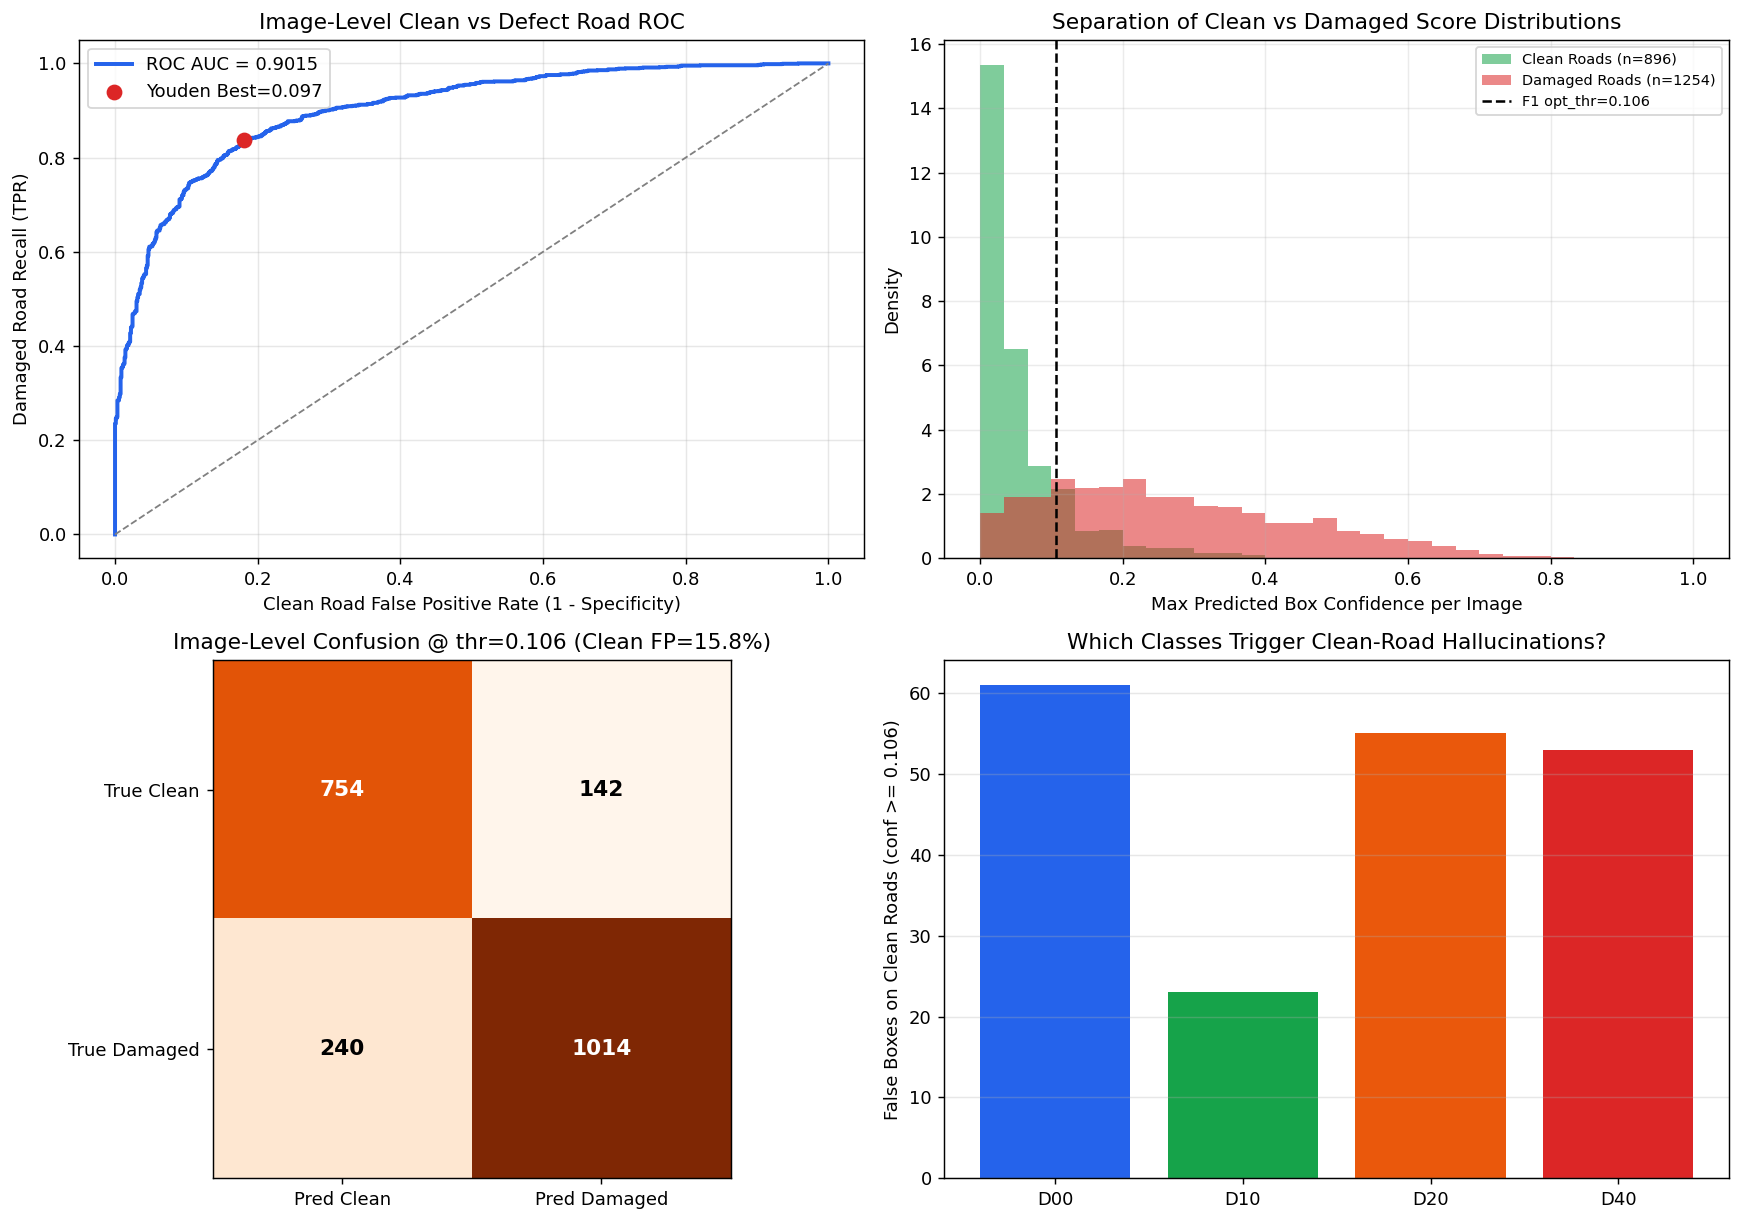

In [7]:
_execute_stage(2, "# Clean Road vs Defect Road Separation (Image-Level Binary Classification)\nimg_rows = []\ngrp_det = det_df.groupby('image_id') if not det_df.empty else None\nfor iid in val_ids:\n    is_dam = int(iid in gt_dict)\n    n_gt_i = int(len(gt_dict[iid][0])) if is_dam else 0\n    if grp_det is not None and iid in grp_det.groups:\n        sub = grp_det.get_group(iid)\n        max_conf = float(sub['score'].max())\n        top1_idx = int(sub['score'].idxmax())\n        top1_cls = int(sub.loc[top1_idx, 'pred_cls'])\n        n_opt = int((sub['score'] >= OPT_THR).sum())\n        n_25 = int((sub['score'] >= 0.25).sum())\n        n_bkg_opt = int(((sub['score'] >= OPT_THR) & (sub['tide_tag'] == 'Bkg')).sum())\n    else:\n        max_conf, top1_cls, n_opt, n_25, n_bkg_opt = 0.0, -1, 0, 0, 0\n    img_rows.append({\n        'image_id': iid,\n        'is_damaged': is_dam,\n        'n_gt': n_gt_i,\n        'max_conf': max_conf,\n        'top1_cls': top1_cls,\n        'n_boxes_opt': n_opt,\n        'n_boxes_025': n_25,\n        'n_bkg_opt': n_bkg_opt,\n    })\n\nimg_gate_df = pd.DataFrame(img_rows)\ny_true_img = img_gate_df['is_damaged'].to_numpy(dtype=np.int64)\ny_score_img = img_gate_df['max_conf'].to_numpy(dtype=np.float64)\n\nroc_auc_img = float(roc_auc_score(y_true_img, y_score_img))\npr_auc_img = float(average_precision_score(y_true_img, y_score_img))\nfpr_arr, tpr_arr, roc_thrs = roc_curve(y_true_img, y_score_img)\nyouden_idx = int(np.argmax(tpr_arr - fpr_arr))\nyouden_thr = float(roc_thrs[youden_idx])\n\ngate_sweep = []\nfor thr in [0.05, OPT_THR, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:\n    yp = (y_score_img >= thr).astype(np.int64)\n    tn, fp, fn, tp = sk_confusion_matrix(y_true_img, yp, labels=[0, 1]).ravel()\n    tpr = tp / max(1, tp + fn)\n    tnr = tn / max(1, tn + fp)\n    prec_i = tp / max(1, tp + fp)\n    f1_i = 2 * prec_i * tpr / max(1e-12, prec_i + tpr)\n    gate_sweep.append({\n        'thr': round(float(thr), 3),\n        'TP_damaged': int(tp),\n        'FN_missed_road': int(fn),\n        'TN_clean': int(tn),\n        'FP_clean_alarm': int(fp),\n        'damaged_recall': round(float(tpr), 4),\n        'clean_specificity': round(float(tnr), 4),\n        'clean_fp_rate': round(float(1.0 - tnr), 4),\n        'image_precision': round(float(prec_i), 4),\n        'image_f1': round(float(f1_i), 4),\n    })\n\ngate_sweep_df = pd.DataFrame(gate_sweep)\nopt_row = gate_sweep_df.loc[(gate_sweep_df['thr'] - OPT_THR).abs().idxmin()]\nCLEAN_FP_RATE_OPT = float(opt_row['clean_fp_rate'])\nprint(f'Image-Level Clean vs Defect Separation -> ROC-AUC={roc_auc_img:.4f} | PR-AUC={pr_auc_img:.4f} | Youden opt gate={youden_thr:.3f}')\nprint(gate_sweep_df.to_string(index=False))\n\nclean_det_opt = det_df[(det_df['is_damaged_img'] == 0) & (det_df['score'] >= OPT_THR)]\nclean_fp_by_cls = {CLASS_CODES[c]: int((clean_det_opt['pred_cls'] == c).sum()) for c in range(4)}\n\nfig, axes = plt.subplots(2, 2, figsize=(13.5, 9.5), dpi=130)\naxes[0, 0].plot(fpr_arr, tpr_arr, color='#2563eb', lw=2.2, label=f'ROC AUC = {roc_auc_img:.4f}')\naxes[0, 0].plot([0, 1], [0, 1], '--', color='gray', lw=1)\naxes[0, 0].scatter([fpr_arr[youden_idx]], [tpr_arr[youden_idx]], color='#dc2626', s=60, zorder=5, label=f'Youden Best={youden_thr:.3f}')\naxes[0, 0].set_xlabel('Clean Road False Positive Rate (1 - Specificity)')\naxes[0, 0].set_ylabel('Damaged Road Recall (TPR)')\naxes[0, 0].set_title('Image-Level Clean vs Defect Road ROC')\naxes[0, 0].legend()\naxes[0, 0].grid(alpha=0.3)\n\nclean_scores = img_gate_df.loc[img_gate_df['is_damaged'] == 0, 'max_conf']\ndam_scores = img_gate_df.loc[img_gate_df['is_damaged'] == 1, 'max_conf']\naxes[0, 1].hist(clean_scores, bins=30, range=(0, 1), density=True, alpha=0.55, color='#16a34a', label=f'Clean Roads (n={len(clean_scores)})')\naxes[0, 1].hist(dam_scores, bins=30, range=(0, 1), density=True, alpha=0.55, color='#dc2626', label=f'Damaged Roads (n={len(dam_scores)})')\naxes[0, 1].axvline(OPT_THR, color='black', linestyle='--', lw=1.4, label=f'F1 opt_thr={OPT_THR:.3f}')\naxes[0, 1].set_xlabel('Max Predicted Box Confidence per Image')\naxes[0, 1].set_ylabel('Density')\naxes[0, 1].set_title('Separation of Clean vs Damaged Score Distributions')\naxes[0, 1].legend(fontsize=8)\naxes[0, 1].grid(alpha=0.25)\n\ncm_img = sk_confusion_matrix(y_true_img, (y_score_img >= OPT_THR).astype(np.int64), labels=[0, 1])\nim_g = axes[1, 0].imshow(cm_img, cmap='Oranges')\naxes[1, 0].set_xticks([0, 1])\naxes[1, 0].set_yticks([0, 1])\naxes[1, 0].set_xticklabels(['Pred Clean', 'Pred Damaged'])\naxes[1, 0].set_yticklabels(['True Clean', 'True Damaged'])\naxes[1, 0].set_title(f'Image-Level Confusion @ thr={OPT_THR:.3f} (Clean FP={CLEAN_FP_RATE_OPT*100:.1f}%)')\nfor r_i in range(2):\n    for c_i in range(2):\n        axes[1, 0].text(c_i, r_i, f'{cm_img[r_i, c_i]}', ha='center', va='center', fontsize=12, fontweight='bold',\n                        color='white' if cm_img[r_i, c_i] > cm_img.max() * 0.5 else 'black')\n\naxes[1, 1].bar(list(clean_fp_by_cls.keys()), list(clean_fp_by_cls.values()), color=[CLASS_COLORS[c] for c in range(4)])\naxes[1, 1].set_ylabel(f'False Boxes on Clean Roads (conf >= {OPT_THR:.3f})')\naxes[1, 1].set_title('Which Classes Trigger Clean-Road Hallucinations?')\naxes[1, 1].grid(axis='y', alpha=0.3)\n\nplt.tight_layout()\nsave_ea_plot(fig, '02_clean_vs_defect_road_separation.png', 'plot_clean_vs_defect')\ncheck_budget()")


## 4. Detection Calibration (D-ECE, arXiv:2312.06645) & Conf-vs-IoU Audit
Compute Detection Expected Calibration Error (D-ECE) overall, per class, and per scale, plus Spearman correlation between predicted confidence and box tightness (IoU).

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# Detection Calibration (D-ECE, arXiv:2312.06645 & arXiv:2611.00071) and Conf-vs-IoU Audit
def compute_dece_and_bins(df_in: pd.DataFrame, min_conf: float = 0.05, n_bins: int = 10):
    sub = df_in[df_in['score'] >= min_conf]
    if sub.empty:
        return 0.0, 0.0, pd.DataFrame()
    scores = sub['score'].to_numpy(dtype=np.float64)
    tps = (sub['tide_tag'] == 'TP').to_numpy(dtype=np.float64)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_rows = []
    dece = 0.0
    n_tot = len(scores)
    for bi in range(n_bins):
        lo, hi = edges[bi], edges[bi + 1]
        m = (scores >= lo) & (scores < hi if bi < n_bins - 1 else scores <= hi)
        cnt = int(m.sum())
        if cnt > 0:
            avg_c = float(scores[m].mean())
            acc = float(tps[m].mean())
            dece += (cnt / n_tot) * abs(acc - avg_c)
        else:
            avg_c, acc = float((lo + hi) * 0.5), 0.0
        bin_rows.append({'bin_mid': round((lo + hi) * 0.5, 2), 'count': cnt, 'mean_conf': avg_c, 'emp_acc': acc})
    overconf_gap = float(scores.mean() - tps.mean())
    return float(dece), overconf_gap, pd.DataFrame(bin_rows)

DECE_OVERALL, OVERCONF_GAP, dece_bins_df = compute_dece_and_bins(det_df, min_conf=0.05, n_bins=10)
DECE_ALL_RAW, _, _ = compute_dece_and_bins(det_df, min_conf=0.001, n_bins=10)
dece_per_class = {}
for c in range(4):
    d_c, oc_c, _ = compute_dece_and_bins(det_df[det_df['pred_cls'] == c], min_conf=0.05, n_bins=10)
    dece_per_class[CLASS_CODES[c]] = {'dece': round(d_c, 4), 'overconf_gap': round(oc_c, 4)}

# Confidence vs IoU tightness check (matched detections with iou >= 0.10)
matched_dets = det_df[det_df['tide_tag'].isin(['TP', 'Loc'])].copy()
if len(matched_dets) >= 5:
    conf_iou_spearman = float(matched_dets['score'].corr(matched_dets['iou_match'], method='spearman'))
    conf_iou_pearson = float(matched_dets['score'].corr(matched_dets['iou_match'], method='pearson'))
    if not np.isfinite(conf_iou_spearman):
        conf_iou_spearman = 0.0
    if not np.isfinite(conf_iou_pearson):
        conf_iou_pearson = 0.0
else:
    conf_iou_spearman, conf_iou_pearson = 0.0, 0.0

# Scale-stratified D-ECE
det_df['area_px'] = (det_df['x2'] - det_df['x1']) * (det_df['y2'] - det_df['y1'])
det_df['coco_scale'] = np.where(det_df['area_px'] < 1024.0, 'Small (<32^2)',
                                np.where(det_df['area_px'] <= 9216.0, 'Medium', 'Large (>96^2)'))
dece_by_scale = {}
for sc_name in ['Small (<32^2)', 'Medium', 'Large (>96^2)']:
    d_s, oc_s, _ = compute_dece_and_bins(det_df[det_df['coco_scale'] == sc_name], min_conf=0.05, n_bins=10)
    dece_by_scale[sc_name] = {'dece': round(d_s, 4), 'overconf_gap': round(oc_s, 4), 'n': int((det_df['coco_scale'] == sc_name).sum())}

print(f'D-ECE (>=0.05): {DECE_OVERALL:.4f} | Overconfidence Gap: {OVERCONF_GAP:+.4f} | Conf-IoU Spearman: {conf_iou_spearman:.4f}')
print('Per-Class D-ECE:', json.dumps(dece_per_class))
print('Per-Scale D-ECE:', json.dumps(dece_by_scale))

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9), dpi=130)
non_empty = dece_bins_df[dece_bins_df['count'] > 0]
axes[0, 0].plot([0, 1], [0, 1], '--', color='gray', label='Perfect Calibration')
axes[0, 0].bar(non_empty['bin_mid'], non_empty['emp_acc'], width=0.08, alpha=0.7, color='#2563eb', label='Empirical Precision (TP@50)')
axes[0, 0].plot(non_empty['mean_conf'], non_empty['emp_acc'], 'o-', color='#dc2626', lw=2, label=f'D-ECE = {DECE_OVERALL:.4f}')
axes[0, 0].set_xlabel('Predicted Confidence')
axes[0, 0].set_ylabel('True Positive Rate @ IoU=0.50')
axes[0, 0].set_title(f'Detection Reliability Diagram (conf>=0.05, Gap={OVERCONF_GAP:+.3f})')
axes[0, 0].legend(fontsize=8)
axes[0, 0].grid(alpha=0.3)

for c in range(4):
    _, _, b_c = compute_dece_and_bins(det_df[det_df['pred_cls'] == c], min_conf=0.05, n_bins=10)
    ne = b_c[b_c['count'] > 0]
    if not ne.empty:
        axes[0, 1].plot(ne['mean_conf'], ne['emp_acc'], 'o-', color=CLASS_COLORS[c], label=f"{CLASS_CODES[c]} (ECE={dece_per_class[CLASS_CODES[c]]['dece']:.3f})")
axes[0, 1].plot([0, 1], [0, 1], '--', color='gray')
axes[0, 1].set_xlabel('Predicted Confidence')
axes[0, 1].set_ylabel('Empirical TP@50 Rate')
axes[0, 1].set_title('Per-Class Reliability Curves')
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(alpha=0.3)

if not matched_dets.empty:
    samp_m = matched_dets.sample(n=min(3000, len(matched_dets)), random_state=SEED)
    axes[1, 0].scatter(samp_m['score'], samp_m['iou_match'], s=10, alpha=0.28, color='#0f766e')
    axes[1, 0].axhline(0.50, color='black', linestyle='--', lw=1, label='TP IoU=0.50')
axes[1, 0].set_xlabel('Confidence Score')
axes[1, 0].set_ylabel('Matched GT IoU')
axes[1, 0].set_title(f'Confidence vs Box Tightness (Spearman r={conf_iou_spearman:.3f})')
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(alpha=0.3)

sc_names = list(dece_by_scale.keys())
axes[1, 1].bar(sc_names, [dece_by_scale[k]['dece'] for k in sc_names], color=['#ef4444', '#f59e0b', '#10b981'])
axes[1, 1].set_ylabel('D-ECE (lower = better calibrated)')
axes[1, 1].set_title('Calibration Error by Object Scale')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
save_ea_plot(fig, '03_detection_calibration_dece.png', 'plot_calibration_dece')
check_budget()
```


D-ECE (>=0.05): 0.0746 | Overconfidence Gap: -0.0746 | Conf-IoU Spearman: 0.3253
Per-Class D-ECE: {"D00": {"dece": 0.0791, "overconf_gap": -0.0791}, "D10": {"dece": 0.0699, "overconf_gap": -0.0695}, "D20": {"dece": 0.0945, "overconf_gap": -0.0945}, "D40": {"dece": 0.0488, "overconf_gap": -0.0488}}
Per-Scale D-ECE: {"Small (<32^2)": {"dece": 0.0571, "overconf_gap": -0.0562, "n": 5985}, "Medium": {"dece": 0.0731, "overconf_gap": -0.0731, "n": 62390}, "Large (>96^2)": {"dece": 0.078, "overconf_gap": -0.078, "n": 40921}}


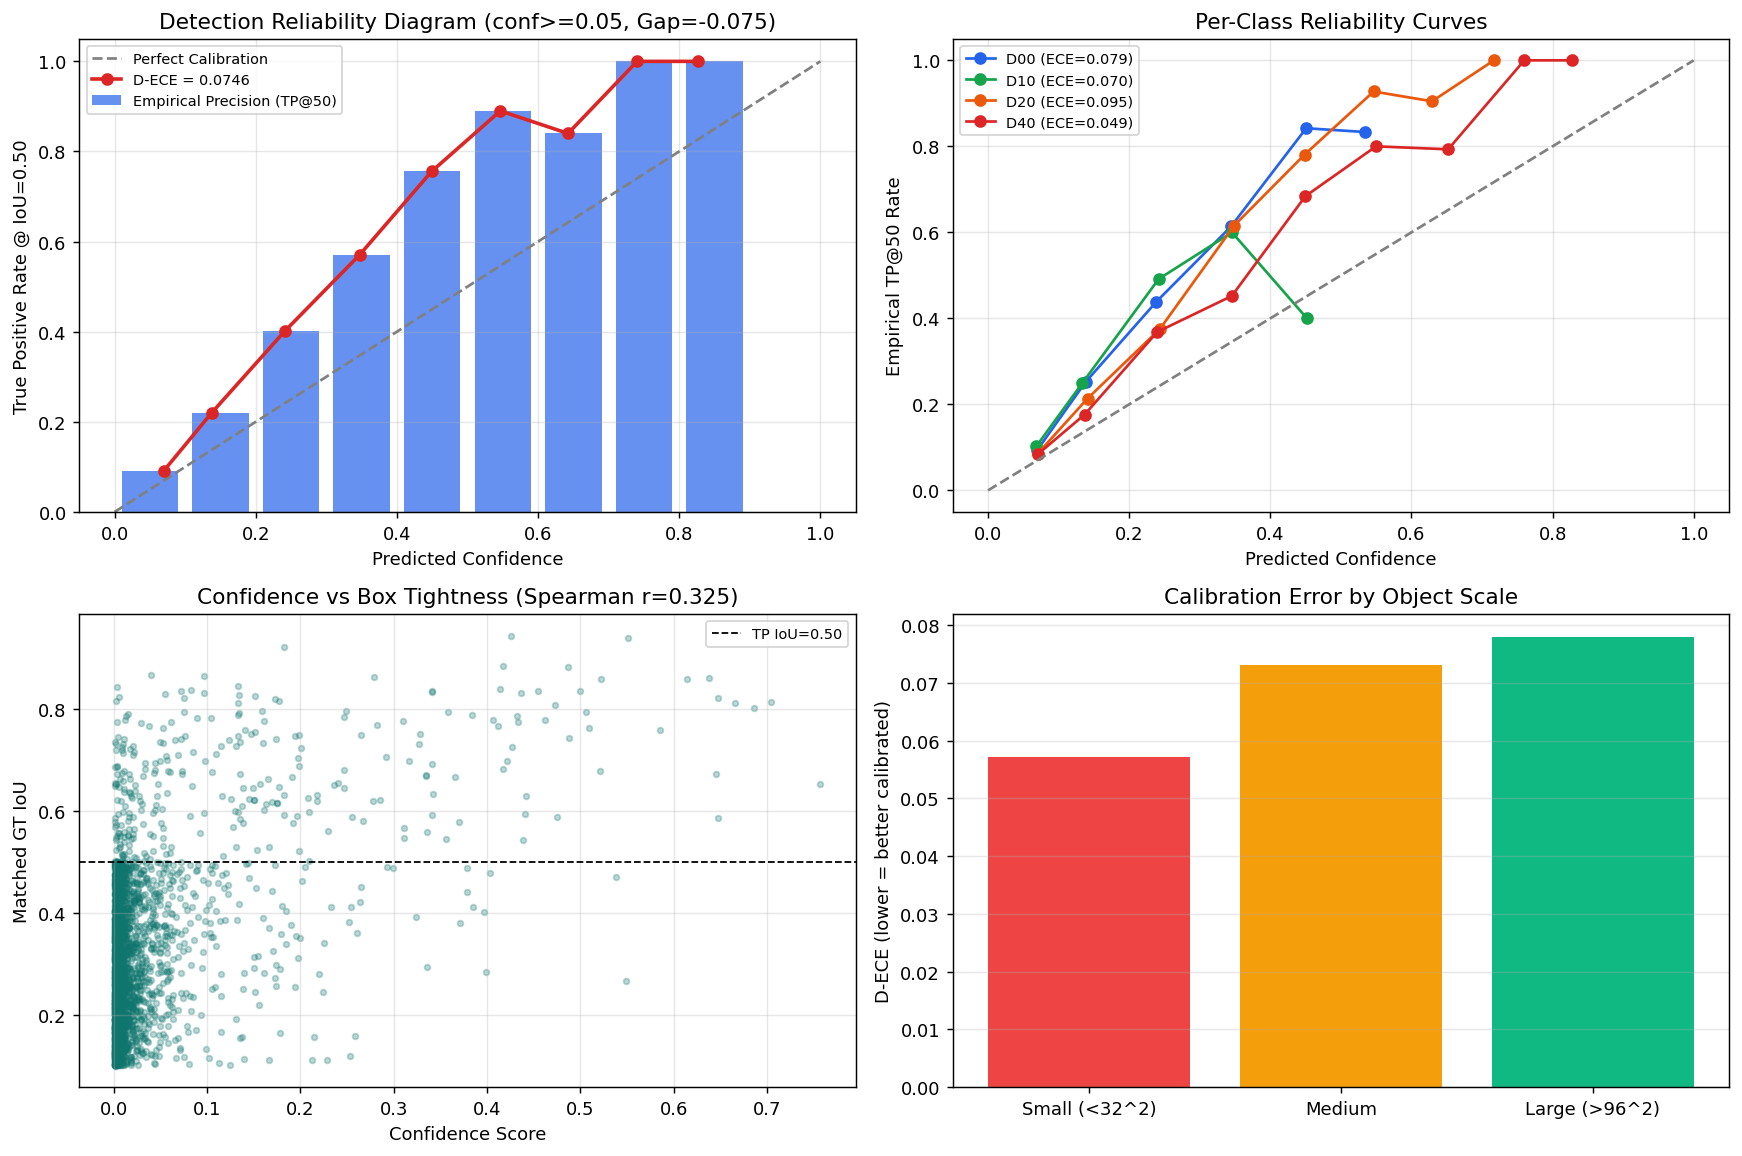

In [8]:
_execute_stage(3, '# Detection Calibration (D-ECE, arXiv:2312.06645 & arXiv:2611.00071) and Conf-vs-IoU Audit\ndef compute_dece_and_bins(df_in: pd.DataFrame, min_conf: float = 0.05, n_bins: int = 10):\n    sub = df_in[df_in[\'score\'] >= min_conf]\n    if sub.empty:\n        return 0.0, 0.0, pd.DataFrame()\n    scores = sub[\'score\'].to_numpy(dtype=np.float64)\n    tps = (sub[\'tide_tag\'] == \'TP\').to_numpy(dtype=np.float64)\n    edges = np.linspace(0.0, 1.0, n_bins + 1)\n    bin_rows = []\n    dece = 0.0\n    n_tot = len(scores)\n    for bi in range(n_bins):\n        lo, hi = edges[bi], edges[bi + 1]\n        m = (scores >= lo) & (scores < hi if bi < n_bins - 1 else scores <= hi)\n        cnt = int(m.sum())\n        if cnt > 0:\n            avg_c = float(scores[m].mean())\n            acc = float(tps[m].mean())\n            dece += (cnt / n_tot) * abs(acc - avg_c)\n        else:\n            avg_c, acc = float((lo + hi) * 0.5), 0.0\n        bin_rows.append({\'bin_mid\': round((lo + hi) * 0.5, 2), \'count\': cnt, \'mean_conf\': avg_c, \'emp_acc\': acc})\n    overconf_gap = float(scores.mean() - tps.mean())\n    return float(dece), overconf_gap, pd.DataFrame(bin_rows)\n\nDECE_OVERALL, OVERCONF_GAP, dece_bins_df = compute_dece_and_bins(det_df, min_conf=0.05, n_bins=10)\nDECE_ALL_RAW, _, _ = compute_dece_and_bins(det_df, min_conf=0.001, n_bins=10)\ndece_per_class = {}\nfor c in range(4):\n    d_c, oc_c, _ = compute_dece_and_bins(det_df[det_df[\'pred_cls\'] == c], min_conf=0.05, n_bins=10)\n    dece_per_class[CLASS_CODES[c]] = {\'dece\': round(d_c, 4), \'overconf_gap\': round(oc_c, 4)}\n\n# Confidence vs IoU tightness check (matched detections with iou >= 0.10)\nmatched_dets = det_df[det_df[\'tide_tag\'].isin([\'TP\', \'Loc\'])].copy()\nif len(matched_dets) >= 5:\n    conf_iou_spearman = float(matched_dets[\'score\'].corr(matched_dets[\'iou_match\'], method=\'spearman\'))\n    conf_iou_pearson = float(matched_dets[\'score\'].corr(matched_dets[\'iou_match\'], method=\'pearson\'))\n    if not np.isfinite(conf_iou_spearman):\n        conf_iou_spearman = 0.0\n    if not np.isfinite(conf_iou_pearson):\n        conf_iou_pearson = 0.0\nelse:\n    conf_iou_spearman, conf_iou_pearson = 0.0, 0.0\n\n# Scale-stratified D-ECE\ndet_df[\'area_px\'] = (det_df[\'x2\'] - det_df[\'x1\']) * (det_df[\'y2\'] - det_df[\'y1\'])\ndet_df[\'coco_scale\'] = np.where(det_df[\'area_px\'] < 1024.0, \'Small (<32^2)\',\n                                np.where(det_df[\'area_px\'] <= 9216.0, \'Medium\', \'Large (>96^2)\'))\ndece_by_scale = {}\nfor sc_name in [\'Small (<32^2)\', \'Medium\', \'Large (>96^2)\']:\n    d_s, oc_s, _ = compute_dece_and_bins(det_df[det_df[\'coco_scale\'] == sc_name], min_conf=0.05, n_bins=10)\n    dece_by_scale[sc_name] = {\'dece\': round(d_s, 4), \'overconf_gap\': round(oc_s, 4), \'n\': int((det_df[\'coco_scale\'] == sc_name).sum())}\n\nprint(f\'D-ECE (>=0.05): {DECE_OVERALL:.4f} | Overconfidence Gap: {OVERCONF_GAP:+.4f} | Conf-IoU Spearman: {conf_iou_spearman:.4f}\')\nprint(\'Per-Class D-ECE:\', json.dumps(dece_per_class))\nprint(\'Per-Scale D-ECE:\', json.dumps(dece_by_scale))\n\nfig, axes = plt.subplots(2, 2, figsize=(13.5, 9), dpi=130)\nnon_empty = dece_bins_df[dece_bins_df[\'count\'] > 0]\naxes[0, 0].plot([0, 1], [0, 1], \'--\', color=\'gray\', label=\'Perfect Calibration\')\naxes[0, 0].bar(non_empty[\'bin_mid\'], non_empty[\'emp_acc\'], width=0.08, alpha=0.7, color=\'#2563eb\', label=\'Empirical Precision (TP@50)\')\naxes[0, 0].plot(non_empty[\'mean_conf\'], non_empty[\'emp_acc\'], \'o-\', color=\'#dc2626\', lw=2, label=f\'D-ECE = {DECE_OVERALL:.4f}\')\naxes[0, 0].set_xlabel(\'Predicted Confidence\')\naxes[0, 0].set_ylabel(\'True Positive Rate @ IoU=0.50\')\naxes[0, 0].set_title(f\'Detection Reliability Diagram (conf>=0.05, Gap={OVERCONF_GAP:+.3f})\')\naxes[0, 0].legend(fontsize=8)\naxes[0, 0].grid(alpha=0.3)\n\nfor c in range(4):\n    _, _, b_c = compute_dece_and_bins(det_df[det_df[\'pred_cls\'] == c], min_conf=0.05, n_bins=10)\n    ne = b_c[b_c[\'count\'] > 0]\n    if not ne.empty:\n        axes[0, 1].plot(ne[\'mean_conf\'], ne[\'emp_acc\'], \'o-\', color=CLASS_COLORS[c], label=f"{CLASS_CODES[c]} (ECE={dece_per_class[CLASS_CODES[c]][\'dece\']:.3f})")\naxes[0, 1].plot([0, 1], [0, 1], \'--\', color=\'gray\')\naxes[0, 1].set_xlabel(\'Predicted Confidence\')\naxes[0, 1].set_ylabel(\'Empirical TP@50 Rate\')\naxes[0, 1].set_title(\'Per-Class Reliability Curves\')\naxes[0, 1].legend(fontsize=8)\naxes[0, 1].grid(alpha=0.3)\n\nif not matched_dets.empty:\n    samp_m = matched_dets.sample(n=min(3000, len(matched_dets)), random_state=SEED)\n    axes[1, 0].scatter(samp_m[\'score\'], samp_m[\'iou_match\'], s=10, alpha=0.28, color=\'#0f766e\')\n    axes[1, 0].axhline(0.50, color=\'black\', linestyle=\'--\', lw=1, label=\'TP IoU=0.50\')\naxes[1, 0].set_xlabel(\'Confidence Score\')\naxes[1, 0].set_ylabel(\'Matched GT IoU\')\naxes[1, 0].set_title(f\'Confidence vs Box Tightness (Spearman r={conf_iou_spearman:.3f})\')\naxes[1, 0].legend(fontsize=8)\naxes[1, 0].grid(alpha=0.3)\n\nsc_names = list(dece_by_scale.keys())\naxes[1, 1].bar(sc_names, [dece_by_scale[k][\'dece\'] for k in sc_names], color=[\'#ef4444\', \'#f59e0b\', \'#10b981\'])\naxes[1, 1].set_ylabel(\'D-ECE (lower = better calibrated)\')\naxes[1, 1].set_title(\'Calibration Error by Object Scale\')\naxes[1, 1].grid(axis=\'y\', alpha=0.3)\n\nplt.tight_layout()\nsave_ea_plot(fig, \'03_detection_calibration_dece.png\', \'plot_calibration_dece\')\ncheck_budget()')


## 5. Multi-Factor Physical Failure Slicing & 4-Bucket Degradation Robustness (DRI)
Slice Recall@50 and 2D spatial FP/FN heatmaps by box size, aspect ratio, 600 vs 720 domain, Y-zone, brightness, and blur, plus single-corruption DRI stress evaluation (arXiv:2611.00071).

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# Multi-Factor Physical Failure Slicing + 4-Bucket Degradation Robustness Index (DRI, arXiv:2611.00071)
def _scan_val_img(iid: str):
    p = val_path_map[iid]
    arr_bgr = cv2.imread(str(p))
    h_i, w_i = arr_bgr.shape[:2]
    gray = cv2.cvtColor(arr_bgr, cv2.COLOR_BGR2GRAY)
    mean_luma = float(gray.mean())
    std_luma = float(gray.std())
    lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    fsize = p.stat().st_size
    bpp = float(fsize / max(1, w_i * h_i))
    return {'image_id': iid, 'w': int(w_i), 'h': int(h_i), 'bpp': bpp, 'mean_luma': mean_luma, 'std_luma': std_luma, 'lap_var': lap_var}

with ThreadPoolExecutor(max_workers=16) as pool:
    val_img_meta_df = pd.DataFrame(list(pool.map(_scan_val_img, val_ids, chunksize=64)))

val_img_meta_df['res_group'] = np.where(val_img_meta_df['w'] == 600, '600x600',
                                        np.where(val_img_meta_df['w'] == 720, '720x720', 'Other'))
def _safe_qcut(series: pd.Series, lbls: list[str]):
    q_idx, bins = pd.qcut(series, q=len(lbls), labels=False, duplicates='drop', retbins=True)
    n_actual = max(1, len(bins) - 1)
    use_lbls = lbls[:n_actual]
    return q_idx.map(lambda v: use_lbls[int(v)] if pd.notna(v) else use_lbls[0])

val_img_meta_df['luma_bin'] = _safe_qcut(val_img_meta_df['mean_luma'], ['Q1 Darkest', 'Q2 Dim', 'Q3 Bright', 'Q4 Brightest'])
val_img_meta_df['sharp_bin'] = _safe_qcut(val_img_meta_df['lap_var'], ['Q1 Blurry', 'Q2 Soft', 'Q3 Sharp', 'Q4 Crisp'])

gt_enriched = gt_df.merge(val_img_meta_df, on='image_id', how='left')
gt_enriched['bw'] = gt_enriched['x2'] - gt_enriched['x1']
gt_enriched['bh'] = gt_enriched['y2'] - gt_enriched['y1']
gt_enriched['area_px'] = gt_enriched['bw'] * gt_enriched['bh']
gt_enriched['ar'] = gt_enriched['bw'] / np.maximum(1.0, gt_enriched['bh'])
gt_enriched['yc_norm'] = ((gt_enriched['y1'] + gt_enriched['y2']) * 0.5) / gt_enriched['h']
gt_enriched['coco_scale'] = np.where(gt_enriched['area_px'] < 1024.0, 'Small (<32^2)',
                                     np.where(gt_enriched['area_px'] <= 9216.0, 'Medium', 'Large (>96^2)'))
gt_enriched['ar_bucket'] = np.where(gt_enriched['ar'] < 0.5, 'Vertical (<0.5)',
                                    np.where(gt_enriched['ar'] <= 3.0, 'Balanced (0.5-3)', 'Thin Horiz (>3.0)'))
gt_enriched['y_zone'] = pd.cut(gt_enriched['yc_norm'], bins=[0.0, 0.35, 0.60, 0.88, 1.01],
                               labels=['Sky/Far (<0.35)', 'Upper (0.35-0.60)', 'Core (0.60-0.88)', 'Hood (>0.88)'])
gt_enriched['recalled_opt'] = ((gt_enriched['matched_tp'] == 1) & (gt_enriched['matched_tp_conf'] >= OPT_THR)).astype(int)

det_enriched = det_df.merge(val_img_meta_df[['image_id', 'w', 'h', 'res_group']], on='image_id', how='left')
det_enriched['xc_norm'] = np.clip(((det_enriched['x1'] + det_enriched['x2']) * 0.5) / det_enriched['w'], 0.0, 1.0)
det_enriched['yc_norm'] = np.clip(((det_enriched['y1'] + det_enriched['y2']) * 0.5) / det_enriched['h'], 0.0, 1.0)

def _slice_table(df_in: pd.DataFrame, col: str) -> dict:
    out = {}
    for k, grp in df_in.groupby(col, observed=False):
        tp_sub = grp[grp['recalled_opt'] == 1]
        out[str(k)] = {
            'n_gt': int(len(grp)),
            'recall_opt': round(float(grp['recalled_opt'].mean()), 4) if len(grp) > 0 else 0.0,
            'mean_tp_iou': round(float(tp_sub['matched_tp_iou'].mean()), 4) if len(tp_sub) > 0 else 0.0,
        }
    return out

failure_slices = {
    'by_scale': _slice_table(gt_enriched, 'coco_scale'),
    'by_aspect_ratio': _slice_table(gt_enriched, 'ar_bucket'),
    'by_resolution_domain': _slice_table(gt_enriched, 'res_group'),
    'by_vertical_zone': _slice_table(gt_enriched, 'y_zone'),
    'by_brightness': _slice_table(gt_enriched, 'luma_bin'),
    'by_sharpness': _slice_table(gt_enriched, 'sharp_bin'),
}

# Domain parity check (600x600 vs 720x720 mAP50)
domain_scores = {}
for rgrp in ['600x600', '720x720']:
    sub_ids = val_img_meta_df.loc[val_img_meta_df['res_group'] == rgrp, 'image_id'].tolist()
    if sub_ids:
        m50_d, _ = _fast_map50(gt_dict, preds_100, sub_ids)
        domain_scores[rgrp] = {'n_images': len(sub_ids), 'mAP50': round(float(m50_d), 4)}
failure_slices['domain_map50'] = domain_scores

fig, axes = plt.subplots(2, 3, figsize=(17, 9.2), dpi=130)
for ax, key, title in [
    (axes[0, 0], 'by_scale', 'GT Recall @ opt_thr by COCO Size'),
    (axes[0, 1], 'by_aspect_ratio', 'GT Recall by Aspect Ratio (Thin Cracks!)'),
    (axes[0, 2], 'by_resolution_domain', 'GT Recall by Camera Resolution Domain'),
    (axes[1, 0], 'by_vertical_zone', 'GT Recall by Road Vertical Band'),
]:
    d_s = failure_slices[key]
    lbls = list(d_s.keys())
    recs = [d_s[k]['recall_opt'] for k in lbls]
    bars_s = ax.bar(range(len(lbls)), recs, color='#2563eb')
    ax.set_xticks(range(len(lbls)))
    ax.set_xticklabels(lbls, rotation=16, fontsize=8)
    ax.set_ylim(0, 1.0)
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
    for b_i, (b, v, k) in enumerate(zip(bars_s, recs, lbls)):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}\n(n={d_s[k]['n_gt']})", ha='center', va='bottom', fontsize=7.5)

fp_opt = det_enriched[(det_enriched['score'] >= OPT_THR) & (det_enriched['tide_tag'] != 'TP')]
fn_gt = gt_enriched[gt_enriched['recalled_opt'] == 0]
fn_xc = ((fn_gt['x1'] + fn_gt['x2']) * 0.5) / fn_gt['w']
fn_yc = fn_gt['yc_norm']

h_fp, _, _ = np.histogram2d(fp_opt['xc_norm'], fp_opt['yc_norm'], bins=20, range=[[0, 1], [0, 1]])
axes[1, 1].imshow(h_fp.T, origin='upper', extent=[0, 1, 1, 0], cmap='Reds')
axes[1, 1].axhline(0.30, color='cyan', linestyle='--', lw=1.2, label='y=0.30 (95% GT floor)')
axes[1, 1].set_title(f'Where False Positives Land (n={len(fp_opt)})')
axes[1, 1].set_xlabel('x / W')
axes[1, 1].set_ylabel('y / H')
axes[1, 1].legend(fontsize=8)

h_fn, _, _ = np.histogram2d(fn_xc, fn_yc, bins=20, range=[[0, 1], [0, 1]])
axes[1, 2].imshow(h_fn.T, origin='upper', extent=[0, 1, 1, 0], cmap='Blues')
axes[1, 2].set_title(f'Where Missed Damage (FN) Lies (n={len(fn_gt)})')
axes[1, 2].set_xlabel('x / W')
axes[1, 2].set_ylabel('y / H')

plt.tight_layout()
save_ea_plot(fig, '04_failure_slices_and_spatial_heatmap.png', 'plot_failure_slices')

# 4-Bucket Degradation Stress Breakdown (DRI & D-ECE Shift per arXiv:2611.00071)
rng_s = np.random.default_rng(SEED)
dam_ids = [iid for iid in val_ids if iid in gt_dict]
cln_ids = [iid for iid in val_ids if iid not in gt_dict]
n_sub = min(len(val_ids), STRESS_SAMPLE_N)
n_sub_dam = int(round(n_sub * len(dam_ids) / len(val_ids)))
n_sub_cln = n_sub - n_sub_dam
stress_ids = list(rng_s.choice(dam_ids, size=min(n_sub_dam, len(dam_ids)), replace=False)) + \
             list(rng_s.choice(cln_ids, size=min(n_sub_cln, len(cln_ids)), replace=False))

sub_clean_m50, sub_clean_pc = _fast_map50(gt_dict, preds_100, stress_ids)
CORRUPTION_BUCKETS = {
    'jpeg_q8_18': lambda s: A.Compose([A.ImageCompression(compression_type='jpeg', quality_range=(8, 18), p=1.0)], seed=s),
    'dark_luma': lambda s: A.Compose([A.RandomBrightnessContrast(brightness_limit=(-0.72, -0.48), contrast_limit=(-0.30, 0.0), p=1.0)], seed=s),
    'blur_9_13': lambda s: A.Compose([A.OneOf([A.GaussianBlur(blur_limit=(9, 13), p=1.0), A.MotionBlur(blur_limit=(9, 13), p=1.0)], p=1.0)], seed=s),
    'gauss_noise': lambda s: A.Compose([A.GaussNoise(std_range=(0.06, 0.13), p=1.0)], seed=s),
}

dri_report = {'subset_n': len(stress_ids), 'clean_subset_mAP50': round(float(sub_clean_m50), 4), 'buckets': {}}
if detector is not None:
    clean_rgb_cache = {iid: cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB) for iid in stress_ids}
    for b_idx, (b_name, b_factory) in enumerate(CORRUPTION_BUCKETS.items()):
        b_preds = {}
        deg_det_rows = []
        for s_start in range(0, len(stress_ids), BATCH_SIZE):
            b_iids = stress_ids[s_start:s_start + BATCH_SIZE]
            b_imgs_bgr = []
            for k_i, iid in enumerate(b_iids):
                pipe = b_factory(SEED + b_idx * 10000 + s_start + k_i)
                deg_rgb = pipe(image=clean_rgb_cache[iid])['image']
                b_imgs_bgr.append(np.ascontiguousarray(deg_rgb[:, :, ::-1]))
            res_b = detector.predict(
                b_imgs_bgr, imgsz=IMGSZ, conf=CONF_FLOOR, iou=IOU_NMS, max_det=MAX_DET,
                agnostic_nms=False, device=DEVICE, verbose=False, **FP16_KWARGS
            )
            for iid, r in zip(b_iids, res_b):
                if r.boxes is None or len(r.boxes) == 0:
                    continue
                xyxy = r.boxes.xyxy.detach().cpu().numpy()
                confs = r.boxes.conf.detach().cpu().numpy()
                clss = r.boxes.cls.detach().cpu().numpy().astype(np.int64)
                arr_i = np.column_stack([clss.astype(np.float64), confs.astype(np.float64), xyxy.astype(np.float64)])
                b_preds[iid] = arr_i
                gb_i, gc_i = gt_dict.get(iid, (np.zeros((0, 4)), np.zeros(0, dtype=np.int64)))
                for row_k in range(len(arr_i)):
                    sc_v = float(arr_i[row_k, 1])
                    if sc_v >= 0.05:
                        c_v = int(arr_i[row_k, 0])
                        g_same = gb_i[gc_i == c_v]
                        tp_hit = 0
                        if len(g_same) > 0:
                            tp_hit = int(official_score.box_iou(arr_i[row_k:row_k+1, 2:6], g_same).max() >= 0.50)
                        deg_det_rows.append({'score': sc_v, 'tide_tag': 'TP' if tp_hit else 'Bkg'})
        deg_m50, deg_pc = _fast_map50(gt_dict, b_preds, stress_ids)
        deg_dece, deg_oc, _ = compute_dece_and_bins(pd.DataFrame(deg_det_rows), min_conf=0.05, n_bins=10) if deg_det_rows else (0.0, 0.0, None)
        dri_val = float(deg_m50 / max(1e-6, sub_clean_m50))
        dri_report['buckets'][b_name] = {
            'mAP50': round(float(deg_m50), 4),
            'DRI': round(dri_val, 4),
            'drop_pct': round((1.0 - dri_val) * 100.0, 2),
            'D_ECE_005': round(float(deg_dece), 4),
            'per_class_AP50': {CLASS_CODES[c]: round(float(deg_pc.get(c, 0.0)), 4) for c in range(4)},
        }
    del clean_rgb_cache
    DRI_MEAN = float(np.mean([v['DRI'] for v in dri_report['buckets'].values()]))
else:
    DRI_MEAN = 0.0
    print('Skipping 4-bucket live corruption sweep (no YOLO checkpoint loaded).')

if dri_report['buckets']:
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=130)
    b_keys = list(dri_report['buckets'].keys())
    dri_vals = [dri_report['buckets'][k]['DRI'] for k in b_keys]
    drops = [dri_report['buckets'][k]['drop_pct'] for k in b_keys]
    b_bar = axes[0].bar(b_keys, dri_vals, color=['#3b82f6', '#1e293b', '#f59e0b', '#8b5cf6'])
    axes[0].axhline(1.0, color='green', linestyle='--', lw=1, label='No Drop (DRI=1.0)')
    axes[0].set_ylim(0, 1.15)
    axes[0].set_ylabel('Degradation Robustness Index (mAP_deg / mAP_clean)')
    axes[0].set_title(f'4-Bucket Stress Robustness (Mean DRI={DRI_MEAN:.3f})')
    for b, dv, dp in zip(b_bar, dri_vals, drops):
        axes[0].text(b.get_x() + b.get_width() / 2, dv + 0.03, f'{dv:.2f}\n(-{dp:.0f}%)', ha='center', fontsize=8.5, fontweight='bold')

    x_b = np.arange(len(b_keys))
    w_b = 0.2
    for c in range(4):
        vals_c = [dri_report['buckets'][k]['per_class_AP50'][CLASS_CODES[c]] for k in b_keys]
        axes[1].bar(x_b + (c - 1.5) * w_b, vals_c, w_b, color=CLASS_COLORS[c], label=CLASS_CODES[c])
    axes[1].set_xticks(x_b)
    axes[1].set_xticklabels(b_keys)
    axes[1].set_ylabel('Degraded AP@50')
    axes[1].set_title('Per-Class Sensitivity Across Single Corruptions')
    axes[1].legend(fontsize=8)
    axes[1].grid(axis='y', alpha=0.3)
    plt.tight_layout()
    save_ea_plot(fig, '05_degradation_robustness_dri.png', 'plot_dri_stress')

print('DRI Report:', json.dumps(dri_report, indent=2))
check_budget()
```


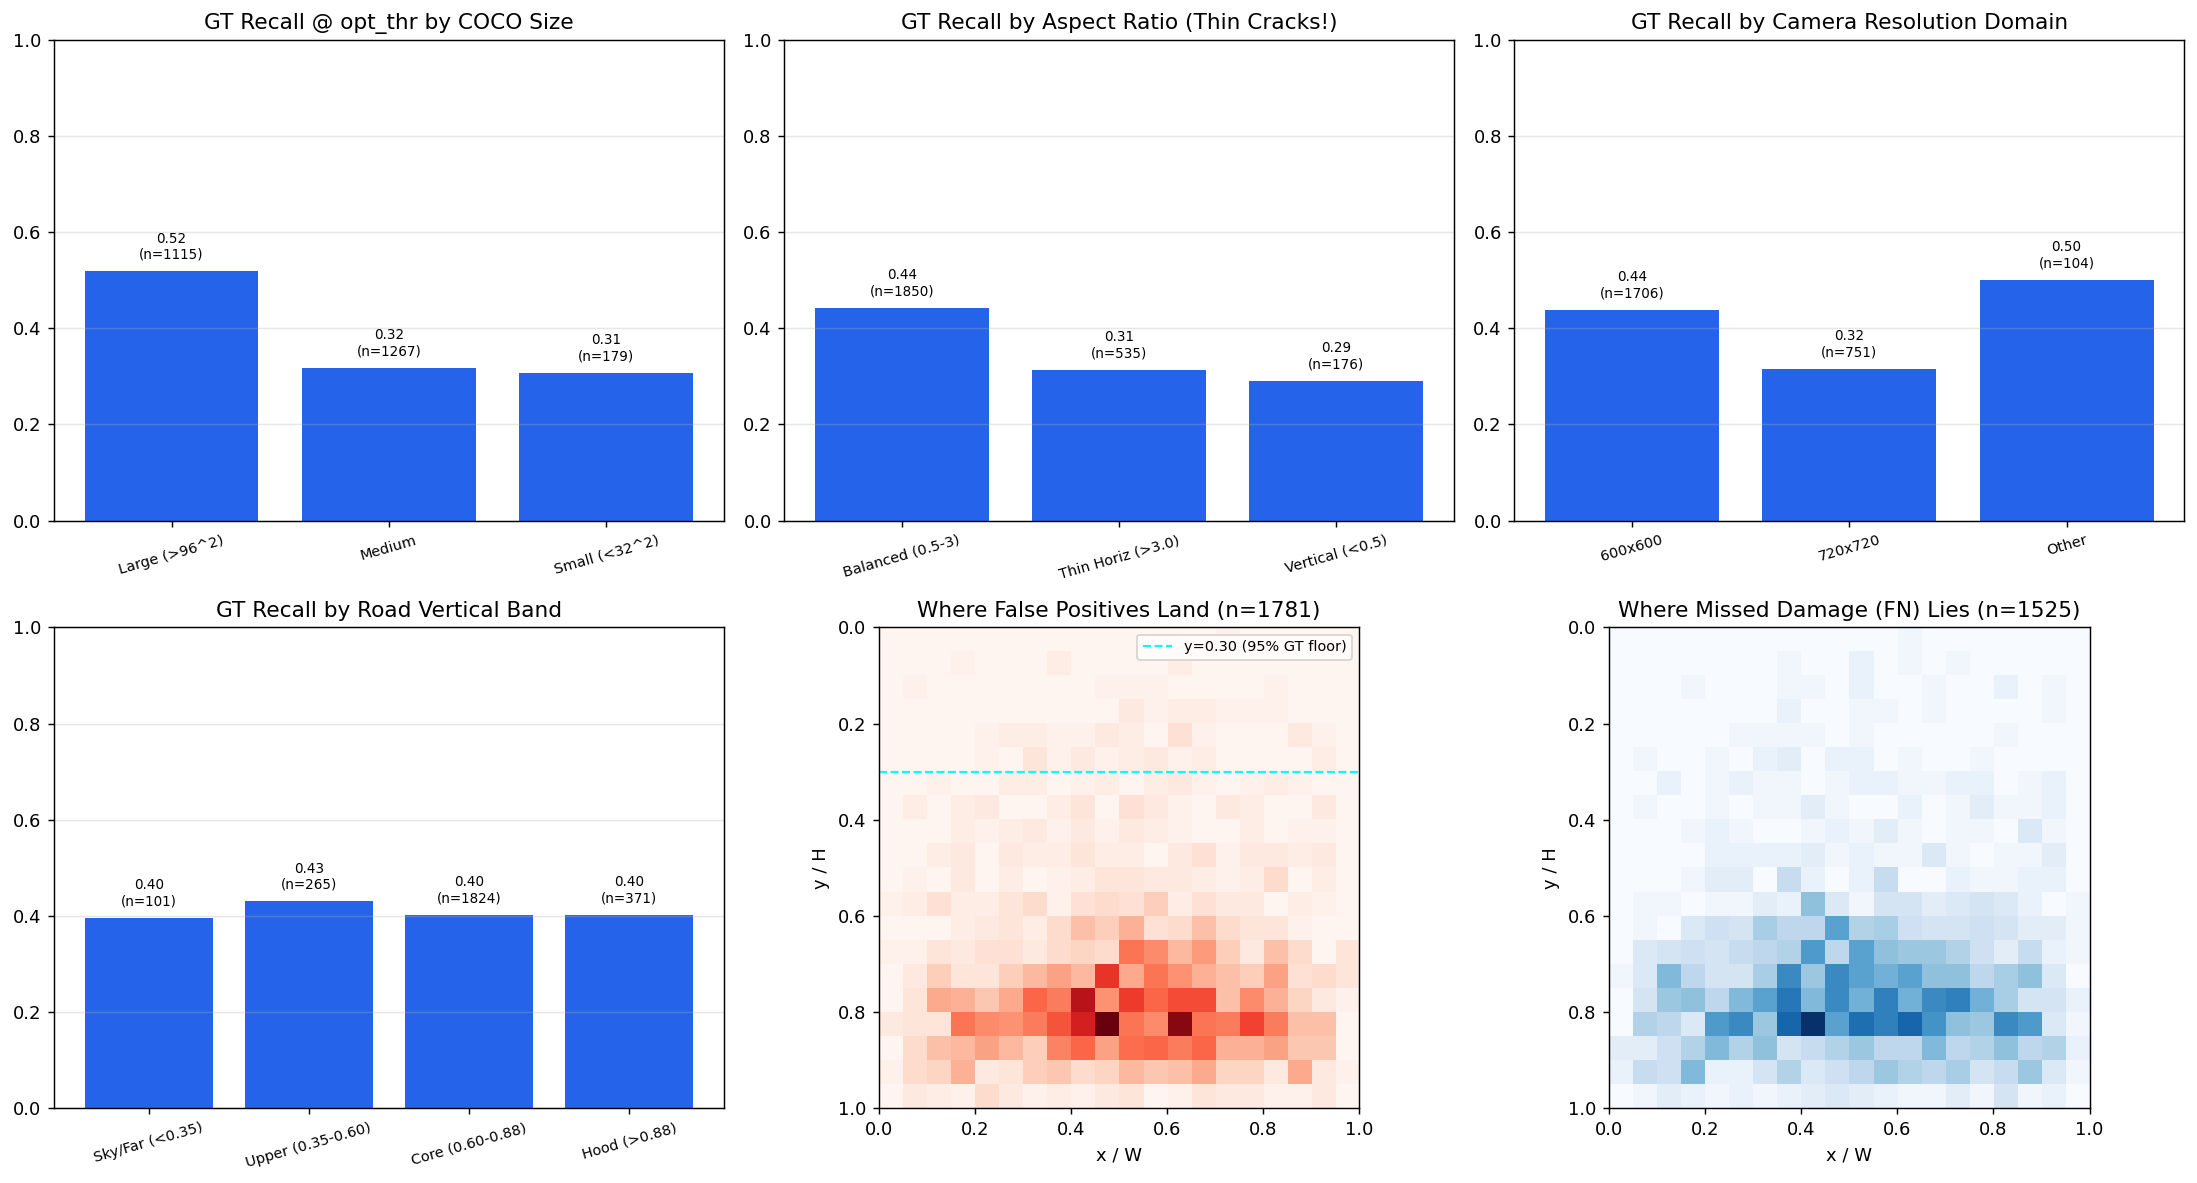

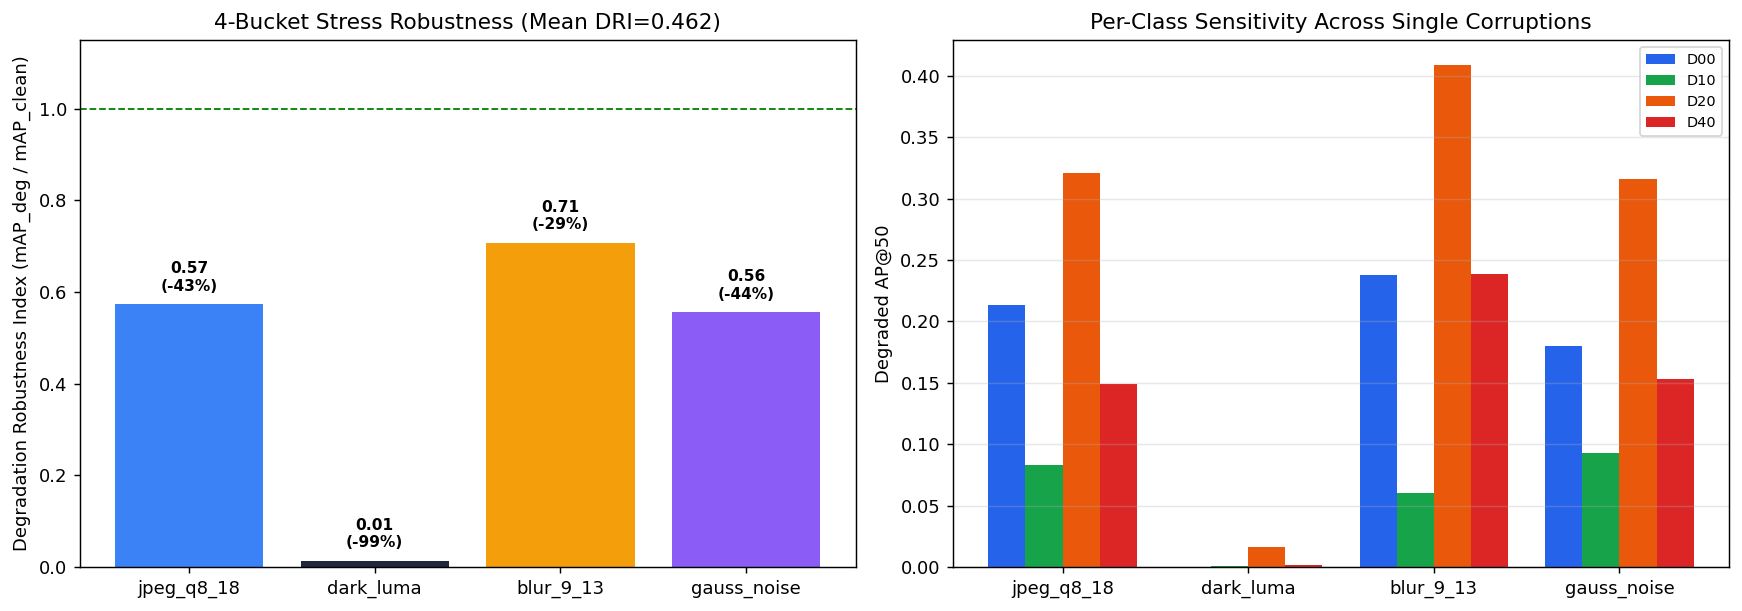

DRI Report: {
  "subset_n": 400,
  "clean_subset_mAP50": 0.3342,
  "buckets": {
    "jpeg_q8_18": {
      "mAP50": 0.1915,
      "DRI": 0.573,
      "drop_pct": 42.7,
      "D_ECE_005": 0.2045,
      "per_class_AP50": {
        "D00": 0.213,
        "D10": 0.0833,
        "D20": 0.3205,
        "D40": 0.149
      }
    },
    "dark_luma": {
      "mAP50": 0.0046,
      "DRI": 0.0137,
      "drop_pct": 98.63,
      "D_ECE_005": 0.0496,
      "per_class_AP50": {
        "D00": 0.0003,
        "D10": 0.0005,
        "D20": 0.0162,
        "D40": 0.0014
      }
    },
    "blur_9_13": {
      "mAP50": 0.2363,
      "DRI": 0.7072,
      "drop_pct": 29.28,
      "D_ECE_005": 0.1902,
      "per_class_AP50": {
        "D00": 0.2377,
        "D10": 0.0603,
        "D20": 0.4088,
        "D40": 0.2384
      }
    },
    "gauss_noise": {
      "mAP50": 0.1856,
      "DRI": 0.5553,
      "drop_pct": 44.47,
      "D_ECE_005": 0.1634,
      "per_class_AP50": {
        "D00": 0.1799,
        "D10": 0

In [9]:
_execute_stage(4, '# Multi-Factor Physical Failure Slicing + 4-Bucket Degradation Robustness Index (DRI, arXiv:2611.00071)\ndef _scan_val_img(iid: str):\n    p = val_path_map[iid]\n    arr_bgr = cv2.imread(str(p))\n    h_i, w_i = arr_bgr.shape[:2]\n    gray = cv2.cvtColor(arr_bgr, cv2.COLOR_BGR2GRAY)\n    mean_luma = float(gray.mean())\n    std_luma = float(gray.std())\n    lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())\n    fsize = p.stat().st_size\n    bpp = float(fsize / max(1, w_i * h_i))\n    return {\'image_id\': iid, \'w\': int(w_i), \'h\': int(h_i), \'bpp\': bpp, \'mean_luma\': mean_luma, \'std_luma\': std_luma, \'lap_var\': lap_var}\n\nwith ThreadPoolExecutor(max_workers=16) as pool:\n    val_img_meta_df = pd.DataFrame(list(pool.map(_scan_val_img, val_ids, chunksize=64)))\n\nval_img_meta_df[\'res_group\'] = np.where(val_img_meta_df[\'w\'] == 600, \'600x600\',\n                                        np.where(val_img_meta_df[\'w\'] == 720, \'720x720\', \'Other\'))\ndef _safe_qcut(series: pd.Series, lbls: list[str]):\n    q_idx, bins = pd.qcut(series, q=len(lbls), labels=False, duplicates=\'drop\', retbins=True)\n    n_actual = max(1, len(bins) - 1)\n    use_lbls = lbls[:n_actual]\n    return q_idx.map(lambda v: use_lbls[int(v)] if pd.notna(v) else use_lbls[0])\n\nval_img_meta_df[\'luma_bin\'] = _safe_qcut(val_img_meta_df[\'mean_luma\'], [\'Q1 Darkest\', \'Q2 Dim\', \'Q3 Bright\', \'Q4 Brightest\'])\nval_img_meta_df[\'sharp_bin\'] = _safe_qcut(val_img_meta_df[\'lap_var\'], [\'Q1 Blurry\', \'Q2 Soft\', \'Q3 Sharp\', \'Q4 Crisp\'])\n\ngt_enriched = gt_df.merge(val_img_meta_df, on=\'image_id\', how=\'left\')\ngt_enriched[\'bw\'] = gt_enriched[\'x2\'] - gt_enriched[\'x1\']\ngt_enriched[\'bh\'] = gt_enriched[\'y2\'] - gt_enriched[\'y1\']\ngt_enriched[\'area_px\'] = gt_enriched[\'bw\'] * gt_enriched[\'bh\']\ngt_enriched[\'ar\'] = gt_enriched[\'bw\'] / np.maximum(1.0, gt_enriched[\'bh\'])\ngt_enriched[\'yc_norm\'] = ((gt_enriched[\'y1\'] + gt_enriched[\'y2\']) * 0.5) / gt_enriched[\'h\']\ngt_enriched[\'coco_scale\'] = np.where(gt_enriched[\'area_px\'] < 1024.0, \'Small (<32^2)\',\n                                     np.where(gt_enriched[\'area_px\'] <= 9216.0, \'Medium\', \'Large (>96^2)\'))\ngt_enriched[\'ar_bucket\'] = np.where(gt_enriched[\'ar\'] < 0.5, \'Vertical (<0.5)\',\n                                    np.where(gt_enriched[\'ar\'] <= 3.0, \'Balanced (0.5-3)\', \'Thin Horiz (>3.0)\'))\ngt_enriched[\'y_zone\'] = pd.cut(gt_enriched[\'yc_norm\'], bins=[0.0, 0.35, 0.60, 0.88, 1.01],\n                               labels=[\'Sky/Far (<0.35)\', \'Upper (0.35-0.60)\', \'Core (0.60-0.88)\', \'Hood (>0.88)\'])\ngt_enriched[\'recalled_opt\'] = ((gt_enriched[\'matched_tp\'] == 1) & (gt_enriched[\'matched_tp_conf\'] >= OPT_THR)).astype(int)\n\ndet_enriched = det_df.merge(val_img_meta_df[[\'image_id\', \'w\', \'h\', \'res_group\']], on=\'image_id\', how=\'left\')\ndet_enriched[\'xc_norm\'] = np.clip(((det_enriched[\'x1\'] + det_enriched[\'x2\']) * 0.5) / det_enriched[\'w\'], 0.0, 1.0)\ndet_enriched[\'yc_norm\'] = np.clip(((det_enriched[\'y1\'] + det_enriched[\'y2\']) * 0.5) / det_enriched[\'h\'], 0.0, 1.0)\n\ndef _slice_table(df_in: pd.DataFrame, col: str) -> dict:\n    out = {}\n    for k, grp in df_in.groupby(col, observed=False):\n        tp_sub = grp[grp[\'recalled_opt\'] == 1]\n        out[str(k)] = {\n            \'n_gt\': int(len(grp)),\n            \'recall_opt\': round(float(grp[\'recalled_opt\'].mean()), 4) if len(grp) > 0 else 0.0,\n            \'mean_tp_iou\': round(float(tp_sub[\'matched_tp_iou\'].mean()), 4) if len(tp_sub) > 0 else 0.0,\n        }\n    return out\n\nfailure_slices = {\n    \'by_scale\': _slice_table(gt_enriched, \'coco_scale\'),\n    \'by_aspect_ratio\': _slice_table(gt_enriched, \'ar_bucket\'),\n    \'by_resolution_domain\': _slice_table(gt_enriched, \'res_group\'),\n    \'by_vertical_zone\': _slice_table(gt_enriched, \'y_zone\'),\n    \'by_brightness\': _slice_table(gt_enriched, \'luma_bin\'),\n    \'by_sharpness\': _slice_table(gt_enriched, \'sharp_bin\'),\n}\n\n# Domain parity check (600x600 vs 720x720 mAP50)\ndomain_scores = {}\nfor rgrp in [\'600x600\', \'720x720\']:\n    sub_ids = val_img_meta_df.loc[val_img_meta_df[\'res_group\'] == rgrp, \'image_id\'].tolist()\n    if sub_ids:\n        m50_d, _ = _fast_map50(gt_dict, preds_100, sub_ids)\n        domain_scores[rgrp] = {\'n_images\': len(sub_ids), \'mAP50\': round(float(m50_d), 4)}\nfailure_slices[\'domain_map50\'] = domain_scores\n\nfig, axes = plt.subplots(2, 3, figsize=(17, 9.2), dpi=130)\nfor ax, key, title in [\n    (axes[0, 0], \'by_scale\', \'GT Recall @ opt_thr by COCO Size\'),\n    (axes[0, 1], \'by_aspect_ratio\', \'GT Recall by Aspect Ratio (Thin Cracks!)\'),\n    (axes[0, 2], \'by_resolution_domain\', \'GT Recall by Camera Resolution Domain\'),\n    (axes[1, 0], \'by_vertical_zone\', \'GT Recall by Road Vertical Band\'),\n]:\n    d_s = failure_slices[key]\n    lbls = list(d_s.keys())\n    recs = [d_s[k][\'recall_opt\'] for k in lbls]\n    bars_s = ax.bar(range(len(lbls)), recs, color=\'#2563eb\')\n    ax.set_xticks(range(len(lbls)))\n    ax.set_xticklabels(lbls, rotation=16, fontsize=8)\n    ax.set_ylim(0, 1.0)\n    ax.set_title(title)\n    ax.grid(axis=\'y\', alpha=0.3)\n    for b_i, (b, v, k) in enumerate(zip(bars_s, recs, lbls)):\n        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}\\n(n={d_s[k][\'n_gt\']})", ha=\'center\', va=\'bottom\', fontsize=7.5)\n\nfp_opt = det_enriched[(det_enriched[\'score\'] >= OPT_THR) & (det_enriched[\'tide_tag\'] != \'TP\')]\nfn_gt = gt_enriched[gt_enriched[\'recalled_opt\'] == 0]\nfn_xc = ((fn_gt[\'x1\'] + fn_gt[\'x2\']) * 0.5) / fn_gt[\'w\']\nfn_yc = fn_gt[\'yc_norm\']\n\nh_fp, _, _ = np.histogram2d(fp_opt[\'xc_norm\'], fp_opt[\'yc_norm\'], bins=20, range=[[0, 1], [0, 1]])\naxes[1, 1].imshow(h_fp.T, origin=\'upper\', extent=[0, 1, 1, 0], cmap=\'Reds\')\naxes[1, 1].axhline(0.30, color=\'cyan\', linestyle=\'--\', lw=1.2, label=\'y=0.30 (95% GT floor)\')\naxes[1, 1].set_title(f\'Where False Positives Land (n={len(fp_opt)})\')\naxes[1, 1].set_xlabel(\'x / W\')\naxes[1, 1].set_ylabel(\'y / H\')\naxes[1, 1].legend(fontsize=8)\n\nh_fn, _, _ = np.histogram2d(fn_xc, fn_yc, bins=20, range=[[0, 1], [0, 1]])\naxes[1, 2].imshow(h_fn.T, origin=\'upper\', extent=[0, 1, 1, 0], cmap=\'Blues\')\naxes[1, 2].set_title(f\'Where Missed Damage (FN) Lies (n={len(fn_gt)})\')\naxes[1, 2].set_xlabel(\'x / W\')\naxes[1, 2].set_ylabel(\'y / H\')\n\nplt.tight_layout()\nsave_ea_plot(fig, \'04_failure_slices_and_spatial_heatmap.png\', \'plot_failure_slices\')\n\n# 4-Bucket Degradation Stress Breakdown (DRI & D-ECE Shift per arXiv:2611.00071)\nrng_s = np.random.default_rng(SEED)\ndam_ids = [iid for iid in val_ids if iid in gt_dict]\ncln_ids = [iid for iid in val_ids if iid not in gt_dict]\nn_sub = min(len(val_ids), STRESS_SAMPLE_N)\nn_sub_dam = int(round(n_sub * len(dam_ids) / len(val_ids)))\nn_sub_cln = n_sub - n_sub_dam\nstress_ids = list(rng_s.choice(dam_ids, size=min(n_sub_dam, len(dam_ids)), replace=False)) + \\\n             list(rng_s.choice(cln_ids, size=min(n_sub_cln, len(cln_ids)), replace=False))\n\nsub_clean_m50, sub_clean_pc = _fast_map50(gt_dict, preds_100, stress_ids)\nCORRUPTION_BUCKETS = {\n    \'jpeg_q8_18\': lambda s: A.Compose([A.ImageCompression(compression_type=\'jpeg\', quality_range=(8, 18), p=1.0)], seed=s),\n    \'dark_luma\': lambda s: A.Compose([A.RandomBrightnessContrast(brightness_limit=(-0.72, -0.48), contrast_limit=(-0.30, 0.0), p=1.0)], seed=s),\n    \'blur_9_13\': lambda s: A.Compose([A.OneOf([A.GaussianBlur(blur_limit=(9, 13), p=1.0), A.MotionBlur(blur_limit=(9, 13), p=1.0)], p=1.0)], seed=s),\n    \'gauss_noise\': lambda s: A.Compose([A.GaussNoise(std_range=(0.06, 0.13), p=1.0)], seed=s),\n}\n\ndri_report = {\'subset_n\': len(stress_ids), \'clean_subset_mAP50\': round(float(sub_clean_m50), 4), \'buckets\': {}}\nif detector is not None:\n    clean_rgb_cache = {iid: cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB) for iid in stress_ids}\n    for b_idx, (b_name, b_factory) in enumerate(CORRUPTION_BUCKETS.items()):\n        b_preds = {}\n        deg_det_rows = []\n        for s_start in range(0, len(stress_ids), BATCH_SIZE):\n            b_iids = stress_ids[s_start:s_start + BATCH_SIZE]\n            b_imgs_bgr = []\n            for k_i, iid in enumerate(b_iids):\n                pipe = b_factory(SEED + b_idx * 10000 + s_start + k_i)\n                deg_rgb = pipe(image=clean_rgb_cache[iid])[\'image\']\n                b_imgs_bgr.append(np.ascontiguousarray(deg_rgb[:, :, ::-1]))\n            res_b = detector.predict(\n                b_imgs_bgr, imgsz=IMGSZ, conf=CONF_FLOOR, iou=IOU_NMS, max_det=MAX_DET,\n                agnostic_nms=False, device=DEVICE, verbose=False, **FP16_KWARGS\n            )\n            for iid, r in zip(b_iids, res_b):\n                if r.boxes is None or len(r.boxes) == 0:\n                    continue\n                xyxy = r.boxes.xyxy.detach().cpu().numpy()\n                confs = r.boxes.conf.detach().cpu().numpy()\n                clss = r.boxes.cls.detach().cpu().numpy().astype(np.int64)\n                arr_i = np.column_stack([clss.astype(np.float64), confs.astype(np.float64), xyxy.astype(np.float64)])\n                b_preds[iid] = arr_i\n                gb_i, gc_i = gt_dict.get(iid, (np.zeros((0, 4)), np.zeros(0, dtype=np.int64)))\n                for row_k in range(len(arr_i)):\n                    sc_v = float(arr_i[row_k, 1])\n                    if sc_v >= 0.05:\n                        c_v = int(arr_i[row_k, 0])\n                        g_same = gb_i[gc_i == c_v]\n                        tp_hit = 0\n                        if len(g_same) > 0:\n                            tp_hit = int(official_score.box_iou(arr_i[row_k:row_k+1, 2:6], g_same).max() >= 0.50)\n                        deg_det_rows.append({\'score\': sc_v, \'tide_tag\': \'TP\' if tp_hit else \'Bkg\'})\n        deg_m50, deg_pc = _fast_map50(gt_dict, b_preds, stress_ids)\n        deg_dece, deg_oc, _ = compute_dece_and_bins(pd.DataFrame(deg_det_rows), min_conf=0.05, n_bins=10) if deg_det_rows else (0.0, 0.0, None)\n        dri_val = float(deg_m50 / max(1e-6, sub_clean_m50))\n        dri_report[\'buckets\'][b_name] = {\n            \'mAP50\': round(float(deg_m50), 4),\n            \'DRI\': round(dri_val, 4),\n            \'drop_pct\': round((1.0 - dri_val) * 100.0, 2),\n            \'D_ECE_005\': round(float(deg_dece), 4),\n            \'per_class_AP50\': {CLASS_CODES[c]: round(float(deg_pc.get(c, 0.0)), 4) for c in range(4)},\n        }\n    del clean_rgb_cache\n    DRI_MEAN = float(np.mean([v[\'DRI\'] for v in dri_report[\'buckets\'].values()]))\nelse:\n    DRI_MEAN = 0.0\n    print(\'Skipping 4-bucket live corruption sweep (no YOLO checkpoint loaded).\')\n\nif dri_report[\'buckets\']:\n    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=130)\n    b_keys = list(dri_report[\'buckets\'].keys())\n    dri_vals = [dri_report[\'buckets\'][k][\'DRI\'] for k in b_keys]\n    drops = [dri_report[\'buckets\'][k][\'drop_pct\'] for k in b_keys]\n    b_bar = axes[0].bar(b_keys, dri_vals, color=[\'#3b82f6\', \'#1e293b\', \'#f59e0b\', \'#8b5cf6\'])\n    axes[0].axhline(1.0, color=\'green\', linestyle=\'--\', lw=1, label=\'No Drop (DRI=1.0)\')\n    axes[0].set_ylim(0, 1.15)\n    axes[0].set_ylabel(\'Degradation Robustness Index (mAP_deg / mAP_clean)\')\n    axes[0].set_title(f\'4-Bucket Stress Robustness (Mean DRI={DRI_MEAN:.3f})\')\n    for b, dv, dp in zip(b_bar, dri_vals, drops):\n        axes[0].text(b.get_x() + b.get_width() / 2, dv + 0.03, f\'{dv:.2f}\\n(-{dp:.0f}%)\', ha=\'center\', fontsize=8.5, fontweight=\'bold\')\n\n    x_b = np.arange(len(b_keys))\n    w_b = 0.2\n    for c in range(4):\n        vals_c = [dri_report[\'buckets\'][k][\'per_class_AP50\'][CLASS_CODES[c]] for k in b_keys]\n        axes[1].bar(x_b + (c - 1.5) * w_b, vals_c, w_b, color=CLASS_COLORS[c], label=CLASS_CODES[c])\n    axes[1].set_xticks(x_b)\n    axes[1].set_xticklabels(b_keys)\n    axes[1].set_ylabel(\'Degraded AP@50\')\n    axes[1].set_title(\'Per-Class Sensitivity Across Single Corruptions\')\n    axes[1].legend(fontsize=8)\n    axes[1].grid(axis=\'y\', alpha=0.3)\n    plt.tight_layout()\n    save_ea_plot(fig, \'05_degradation_robustness_dri.png\', \'plot_dri_stress\')\n\nprint(\'DRI Report:\', json.dumps(dri_report, indent=2))\ncheck_budget()')


## 6. Feature-Space Failure Clusters, Suspected Unlabeled GT Audit & Multi-Scale Eigen-CAM
Extract neck embeddings, cluster failure archetypes (PCA+KMeans), flag suspected unlabeled GT via k-NN (arXiv:2606.10666), and render Multi-Scale Eigen-CAM heatmaps on worst FPs & FNs.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# Feature-Space Failure Clustering, Suspected Unlabeled GT Audit (arXiv:2606.10666) & Native Multi-Scale Eigen-CAM
N_CLUSTERS = int(EXP_CFG.get('n_clusters', 6))
KNN_K = int(EXP_CFG.get('knn_k', 15))
TOP_K_VIS = int(EXP_CFG.get('top_k_visual', 8))

SUSPECTED_UNLABELED_GT = []
CLUSTER_SUMMARY = []
SUSPECTED_LABEL_SWAPS = []

# High-conf Cls errors (>=0.40 conf, >=0.60 IoU) are label-ambiguity candidates
cls_ambig = det_df[(det_df['tide_tag'] == 'Cls') & (det_df['score'] >= 0.40) & (det_df['iou_match'] >= 0.60)].sort_values('score', ascending=False)
for _, r in cls_ambig.head(20).iterrows():
    SUSPECTED_LABEL_SWAPS.append({
        'image_id': str(r['image_id']),
        'pred_cls': CLASS_CODES[int(r['pred_cls'])],
        'gt_cls': CLASS_CODES[int(r['diff_cls'])],
        'conf': round(float(r['score']), 4),
        'iou': round(float(r['iou_match']), 4),
    })

if HAS_YOLO_CKPT and BEST_PT_LOCAL.is_file():
    cam_yolo = YOLO(str(BEST_PT_LOCAL))
    cam_model = cam_yolo.model.to(DEVICE).eval().float()
    detect_mod = cam_model.model[-1]
    if hasattr(detect_mod, 'f') and isinstance(detect_mod.f, (list, tuple)):
        neck_indices = [int(i) if int(i) >= 0 else len(cam_model.model) + int(i) for i in detect_mod.f]
    else:
        neck_indices = [len(cam_model.model) - 2]
    emb_layer_idx = neck_indices[-1]
    print('Auto-detected neck feature layers for Eigen-CAM:', neck_indices, '| embedding layer:', emb_layer_idx)

    # Extract penultimate neck embeddings in clean batched FP32 forward passes
    def _unwrap_tensor(out):
        return out[0] if isinstance(out, (tuple, list)) else out

    emb_store = {}
    hook_emb = cam_model.model[emb_layer_idx].register_forward_hook(
        lambda _m, _in, out: emb_store.__setitem__('feat', _unwrap_tensor(out).detach().mean(dim=(2, 3)).cpu())
    )
    emb_chunks = []
    try:
        with torch.no_grad():
            for start in range(0, len(val_ids), BATCH_SIZE):
                b_ids = val_ids[start:start + BATCH_SIZE]
                tensors = []
                for iid in b_ids:
                    bgr = cv2.imread(str(val_path_map[iid]))
                    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                    resz = cv2.resize(rgb, (IMGSZ, IMGSZ), interpolation=cv2.INTER_LINEAR)
                    tensors.append(torch.from_numpy(resz).permute(2, 0, 1).float().div_(255.0))
                batch_t = torch.stack(tensors, dim=0).to(DEVICE)
                _ = cam_model(batch_t)
                emb_chunks.append(emb_store['feat'])
    finally:
        hook_emb.remove()

    emb_mat = torch.cat(emb_chunks, dim=0).numpy().astype(np.float32)
    norms = np.linalg.norm(emb_mat, axis=1, keepdims=True) + 1e-8
    emb_norm = emb_mat / norms

    pca_dim = min(20, emb_norm.shape[0], emb_norm.shape[1])
    pca_feats = PCA(n_components=pca_dim, random_state=SEED).fit_transform(emb_norm)
    kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
    cluster_ids = kmeans.fit_predict(pca_feats)

    img_gate_df['cluster'] = cluster_ids
    img_gate_df['pca_x'] = pca_feats[:, 0]
    img_gate_df['pca_y'] = pca_feats[:, 1]
    img_full = img_gate_df.merge(val_img_meta_df[['image_id', 'w', 'mean_luma', 'lap_var']], on='image_id', how='left')
    fn_by_img = gt_enriched.groupby('image_id')['recalled_opt'].apply(lambda s: int((s == 0).sum())).to_dict()
    gt_cnt_by_img = gt_enriched.groupby('image_id').size().to_dict()

    for cid in range(N_CLUSTERS):
        sub_c = img_full[img_full['cluster'] == cid]
        cln_sub = sub_c[sub_c['is_damaged'] == 0]
        cln_fp_r = float((cln_sub['n_boxes_opt'] > 0).mean()) if len(cln_sub) > 0 else 0.0
        n_miss_c = sum(fn_by_img.get(iid, 0) for iid in sub_c['image_id'])
        n_gt_c = max(1, sum(gt_cnt_by_img.get(iid, 0) for iid in sub_c['image_id']))
        CLUSTER_SUMMARY.append({
            'cluster': int(cid),
            'n_images': int(len(sub_c)),
            'pct_damaged': round(100.0 * float(sub_c['is_damaged'].mean()), 1),
            'pct_720px': round(100.0 * float((sub_c['w'] == 720).mean()), 1),
            'mean_luma': round(float(sub_c['mean_luma'].mean()), 1),
            'clean_road_fp_rate': round(cln_fp_r, 4),
            'box_fn_rate': round(float(n_miss_c / n_gt_c), 4),
        })

    # Feature-space kNN audit for suspected unlabeled GT in Clean-Road images (arXiv:2606.10666)
    sim_mat = emb_norm @ emb_norm.T
    np.fill_diagonal(sim_mat, -np.inf)
    knn_idx = np.argpartition(-sim_mat, KNN_K, axis=1)[:, :KNN_K]
    is_dam_arr = img_gate_df['is_damaged'].to_numpy()
    nbr_dam_frac = is_dam_arr[knn_idx].mean(axis=1)
    img_gate_df['nbr_damaged_frac'] = nbr_dam_frac

    clean_high = img_gate_df[(img_gate_df['is_damaged'] == 0) & (img_gate_df['max_conf'] >= OPT_THR)].sort_values('max_conf', ascending=False)
    for _, r in clean_high.iterrows():
        if float(r['max_conf']) >= 0.35 and float(r['nbr_damaged_frac']) >= 0.55:
            SUSPECTED_UNLABELED_GT.append({
                'image_id': str(r['image_id']),
                'max_conf': round(float(r['max_conf']), 4),
                'nbr_damaged_frac': round(float(r['nbr_damaged_frac']), 4),
                'top1_cls': CLASS_CODES.get(int(r['top1_cls']), 'UNK'),
            })
    print(f'Cluster Failure Summary (k={N_CLUSTERS}):')
    print(pd.DataFrame(CLUSTER_SUMMARY).to_string(index=False))
    print(f'Flagged {len(SUSPECTED_UNLABELED_GT)} Clean-Road images as SUSPECTED_UNLABELED_GT & {len(SUSPECTED_LABEL_SWAPS)} Cls ambiguity candidates.')

    # Native PyTorch Multi-Scale Eigen-CAM helper (no external grad-cam dependency)
    def compute_multiscale_eigencam(img_rgb: np.ndarray) -> np.ndarray:
        h0, w0 = img_rgb.shape[:2]
        resz = cv2.resize(img_rgb, (IMGSZ, IMGSZ), interpolation=cv2.INTER_LINEAR)
        x_t = torch.from_numpy(resz).permute(2, 0, 1).float().div_(255.0).unsqueeze(0).to(DEVICE)
        feats = {}
        hooks = [cam_model.model[li].register_forward_hook(lambda _m, _in, out, key=li: feats.__setitem__(key, _unwrap_tensor(out).detach()))
                 for li in neck_indices]
        try:
            with torch.no_grad():
                _ = cam_model(x_t)
        finally:
            for hk in hooks:
                hk.remove()
        cam_accum = np.zeros((h0, w0), dtype=np.float32)
        for li in neck_indices:
            fmap = feats[li][0].float()  # (C, H_f, W_f)
            c_f, h_f, w_f = fmap.shape
            mat = fmap.reshape(c_f, h_f * w_f).cpu()
            mat = mat - mat.mean(dim=1, keepdim=True)
            u, s, vt = torch.linalg.svd(mat, full_matrices=False)
            proj = (u[:, 0] @ mat).numpy().reshape(h_f, w_f)
            if float(np.sum(proj * mat.mean(dim=0).numpy().reshape(h_f, w_f))) < 0:
                proj = -proj
            proj = np.maximum(proj, 0.0)
            p_max = float(proj.max())
            if p_max > 1e-8:
                proj = (proj - float(proj.min())) / (p_max - float(proj.min()) + 1e-8)
            cam_accum += cv2.resize(proj.astype(np.float32), (w0, h0), interpolation=cv2.INTER_LINEAR)
        cam_mean = cam_accum / max(1, len(neck_indices))
        cam_norm = (cam_mean - float(cam_mean.min())) / (float(cam_mean.max()) - float(cam_mean.min()) + 1e-8)
        return cam_norm

    def _overlay_cam(img_rgb: np.ndarray, cam_01: np.ndarray) -> np.ndarray:
        heat_bgr = cv2.applyColorMap(np.uint8(255 * cam_01), cv2.COLORMAP_JET)
        heat_rgb = cv2.cvtColor(heat_bgr, cv2.COLOR_BGR2RGB)
        return np.clip(0.42 * heat_rgb.astype(np.float32) + 0.58 * img_rgb.astype(np.float32), 0, 255).astype(np.uint8)

    # Plot 06: Top-8 Clean-Road False Positives + Eigen-CAM
    unlabeled_set = {x['image_id'] for x in SUSPECTED_UNLABELED_GT}
    top_fp_imgs = clean_high.head(TOP_K_VIS)['image_id'].tolist()
    n_fp_show = max(1, len(top_fp_imgs))
    fig, axes = plt.subplots(2, n_fp_show, figsize=(2.7 * n_fp_show, 6.2), dpi=130)
    if n_fp_show == 1:
        axes = axes.reshape(2, 1)
    for ax in axes.ravel():
        ax.axis('off')
    for j, iid in enumerate(top_fp_imgs):
        rgb = cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB)
        cam = compute_multiscale_eigencam(rgb)
        ov = _overlay_cam(rgb, cam)
        sub_p = det_df[(det_df['image_id'] == iid) & (det_df['score'] >= OPT_THR)].head(4)
        axes[0, j].imshow(rgb)
        axes[1, j].imshow(ov)
        for _, pr in sub_p.iterrows():
            rect = patches.Rectangle((pr['x1'], pr['y1']), pr['x2'] - pr['x1'], pr['y2'] - pr['y1'], lw=2, edgecolor='#ef4444', facecolor='none')
            axes[0, j].add_patch(rect)
            axes[0, j].text(pr['x1'], max(12, pr['y1'] - 3), f"{CLASS_CODES[int(pr['pred_cls'])]} {pr['score']:.2f}",
                            color='white', fontsize=6.5, bbox=dict(facecolor='#ef4444', alpha=0.85, pad=1, edgecolor='none'))
        tag_lbl = 'UNLABELED GT?' if iid in unlabeled_set else 'HALLUCINATION'
        nbr_f = float(img_gate_df.loc[img_gate_df['image_id'] == iid, 'nbr_damaged_frac'].iloc[0])
        axes[0, j].set_title(f"{iid}\n[{tag_lbl}] kNN={nbr_f:.0%}", fontsize=7.5)
        axes[1, j].set_title('Multi-Scale Eigen-CAM', fontsize=7.5)
        axes[0, j].axis('off')
        axes[1, j].axis('off')
    plt.tight_layout()
    save_ea_plot(fig, '06_eigencam_and_hall_of_shame_fp.png', 'plot_eigencam_fp')

    # Plot 07: Top-8 Missed Damage Images + Eigen-CAM + Cluster Error Map
    miss_rank = gt_enriched[gt_enriched['recalled_opt'] == 0].groupby('image_id').agg(
        n_miss=('gt_uid', 'count'), max_area=('area_px', 'max')
    ).sort_values(['n_miss', 'max_area'], ascending=[False, False])
    top_fn_imgs = miss_rank.head(TOP_K_VIS).index.tolist()
    n_fn_show = max(1, len(top_fn_imgs))
    fig, axes = plt.subplots(2, n_fn_show, figsize=(2.7 * n_fn_show, 6.2), dpi=130)
    if n_fn_show == 1:
        axes = axes.reshape(2, 1)
    for ax in axes.ravel():
        ax.axis('off')
    for j, iid in enumerate(top_fn_imgs):
        rgb = cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB)
        ov = _overlay_cam(rgb, compute_multiscale_eigencam(rgb))
        axes[0, j].imshow(rgb)
        axes[1, j].imshow(ov)
        for _, gr in gt_enriched[(gt_enriched['image_id'] == iid) & (gt_enriched['recalled_opt'] == 0)].iterrows():
            rect = patches.Rectangle((gr['x1'], gr['y1']), gr['bw'], gr['bh'], lw=2, edgecolor='#06b6d4', facecolor='none')
            axes[0, j].add_patch(rect)
            axes[0, j].text(gr['x1'], max(12, gr['y1'] - 3), f"MISS {CLASS_CODES[int(gr['gt_cls'])]}",
                            color='black', fontsize=6.5, bbox=dict(facecolor='#06b6d4', alpha=0.85, pad=1, edgecolor='none'))
        axes[0, j].set_title(f"{iid}\nMissed={int(miss_rank.loc[iid, 'n_miss'])} boxes", fontsize=7.5)
        axes[1, j].set_title('Eigen-CAM Attention', fontsize=7.5)
        axes[0, j].axis('off')
        axes[1, j].axis('off')
    plt.tight_layout()
    save_ea_plot(fig, '07_hall_of_shame_fn_and_eigencam.png', 'plot_eigencam_fn')
else:
    print('Skipping PyTorch embeddings & Eigen-CAM (override CSV mode without YOLO checkpoint).')

check_budget()
```


In [10]:
_execute_stage(5, '# Feature-Space Failure Clustering, Suspected Unlabeled GT Audit (arXiv:2606.10666) & Native Multi-Scale Eigen-CAM\nN_CLUSTERS = int(EXP_CFG.get(\'n_clusters\', 6))\nKNN_K = int(EXP_CFG.get(\'knn_k\', 15))\nTOP_K_VIS = int(EXP_CFG.get(\'top_k_visual\', 8))\n\nSUSPECTED_UNLABELED_GT = []\nCLUSTER_SUMMARY = []\nSUSPECTED_LABEL_SWAPS = []\n\n# High-conf Cls errors (>=0.40 conf, >=0.60 IoU) are label-ambiguity candidates\ncls_ambig = det_df[(det_df[\'tide_tag\'] == \'Cls\') & (det_df[\'score\'] >= 0.40) & (det_df[\'iou_match\'] >= 0.60)].sort_values(\'score\', ascending=False)\nfor _, r in cls_ambig.head(20).iterrows():\n    SUSPECTED_LABEL_SWAPS.append({\n        \'image_id\': str(r[\'image_id\']),\n        \'pred_cls\': CLASS_CODES[int(r[\'pred_cls\'])],\n        \'gt_cls\': CLASS_CODES[int(r[\'diff_cls\'])],\n        \'conf\': round(float(r[\'score\']), 4),\n        \'iou\': round(float(r[\'iou_match\']), 4),\n    })\n\nif HAS_YOLO_CKPT and BEST_PT_LOCAL.is_file():\n    cam_yolo = YOLO(str(BEST_PT_LOCAL))\n    cam_model = cam_yolo.model.to(DEVICE).eval().float()\n    detect_mod = cam_model.model[-1]\n    if hasattr(detect_mod, \'f\') and isinstance(detect_mod.f, (list, tuple)):\n        neck_indices = [int(i) if int(i) >= 0 else len(cam_model.model) + int(i) for i in detect_mod.f]\n    else:\n        neck_indices = [len(cam_model.model) - 2]\n    emb_layer_idx = neck_indices[-1]\n    print(\'Auto-detected neck feature layers for Eigen-CAM:\', neck_indices, \'| embedding layer:\', emb_layer_idx)\n\n    # Extract penultimate neck embeddings in clean batched FP32 forward passes\n    def _unwrap_tensor(out):\n        return out[0] if isinstance(out, (tuple, list)) else out\n\n    emb_store = {}\n    hook_emb = cam_model.model[emb_layer_idx].register_forward_hook(\n        lambda _m, _in, out: emb_store.__setitem__(\'feat\', _unwrap_tensor(out).detach().mean(dim=(2, 3)).cpu())\n    )\n    emb_chunks = []\n    try:\n        with torch.no_grad():\n            for start in range(0, len(val_ids), BATCH_SIZE):\n                b_ids = val_ids[start:start + BATCH_SIZE]\n                tensors = []\n                for iid in b_ids:\n                    bgr = cv2.imread(str(val_path_map[iid]))\n                    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)\n                    resz = cv2.resize(rgb, (IMGSZ, IMGSZ), interpolation=cv2.INTER_LINEAR)\n                    tensors.append(torch.from_numpy(resz).permute(2, 0, 1).float().div_(255.0))\n                batch_t = torch.stack(tensors, dim=0).to(DEVICE)\n                _ = cam_model(batch_t)\n                emb_chunks.append(emb_store[\'feat\'])\n    finally:\n        hook_emb.remove()\n\n    emb_mat = torch.cat(emb_chunks, dim=0).numpy().astype(np.float32)\n    norms = np.linalg.norm(emb_mat, axis=1, keepdims=True) + 1e-8\n    emb_norm = emb_mat / norms\n\n    pca_dim = min(20, emb_norm.shape[0], emb_norm.shape[1])\n    pca_feats = PCA(n_components=pca_dim, random_state=SEED).fit_transform(emb_norm)\n    kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)\n    cluster_ids = kmeans.fit_predict(pca_feats)\n\n    img_gate_df[\'cluster\'] = cluster_ids\n    img_gate_df[\'pca_x\'] = pca_feats[:, 0]\n    img_gate_df[\'pca_y\'] = pca_feats[:, 1]\n    img_full = img_gate_df.merge(val_img_meta_df[[\'image_id\', \'w\', \'mean_luma\', \'lap_var\']], on=\'image_id\', how=\'left\')\n    fn_by_img = gt_enriched.groupby(\'image_id\')[\'recalled_opt\'].apply(lambda s: int((s == 0).sum())).to_dict()\n    gt_cnt_by_img = gt_enriched.groupby(\'image_id\').size().to_dict()\n\n    for cid in range(N_CLUSTERS):\n        sub_c = img_full[img_full[\'cluster\'] == cid]\n        cln_sub = sub_c[sub_c[\'is_damaged\'] == 0]\n        cln_fp_r = float((cln_sub[\'n_boxes_opt\'] > 0).mean()) if len(cln_sub) > 0 else 0.0\n        n_miss_c = sum(fn_by_img.get(iid, 0) for iid in sub_c[\'image_id\'])\n        n_gt_c = max(1, sum(gt_cnt_by_img.get(iid, 0) for iid in sub_c[\'image_id\']))\n        CLUSTER_SUMMARY.append({\n            \'cluster\': int(cid),\n            \'n_images\': int(len(sub_c)),\n            \'pct_damaged\': round(100.0 * float(sub_c[\'is_damaged\'].mean()), 1),\n            \'pct_720px\': round(100.0 * float((sub_c[\'w\'] == 720).mean()), 1),\n            \'mean_luma\': round(float(sub_c[\'mean_luma\'].mean()), 1),\n            \'clean_road_fp_rate\': round(cln_fp_r, 4),\n            \'box_fn_rate\': round(float(n_miss_c / n_gt_c), 4),\n        })\n\n    # Feature-space kNN audit for suspected unlabeled GT in Clean-Road images (arXiv:2606.10666)\n    sim_mat = emb_norm @ emb_norm.T\n    np.fill_diagonal(sim_mat, -np.inf)\n    knn_idx = np.argpartition(-sim_mat, KNN_K, axis=1)[:, :KNN_K]\n    is_dam_arr = img_gate_df[\'is_damaged\'].to_numpy()\n    nbr_dam_frac = is_dam_arr[knn_idx].mean(axis=1)\n    img_gate_df[\'nbr_damaged_frac\'] = nbr_dam_frac\n\n    clean_high = img_gate_df[(img_gate_df[\'is_damaged\'] == 0) & (img_gate_df[\'max_conf\'] >= OPT_THR)].sort_values(\'max_conf\', ascending=False)\n    for _, r in clean_high.iterrows():\n        if float(r[\'max_conf\']) >= 0.35 and float(r[\'nbr_damaged_frac\']) >= 0.55:\n            SUSPECTED_UNLABELED_GT.append({\n                \'image_id\': str(r[\'image_id\']),\n                \'max_conf\': round(float(r[\'max_conf\']), 4),\n                \'nbr_damaged_frac\': round(float(r[\'nbr_damaged_frac\']), 4),\n                \'top1_cls\': CLASS_CODES.get(int(r[\'top1_cls\']), \'UNK\'),\n            })\n    print(f\'Cluster Failure Summary (k={N_CLUSTERS}):\')\n    print(pd.DataFrame(CLUSTER_SUMMARY).to_string(index=False))\n    print(f\'Flagged {len(SUSPECTED_UNLABELED_GT)} Clean-Road images as SUSPECTED_UNLABELED_GT & {len(SUSPECTED_LABEL_SWAPS)} Cls ambiguity candidates.\')\n\n    # Native PyTorch Multi-Scale Eigen-CAM helper (no external grad-cam dependency)\n    def compute_multiscale_eigencam(img_rgb: np.ndarray) -> np.ndarray:\n        h0, w0 = img_rgb.shape[:2]\n        resz = cv2.resize(img_rgb, (IMGSZ, IMGSZ), interpolation=cv2.INTER_LINEAR)\n        x_t = torch.from_numpy(resz).permute(2, 0, 1).float().div_(255.0).unsqueeze(0).to(DEVICE)\n        feats = {}\n        hooks = [cam_model.model[li].register_forward_hook(lambda _m, _in, out, key=li: feats.__setitem__(key, _unwrap_tensor(out).detach()))\n                 for li in neck_indices]\n        try:\n            with torch.no_grad():\n                _ = cam_model(x_t)\n        finally:\n            for hk in hooks:\n                hk.remove()\n        cam_accum = np.zeros((h0, w0), dtype=np.float32)\n        for li in neck_indices:\n            fmap = feats[li][0].float()  # (C, H_f, W_f)\n            c_f, h_f, w_f = fmap.shape\n            mat = fmap.reshape(c_f, h_f * w_f).cpu()\n            mat = mat - mat.mean(dim=1, keepdim=True)\n            u, s, vt = torch.linalg.svd(mat, full_matrices=False)\n            proj = (u[:, 0] @ mat).numpy().reshape(h_f, w_f)\n            if float(np.sum(proj * mat.mean(dim=0).numpy().reshape(h_f, w_f))) < 0:\n                proj = -proj\n            proj = np.maximum(proj, 0.0)\n            p_max = float(proj.max())\n            if p_max > 1e-8:\n                proj = (proj - float(proj.min())) / (p_max - float(proj.min()) + 1e-8)\n            cam_accum += cv2.resize(proj.astype(np.float32), (w0, h0), interpolation=cv2.INTER_LINEAR)\n        cam_mean = cam_accum / max(1, len(neck_indices))\n        cam_norm = (cam_mean - float(cam_mean.min())) / (float(cam_mean.max()) - float(cam_mean.min()) + 1e-8)\n        return cam_norm\n\n    def _overlay_cam(img_rgb: np.ndarray, cam_01: np.ndarray) -> np.ndarray:\n        heat_bgr = cv2.applyColorMap(np.uint8(255 * cam_01), cv2.COLORMAP_JET)\n        heat_rgb = cv2.cvtColor(heat_bgr, cv2.COLOR_BGR2RGB)\n        return np.clip(0.42 * heat_rgb.astype(np.float32) + 0.58 * img_rgb.astype(np.float32), 0, 255).astype(np.uint8)\n\n    # Plot 06: Top-8 Clean-Road False Positives + Eigen-CAM\n    unlabeled_set = {x[\'image_id\'] for x in SUSPECTED_UNLABELED_GT}\n    top_fp_imgs = clean_high.head(TOP_K_VIS)[\'image_id\'].tolist()\n    n_fp_show = max(1, len(top_fp_imgs))\n    fig, axes = plt.subplots(2, n_fp_show, figsize=(2.7 * n_fp_show, 6.2), dpi=130)\n    if n_fp_show == 1:\n        axes = axes.reshape(2, 1)\n    for ax in axes.ravel():\n        ax.axis(\'off\')\n    for j, iid in enumerate(top_fp_imgs):\n        rgb = cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB)\n        cam = compute_multiscale_eigencam(rgb)\n        ov = _overlay_cam(rgb, cam)\n        sub_p = det_df[(det_df[\'image_id\'] == iid) & (det_df[\'score\'] >= OPT_THR)].head(4)\n        axes[0, j].imshow(rgb)\n        axes[1, j].imshow(ov)\n        for _, pr in sub_p.iterrows():\n            rect = patches.Rectangle((pr[\'x1\'], pr[\'y1\']), pr[\'x2\'] - pr[\'x1\'], pr[\'y2\'] - pr[\'y1\'], lw=2, edgecolor=\'#ef4444\', facecolor=\'none\')\n            axes[0, j].add_patch(rect)\n            axes[0, j].text(pr[\'x1\'], max(12, pr[\'y1\'] - 3), f"{CLASS_CODES[int(pr[\'pred_cls\'])]} {pr[\'score\']:.2f}",\n                            color=\'white\', fontsize=6.5, bbox=dict(facecolor=\'#ef4444\', alpha=0.85, pad=1, edgecolor=\'none\'))\n        tag_lbl = \'UNLABELED GT?\' if iid in unlabeled_set else \'HALLUCINATION\'\n        nbr_f = float(img_gate_df.loc[img_gate_df[\'image_id\'] == iid, \'nbr_damaged_frac\'].iloc[0])\n        axes[0, j].set_title(f"{iid}\\n[{tag_lbl}] kNN={nbr_f:.0%}", fontsize=7.5)\n        axes[1, j].set_title(\'Multi-Scale Eigen-CAM\', fontsize=7.5)\n        axes[0, j].axis(\'off\')\n        axes[1, j].axis(\'off\')\n    plt.tight_layout()\n    save_ea_plot(fig, \'06_eigencam_and_hall_of_shame_fp.png\', \'plot_eigencam_fp\')\n\n    # Plot 07: Top-8 Missed Damage Images + Eigen-CAM + Cluster Error Map\n    miss_rank = gt_enriched[gt_enriched[\'recalled_opt\'] == 0].groupby(\'image_id\').agg(\n        n_miss=(\'gt_uid\', \'count\'), max_area=(\'area_px\', \'max\')\n    ).sort_values([\'n_miss\', \'max_area\'], ascending=[False, False])\n    top_fn_imgs = miss_rank.head(TOP_K_VIS).index.tolist()\n    n_fn_show = max(1, len(top_fn_imgs))\n    fig, axes = plt.subplots(2, n_fn_show, figsize=(2.7 * n_fn_show, 6.2), dpi=130)\n    if n_fn_show == 1:\n        axes = axes.reshape(2, 1)\n    for ax in axes.ravel():\n        ax.axis(\'off\')\n    for j, iid in enumerate(top_fn_imgs):\n        rgb = cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB)\n        ov = _overlay_cam(rgb, compute_multiscale_eigencam(rgb))\n        axes[0, j].imshow(rgb)\n        axes[1, j].imshow(ov)\n        for _, gr in gt_enriched[(gt_enriched[\'image_id\'] == iid) & (gt_enriched[\'recalled_opt\'] == 0)].iterrows():\n            rect = patches.Rectangle((gr[\'x1\'], gr[\'y1\']), gr[\'bw\'], gr[\'bh\'], lw=2, edgecolor=\'#06b6d4\', facecolor=\'none\')\n            axes[0, j].add_patch(rect)\n            axes[0, j].text(gr[\'x1\'], max(12, gr[\'y1\'] - 3), f"MISS {CLASS_CODES[int(gr[\'gt_cls\'])]}",\n                            color=\'black\', fontsize=6.5, bbox=dict(facecolor=\'#06b6d4\', alpha=0.85, pad=1, edgecolor=\'none\'))\n        axes[0, j].set_title(f"{iid}\\nMissed={int(miss_rank.loc[iid, \'n_miss\'])} boxes", fontsize=7.5)\n        axes[1, j].set_title(\'Eigen-CAM Attention\', fontsize=7.5)\n        axes[0, j].axis(\'off\')\n        axes[1, j].axis(\'off\')\n    plt.tight_layout()\n    save_ea_plot(fig, \'07_hall_of_shame_fn_and_eigencam.png\', \'plot_eigencam_fn\')\nelse:\n    print(\'Skipping PyTorch embeddings & Eigen-CAM (override CSV mode without YOLO checkpoint).\')\n\ncheck_budget()')


Output hidden; open in https://colab.research.google.com to view.

## 7. 5-Fold CV Post-Processing What-If Simulator, Submission Audit & Final Diagnosis
Test sky/hood cutoffs, class scaling, and clean-road gates under strict 5-fold OOF CV, audit Kaggle submission distributions, and export ranked diagnosis JSON & Markdown.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# 5-Fold CV Post-Processing What-If Simulator, Submission Sanity Audit & Plain-English Report
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
val_ids_arr = np.array(val_ids)
y_strat = np.array([1 if iid in gt_dict else 0 for iid in val_ids], dtype=np.int64)

img_wh_map = val_img_meta_df.set_index('image_id')[['w', 'h']].to_dict('index')

def _apply_pp_rules(p_dict: dict, ids_subset: list[str], sky_cut: float = 0.0, hood_cut: float = 1.0,
                    cls_scales: tuple = (1.0, 1.0, 1.0, 1.0), gate_thr: float = 0.0) -> dict:
    out = {}
    scales = np.asarray(cls_scales, dtype=np.float64)
    for iid in ids_subset:
        d = p_dict.get(iid)
        if d is None or len(d) == 0:
            continue
        arr = d.copy()
        wh = img_wh_map[iid]
        h_i = float(wh['h'])
        if sky_cut > 0.0:
            yc = ((arr[:, 3] + arr[:, 5]) * 0.5) / h_i
            arr = arr[yc >= sky_cut]
        if hood_cut < 1.0 and len(arr) > 0:
            y1n = arr[:, 3] / h_i
            arr = arr[y1n <= hood_cut]
        if len(arr) == 0:
            continue
        c_idx = arr[:, 0].astype(np.int64)
        arr[:, 1] = np.clip(arr[:, 1] * scales[c_idx], 0.0, 0.9999)
        if gate_thr > 0.0 and float(arr[:, 1].max()) < gate_thr:
            continue
        out[iid] = arr
    return out

def _score_acc(p_sub: dict, ids_sub: list[str]) -> float:
    ev = official_score.evaluate(gt_dict, p_sub, ids_sub)
    return float(official_score.combine(ev)['accuracy_score'])

oof_preds = {}
fold_params = []
for fold_i, (tr_idx, va_idx) in enumerate(skf.split(val_ids_arr, y_strat), start=1):
    tr_ids = val_ids_arr[tr_idx].tolist()
    va_ids = val_ids_arr[va_idx].tolist()

    # Coordinate search strictly on 4-fold train split
    best_sky, best_sc = 0.0, _score_acc(preds_100, tr_ids)
    for sc_cut in [0.22, 0.26, 0.30, 0.34]:
        cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=sc_cut), tr_ids)
        if cand > best_sc + 1e-4:
            best_sc, best_sky = cand, sc_cut

    best_hood = 1.0
    for hd_cut in [0.96, 0.93, 0.90]:
        cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=best_sky, hood_cut=hd_cut), tr_ids)
        if cand > best_sc + 1e-4:
            best_sc, best_hood = cand, hd_cut

    scales = [1.0, 1.0, 1.0, 1.0]
    for c_i in range(4):
        cur_best_w = scales[c_i]
        for w_cand in [0.75, 0.85, 1.0, 1.15, 1.30, 1.45]:
            trial = list(scales)
            trial[c_i] = w_cand
            cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=best_sky, hood_cut=best_hood, cls_scales=tuple(trial)), tr_ids)
            if cand > best_sc + 1e-4:
                best_sc, cur_best_w = cand, w_cand
        scales[c_i] = cur_best_w

    best_gate = 0.0
    for g_thr in [0.08, 0.12, 0.16, 0.20, 0.25]:
        cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=best_sky, hood_cut=best_hood, cls_scales=tuple(scales), gate_thr=g_thr), tr_ids)
        if cand > best_sc + 1e-4:
            best_sc, best_gate = cand, g_thr

    va_filtered = _apply_pp_rules(preds_100, va_ids, sky_cut=best_sky, hood_cut=best_hood, cls_scales=tuple(scales), gate_thr=best_gate)
    oof_preds.update(va_filtered)
    fold_params.append({
        'fold': fold_i, 'sky_cut': best_sky, 'hood_cut': best_hood,
        'cls_scales': [round(x, 2) for x in scales], 'clean_gate': best_gate,
    })

oof_eval = official_score.evaluate(gt_dict, oof_preds, val_ids)
oof_acc = float(official_score.combine(oof_eval)['accuracy_score'])
OOF_GAIN_PTS = float(oof_acc - BASE_ACC_SCORE)
print(f'5-Fold OOF Post-Processing Score: {oof_acc:.2f}/100 (Raw={BASE_ACC_SCORE:.2f}, OOF Gain={OOF_GAIN_PTS:+.2f} pts)')
print('Per-Fold Chosen Post-Processing Rules:', json.dumps(fold_params))

# Kaggle Submission Distribution Sanity Audit (if 04_submissions/submission_<TARGET_RUN_ID>.csv exists)
sub_audit = {'found': False}
sub_cand_path = SUBMISSIONS_DIR / f'submission_{TARGET_RUN_ID}.csv'
if sub_cand_path.is_file():
    sub_df = pd.read_csv(sub_cand_path)
    n_none = int((sub_df['PredictionString'].astype(str).str.strip().str.lower() == 'none').sum())
    cls_raw_cnt = {CLASS_CODES[c]: 0 for c in range(4)}
    cls_opt_cnt = {CLASS_CODES[c]: 0 for c in range(4)}
    n_none_opt = 0
    for ps in sub_df['PredictionString'].astype(str):
        recs = official_score.parse_prediction_string(ps, with_score=True)
        has_opt = False
        for c_id, sc_v, *_ in recs:
            cls_raw_cnt[CLASS_CODES[c_id]] += 1
            if sc_v >= OPT_THR:
                cls_opt_cnt[CLASS_CODES[c_id]] += 1
                has_opt = True
        if not has_opt:
            n_none_opt += 1
    sub_audit = {
        'found': True,
        'file': sub_cand_path.name,
        'rows': int(len(sub_df)),
        'raw_empty_none_pct': round(100.0 * n_none / max(1, len(sub_df)), 2),
        'opt_thr_empty_pct': round(100.0 * n_none_opt / max(1, len(sub_df)), 2),
        'val_gt_clean_pct': round(100.0 * float((img_gate_df['is_damaged'] == 0).mean()), 2),
        'raw_class_counts': cls_raw_cnt,
        'opt_thr_class_counts': cls_opt_cnt,
    }
    print('Submission Sanity Audit:', json.dumps(sub_audit, indent=2))

# Build Plain-English Ranked Diagnosis Report & Proposed Fixes
ranked_tide = sorted([(k, tide_deltas[k]) for k in ('Cls', 'Loc', 'Both', 'Dupe', 'Bkg', 'Miss')], key=lambda kv: -kv[1])
mean_sky_rec = round(float(np.mean([f['sky_cut'] for f in fold_params])), 3)
mean_gate_rec = round(float(np.mean([f['clean_gate'] for f in fold_params])), 3)

summary_lines = [
    f"# Error Analysis Diagnosis: `{TARGET_RUN_ID}`",
    "",
    f"- **Official Clean Val Accuracy Score:** `{BASE_ACC_SCORE:.2f} / 100` (`mAP@50={BASE_MAP50:.4f}`, `mAP@50:95={base_eval['mAP50_95']:.4f}`, `P={base_eval['precision']:.4f}`, `R={base_eval['recall']:.4f}`, `opt_thr={OPT_THR:.3f}`)",
    f"- **Clean Road vs Defect Road Separation:** `ROC-AUC={roc_auc_img:.4f}` | At `opt_thr={OPT_THR:.3f}`, **{CLEAN_FP_RATE_OPT*100:.1f}% of clean roads triggered a false alarm** (`clean_fp_by_cls={clean_fp_by_cls}`).",
    f"- **Confidence Calibration (`D-ECE`):** `D-ECE(>=0.05)={DECE_OVERALL:.4f}`, `Overconfidence Gap={OVERCONF_GAP:+.4f}`, `Conf-IoU Spearman={conf_iou_spearman:.4f}`.",
    f"- **5-Fold OOF Post-Processing Simulator:** `{oof_acc:.2f} / 100` (`{OOF_GAIN_PTS:+.2f} pts`, consensus `sky_cut={mean_sky_rec}`, `clean_gate={mean_gate_rec}`).",
    "",
    "## Ranked Failure Root Causes (TIDE Exact Oracle +Delta mAP@50)",
]
tide_explanations = {
    'Miss': 'Model fails to spot real damage at all (False Negatives — highest fix priority via higher imgsz, more epochs, full dataset, stronger backbone).',
    'Bkg': 'Model hallucinates damage on clean pavement/shadows/crosswalks (False Positives — fix via full 42% background training, sky/hood cutoff, clean-road gate).',
    'Loc': 'Model finds the right damage type in roughly the right spot (IoU 0.10-0.50), but the box is slightly shifted/loose — fixing this also boosts mAP@50:95.',
    'Cls': 'Model draws an accurate box (IoU>=0.50) but picks the wrong damage code (e.g., D00 vs D10 or D00 vs D20).',
    'Dupe': 'Model emits overlapping duplicate boxes for the same crack.',
    'Both': 'Model gets both the class wrong and box loose (IoU 0.10-0.50).',
}
for rank_i, (err_k, err_v) in enumerate(ranked_tide, start=1):
    summary_lines.append(f"{rank_i}. **`{err_k}` (`+{err_v:.2f} mAP@50 pts`)**: {tide_explanations[err_k]}")

summary_lines += [
    "",
    "## Proposed Next Actions",
    f"- If `Miss` + `Loc` lead: use higher resolution (`768px+`), stronger capacity (`YOLO26l` or `D-FINE-M`), and longer cosine training.",
    f"- Check `06_eigencam_and_hall_of_shame_fp.png`: **{len(SUSPECTED_UNLABELED_GT)}** clean-road high-conf detections sit inside damaged-road feature neighborhoods (`arXiv:2606.10666`).",
    f"- Only adopt OOF-verified post-processing rules when `OOF Gain > +0.30 pts` consistently across folds.",
]
diagnosis_md = '\n'.join(summary_lines)
(EA_OUT_DIR / 'DIAGNOSIS_SUMMARY.md').write_text(diagnosis_md, encoding='utf-8')
(RUN_DRIVE_DIR / 'DIAGNOSIS_SUMMARY.md').write_text(diagnosis_md, encoding='utf-8')
TASK_ARTIFACTS['diagnosis_md'] = f'03_results/runs/{RUN_ID}/DIAGNOSIS_SUMMARY.md'

full_report = {
    'target_run_id': TARGET_RUN_ID,
    'runtime': RUNTIME_TAG,
    'imgsz': IMGSZ,
    'pred_source': pred_source_desc,
    'official_val_eval': base_eval,
    'official_val_accuracy_score': round(BASE_ACC_SCORE, 4),
    'tide_oracle_delta_map50': tide_deltas,
    'lrp_per_class': lrp_per_class,
    'confusion_matrix_5x5_opt_thr': conf_mat_5x5.tolist(),
    'clean_vs_defect_road': {
        'roc_auc': round(roc_auc_img, 4),
        'pr_auc': round(pr_auc_img, 4),
        'youden_thr': round(youden_thr, 4),
        'clean_fp_by_cls_at_opt_thr': clean_fp_by_cls,
        'threshold_sweep': gate_sweep,
    },
    'calibration_dece': {
        'dece_conf_ge_005': round(DECE_OVERALL, 4),
        'dece_all_raw': round(DECE_ALL_RAW, 4),
        'overconfidence_gap': round(OVERCONF_GAP, 4),
        'conf_iou_spearman': round(conf_iou_spearman, 4),
        'conf_iou_pearson': round(conf_iou_pearson, 4),
        'per_class': dece_per_class,
        'per_scale': dece_by_scale,
    },
    'failure_slices': failure_slices,
    'dri_4bucket_stress': dri_report,
    'feature_space_audit': {
        'clusters': CLUSTER_SUMMARY,
        'suspected_unlabeled_gt': SUSPECTED_UNLABELED_GT[:25],
        'suspected_unlabeled_gt_count': int(len(SUSPECTED_UNLABELED_GT)),
        'suspected_label_swaps': SUSPECTED_LABEL_SWAPS,
    },
    'oof_postprocessing_5fold': {
        'raw_accuracy_score': round(BASE_ACC_SCORE, 4),
        'oof_accuracy_score': round(oof_acc, 4),
        'oof_gain_pts': round(OOF_GAIN_PTS, 4),
        'fold_params': fold_params,
    },
    'submission_audit': sub_audit,
}
save_ea_json('error_analysis_report.json', full_report)
TASK_ARTIFACTS['error_analysis_report'] = f'03_results/runs/{RUN_ID}/error_analysis_report.json'

telemetry = autopilot.collect_colab_telemetry(time.monotonic() - STARTED)
metrics.update({
    'val_accuracy_score_100': float(round(BASE_ACC_SCORE, 4)),
    'val_mAP50': float(round(BASE_MAP50, 6)),
    'val_mAP50_95': float(round(float(base_eval['mAP50_95']), 6)),
    'val_precision': float(round(float(base_eval['precision']), 6)),
    'val_recall': float(round(float(base_eval['recall']), 6)),
    'tide_delta_cls': float(tide_deltas['Cls']),
    'tide_delta_loc': float(tide_deltas['Loc']),
    'tide_delta_both': float(tide_deltas['Both']),
    'tide_delta_dupe': float(tide_deltas['Dupe']),
    'tide_delta_bkg': float(tide_deltas['Bkg']),
    'tide_delta_miss': float(tide_deltas['Miss']),
    'clean_vs_defect_roc_auc': float(round(roc_auc_img, 4)),
    'clean_road_fp_rate_at_opt_thr': float(round(CLEAN_FP_RATE_OPT, 4)),
    'dece_overall': float(round(DECE_OVERALL, 4)),
    'conf_iou_spearman': float(round(conf_iou_spearman, 4)),
    'dri_mean_stress': float(round(DRI_MEAN, 4)),
    'suspected_unlabeled_gt_count': int(len(SUSPECTED_UNLABELED_GT)),
    'oof_postproc_accuracy_gain_pts': float(round(OOF_GAIN_PTS, 4)),
})
print('=== Error Analysis Complete ===')
print(diagnosis_md)
```


In [11]:
_execute_stage(6, '# 5-Fold CV Post-Processing What-If Simulator, Submission Sanity Audit & Plain-English Report\nskf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)\nval_ids_arr = np.array(val_ids)\ny_strat = np.array([1 if iid in gt_dict else 0 for iid in val_ids], dtype=np.int64)\n\nimg_wh_map = val_img_meta_df.set_index(\'image_id\')[[\'w\', \'h\']].to_dict(\'index\')\n\ndef _apply_pp_rules(p_dict: dict, ids_subset: list[str], sky_cut: float = 0.0, hood_cut: float = 1.0,\n                    cls_scales: tuple = (1.0, 1.0, 1.0, 1.0), gate_thr: float = 0.0) -> dict:\n    out = {}\n    scales = np.asarray(cls_scales, dtype=np.float64)\n    for iid in ids_subset:\n        d = p_dict.get(iid)\n        if d is None or len(d) == 0:\n            continue\n        arr = d.copy()\n        wh = img_wh_map[iid]\n        h_i = float(wh[\'h\'])\n        if sky_cut > 0.0:\n            yc = ((arr[:, 3] + arr[:, 5]) * 0.5) / h_i\n            arr = arr[yc >= sky_cut]\n        if hood_cut < 1.0 and len(arr) > 0:\n            y1n = arr[:, 3] / h_i\n            arr = arr[y1n <= hood_cut]\n        if len(arr) == 0:\n            continue\n        c_idx = arr[:, 0].astype(np.int64)\n        arr[:, 1] = np.clip(arr[:, 1] * scales[c_idx], 0.0, 0.9999)\n        if gate_thr > 0.0 and float(arr[:, 1].max()) < gate_thr:\n            continue\n        out[iid] = arr\n    return out\n\ndef _score_acc(p_sub: dict, ids_sub: list[str]) -> float:\n    ev = official_score.evaluate(gt_dict, p_sub, ids_sub)\n    return float(official_score.combine(ev)[\'accuracy_score\'])\n\noof_preds = {}\nfold_params = []\nfor fold_i, (tr_idx, va_idx) in enumerate(skf.split(val_ids_arr, y_strat), start=1):\n    tr_ids = val_ids_arr[tr_idx].tolist()\n    va_ids = val_ids_arr[va_idx].tolist()\n\n    # Coordinate search strictly on 4-fold train split\n    best_sky, best_sc = 0.0, _score_acc(preds_100, tr_ids)\n    for sc_cut in [0.22, 0.26, 0.30, 0.34]:\n        cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=sc_cut), tr_ids)\n        if cand > best_sc + 1e-4:\n            best_sc, best_sky = cand, sc_cut\n\n    best_hood = 1.0\n    for hd_cut in [0.96, 0.93, 0.90]:\n        cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=best_sky, hood_cut=hd_cut), tr_ids)\n        if cand > best_sc + 1e-4:\n            best_sc, best_hood = cand, hd_cut\n\n    scales = [1.0, 1.0, 1.0, 1.0]\n    for c_i in range(4):\n        cur_best_w = scales[c_i]\n        for w_cand in [0.75, 0.85, 1.0, 1.15, 1.30, 1.45]:\n            trial = list(scales)\n            trial[c_i] = w_cand\n            cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=best_sky, hood_cut=best_hood, cls_scales=tuple(trial)), tr_ids)\n            if cand > best_sc + 1e-4:\n                best_sc, cur_best_w = cand, w_cand\n        scales[c_i] = cur_best_w\n\n    best_gate = 0.0\n    for g_thr in [0.08, 0.12, 0.16, 0.20, 0.25]:\n        cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=best_sky, hood_cut=best_hood, cls_scales=tuple(scales), gate_thr=g_thr), tr_ids)\n        if cand > best_sc + 1e-4:\n            best_sc, best_gate = cand, g_thr\n\n    va_filtered = _apply_pp_rules(preds_100, va_ids, sky_cut=best_sky, hood_cut=best_hood, cls_scales=tuple(scales), gate_thr=best_gate)\n    oof_preds.update(va_filtered)\n    fold_params.append({\n        \'fold\': fold_i, \'sky_cut\': best_sky, \'hood_cut\': best_hood,\n        \'cls_scales\': [round(x, 2) for x in scales], \'clean_gate\': best_gate,\n    })\n\noof_eval = official_score.evaluate(gt_dict, oof_preds, val_ids)\noof_acc = float(official_score.combine(oof_eval)[\'accuracy_score\'])\nOOF_GAIN_PTS = float(oof_acc - BASE_ACC_SCORE)\nprint(f\'5-Fold OOF Post-Processing Score: {oof_acc:.2f}/100 (Raw={BASE_ACC_SCORE:.2f}, OOF Gain={OOF_GAIN_PTS:+.2f} pts)\')\nprint(\'Per-Fold Chosen Post-Processing Rules:\', json.dumps(fold_params))\n\n# Kaggle Submission Distribution Sanity Audit (if 04_submissions/submission_<TARGET_RUN_ID>.csv exists)\nsub_audit = {\'found\': False}\nsub_cand_path = SUBMISSIONS_DIR / f\'submission_{TARGET_RUN_ID}.csv\'\nif sub_cand_path.is_file():\n    sub_df = pd.read_csv(sub_cand_path)\n    n_none = int((sub_df[\'PredictionString\'].astype(str).str.strip().str.lower() == \'none\').sum())\n    cls_raw_cnt = {CLASS_CODES[c]: 0 for c in range(4)}\n    cls_opt_cnt = {CLASS_CODES[c]: 0 for c in range(4)}\n    n_none_opt = 0\n    for ps in sub_df[\'PredictionString\'].astype(str):\n        recs = official_score.parse_prediction_string(ps, with_score=True)\n        has_opt = False\n        for c_id, sc_v, *_ in recs:\n            cls_raw_cnt[CLASS_CODES[c_id]] += 1\n            if sc_v >= OPT_THR:\n                cls_opt_cnt[CLASS_CODES[c_id]] += 1\n                has_opt = True\n        if not has_opt:\n            n_none_opt += 1\n    sub_audit = {\n        \'found\': True,\n        \'file\': sub_cand_path.name,\n        \'rows\': int(len(sub_df)),\n        \'raw_empty_none_pct\': round(100.0 * n_none / max(1, len(sub_df)), 2),\n        \'opt_thr_empty_pct\': round(100.0 * n_none_opt / max(1, len(sub_df)), 2),\n        \'val_gt_clean_pct\': round(100.0 * float((img_gate_df[\'is_damaged\'] == 0).mean()), 2),\n        \'raw_class_counts\': cls_raw_cnt,\n        \'opt_thr_class_counts\': cls_opt_cnt,\n    }\n    print(\'Submission Sanity Audit:\', json.dumps(sub_audit, indent=2))\n\n# Build Plain-English Ranked Diagnosis Report & Proposed Fixes\nranked_tide = sorted([(k, tide_deltas[k]) for k in (\'Cls\', \'Loc\', \'Both\', \'Dupe\', \'Bkg\', \'Miss\')], key=lambda kv: -kv[1])\nmean_sky_rec = round(float(np.mean([f[\'sky_cut\'] for f in fold_params])), 3)\nmean_gate_rec = round(float(np.mean([f[\'clean_gate\'] for f in fold_params])), 3)\n\nsummary_lines = [\n    f"# Error Analysis Diagnosis: `{TARGET_RUN_ID}`",\n    "",\n    f"- **Official Clean Val Accuracy Score:** `{BASE_ACC_SCORE:.2f} / 100` (`mAP@50={BASE_MAP50:.4f}`, `mAP@50:95={base_eval[\'mAP50_95\']:.4f}`, `P={base_eval[\'precision\']:.4f}`, `R={base_eval[\'recall\']:.4f}`, `opt_thr={OPT_THR:.3f}`)",\n    f"- **Clean Road vs Defect Road Separation:** `ROC-AUC={roc_auc_img:.4f}` | At `opt_thr={OPT_THR:.3f}`, **{CLEAN_FP_RATE_OPT*100:.1f}% of clean roads triggered a false alarm** (`clean_fp_by_cls={clean_fp_by_cls}`).",\n    f"- **Confidence Calibration (`D-ECE`):** `D-ECE(>=0.05)={DECE_OVERALL:.4f}`, `Overconfidence Gap={OVERCONF_GAP:+.4f}`, `Conf-IoU Spearman={conf_iou_spearman:.4f}`.",\n    f"- **5-Fold OOF Post-Processing Simulator:** `{oof_acc:.2f} / 100` (`{OOF_GAIN_PTS:+.2f} pts`, consensus `sky_cut={mean_sky_rec}`, `clean_gate={mean_gate_rec}`).",\n    "",\n    "## Ranked Failure Root Causes (TIDE Exact Oracle +Delta mAP@50)",\n]\ntide_explanations = {\n    \'Miss\': \'Model fails to spot real damage at all (False Negatives — highest fix priority via higher imgsz, more epochs, full dataset, stronger backbone).\',\n    \'Bkg\': \'Model hallucinates damage on clean pavement/shadows/crosswalks (False Positives — fix via full 42% background training, sky/hood cutoff, clean-road gate).\',\n    \'Loc\': \'Model finds the right damage type in roughly the right spot (IoU 0.10-0.50), but the box is slightly shifted/loose — fixing this also boosts mAP@50:95.\',\n    \'Cls\': \'Model draws an accurate box (IoU>=0.50) but picks the wrong damage code (e.g., D00 vs D10 or D00 vs D20).\',\n    \'Dupe\': \'Model emits overlapping duplicate boxes for the same crack.\',\n    \'Both\': \'Model gets both the class wrong and box loose (IoU 0.10-0.50).\',\n}\nfor rank_i, (err_k, err_v) in enumerate(ranked_tide, start=1):\n    summary_lines.append(f"{rank_i}. **`{err_k}` (`+{err_v:.2f} mAP@50 pts`)**: {tide_explanations[err_k]}")\n\nsummary_lines += [\n    "",\n    "## Proposed Next Actions",\n    f"- If `Miss` + `Loc` lead: use higher resolution (`768px+`), stronger capacity (`YOLO26l` or `D-FINE-M`), and longer cosine training.",\n    f"- Check `06_eigencam_and_hall_of_shame_fp.png`: **{len(SUSPECTED_UNLABELED_GT)}** clean-road high-conf detections sit inside damaged-road feature neighborhoods (`arXiv:2606.10666`).",\n    f"- Only adopt OOF-verified post-processing rules when `OOF Gain > +0.30 pts` consistently across folds.",\n]\ndiagnosis_md = \'\\n\'.join(summary_lines)\n(EA_OUT_DIR / \'DIAGNOSIS_SUMMARY.md\').write_text(diagnosis_md, encoding=\'utf-8\')\n(RUN_DRIVE_DIR / \'DIAGNOSIS_SUMMARY.md\').write_text(diagnosis_md, encoding=\'utf-8\')\nTASK_ARTIFACTS[\'diagnosis_md\'] = f\'03_results/runs/{RUN_ID}/DIAGNOSIS_SUMMARY.md\'\n\nfull_report = {\n    \'target_run_id\': TARGET_RUN_ID,\n    \'runtime\': RUNTIME_TAG,\n    \'imgsz\': IMGSZ,\n    \'pred_source\': pred_source_desc,\n    \'official_val_eval\': base_eval,\n    \'official_val_accuracy_score\': round(BASE_ACC_SCORE, 4),\n    \'tide_oracle_delta_map50\': tide_deltas,\n    \'lrp_per_class\': lrp_per_class,\n    \'confusion_matrix_5x5_opt_thr\': conf_mat_5x5.tolist(),\n    \'clean_vs_defect_road\': {\n        \'roc_auc\': round(roc_auc_img, 4),\n        \'pr_auc\': round(pr_auc_img, 4),\n        \'youden_thr\': round(youden_thr, 4),\n        \'clean_fp_by_cls_at_opt_thr\': clean_fp_by_cls,\n        \'threshold_sweep\': gate_sweep,\n    },\n    \'calibration_dece\': {\n        \'dece_conf_ge_005\': round(DECE_OVERALL, 4),\n        \'dece_all_raw\': round(DECE_ALL_RAW, 4),\n        \'overconfidence_gap\': round(OVERCONF_GAP, 4),\n        \'conf_iou_spearman\': round(conf_iou_spearman, 4),\n        \'conf_iou_pearson\': round(conf_iou_pearson, 4),\n        \'per_class\': dece_per_class,\n        \'per_scale\': dece_by_scale,\n    },\n    \'failure_slices\': failure_slices,\n    \'dri_4bucket_stress\': dri_report,\n    \'feature_space_audit\': {\n        \'clusters\': CLUSTER_SUMMARY,\n        \'suspected_unlabeled_gt\': SUSPECTED_UNLABELED_GT[:25],\n        \'suspected_unlabeled_gt_count\': int(len(SUSPECTED_UNLABELED_GT)),\n        \'suspected_label_swaps\': SUSPECTED_LABEL_SWAPS,\n    },\n    \'oof_postprocessing_5fold\': {\n        \'raw_accuracy_score\': round(BASE_ACC_SCORE, 4),\n        \'oof_accuracy_score\': round(oof_acc, 4),\n        \'oof_gain_pts\': round(OOF_GAIN_PTS, 4),\n        \'fold_params\': fold_params,\n    },\n    \'submission_audit\': sub_audit,\n}\nsave_ea_json(\'error_analysis_report.json\', full_report)\nTASK_ARTIFACTS[\'error_analysis_report\'] = f\'03_results/runs/{RUN_ID}/error_analysis_report.json\'\n\ntelemetry = autopilot.collect_colab_telemetry(time.monotonic() - STARTED)\nmetrics.update({\n    \'val_accuracy_score_100\': float(round(BASE_ACC_SCORE, 4)),\n    \'val_mAP50\': float(round(BASE_MAP50, 6)),\n    \'val_mAP50_95\': float(round(float(base_eval[\'mAP50_95\']), 6)),\n    \'val_precision\': float(round(float(base_eval[\'precision\']), 6)),\n    \'val_recall\': float(round(float(base_eval[\'recall\']), 6)),\n    \'tide_delta_cls\': float(tide_deltas[\'Cls\']),\n    \'tide_delta_loc\': float(tide_deltas[\'Loc\']),\n    \'tide_delta_both\': float(tide_deltas[\'Both\']),\n    \'tide_delta_dupe\': float(tide_deltas[\'Dupe\']),\n    \'tide_delta_bkg\': float(tide_deltas[\'Bkg\']),\n    \'tide_delta_miss\': float(tide_deltas[\'Miss\']),\n    \'clean_vs_defect_roc_auc\': float(round(roc_auc_img, 4)),\n    \'clean_road_fp_rate_at_opt_thr\': float(round(CLEAN_FP_RATE_OPT, 4)),\n    \'dece_overall\': float(round(DECE_OVERALL, 4)),\n    \'conf_iou_spearman\': float(round(conf_iou_spearman, 4)),\n    \'dri_mean_stress\': float(round(DRI_MEAN, 4)),\n    \'suspected_unlabeled_gt_count\': int(len(SUSPECTED_UNLABELED_GT)),\n    \'oof_postproc_accuracy_gain_pts\': float(round(OOF_GAIN_PTS, 4)),\n})\nprint(\'=== Error Analysis Complete ===\')\nprint(diagnosis_md)')


5-Fold OOF Post-Processing Score: 27.26/100 (Raw=27.92, OOF Gain=-0.65 pts)
Per-Fold Chosen Post-Processing Rules: [{"fold": 1, "sky_cut": 0.0, "hood_cut": 0.96, "cls_scales": [1.3, 0.75, 1.15, 1.0], "clean_gate": 0.0}, {"fold": 2, "sky_cut": 0.0, "hood_cut": 1.0, "cls_scales": [1.3, 1.0, 0.85, 0.75], "clean_gate": 0.0}, {"fold": 3, "sky_cut": 0.0, "hood_cut": 1.0, "cls_scales": [1.3, 1.0, 0.75, 0.75], "clean_gate": 0.0}, {"fold": 4, "sky_cut": 0.0, "hood_cut": 1.0, "cls_scales": [1.3, 1.0, 0.75, 1.15], "clean_gate": 0.0}, {"fold": 5, "sky_cut": 0.0, "hood_cut": 1.0, "cls_scales": [1.3, 1.0, 0.75, 0.75], "clean_gate": 0.0}]
Submission Sanity Audit: {
  "found": true,
  "file": "submission_9e682727-8382-46b2-bdb9-747d3df1cd08.csv",
  "rows": 4200,
  "raw_empty_none_pct": 0.43,
  "opt_thr_empty_pct": 52.5,
  "val_gt_clean_pct": 41.67,
  "raw_class_counts": {
    "D00": 67849,
    "D10": 39940,
    "D20": 52074,
    "D40": 46557
  },
  "opt_thr_class_counts": {
    "D00": 1050,
    "D10":

## Verify and persist results
This cell records completion only after every section succeeds. If delivery fails, recover the spool rather than repeat the experiment.


In [12]:
if _STAGE_STATE['failed'] or _STAGE_STATE['finalized'] or _STAGE_STATE['next'] != 7:
    raise RuntimeError('All task sections must succeed before finalization')
try:
    autopilot.validate_metrics(metrics)
    elapsed_seconds = time.monotonic() - STARTED
    limit = CONFIG.get('budget', {}).get('max_hours')
    if limit is not None and elapsed_seconds > limit * 3600:
        raise RuntimeError('Observed runtime exceeded configured limit')
    log_path = autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), metrics, run_id=RUN_ID, spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}, context=CONFIG.get('context', {}), metric_context=CONFIG.get('metric_context', {}), artifacts={**TASK_ARTIFACTS, 'elapsed_seconds': elapsed_seconds})
    print('Completed run:', RUN_ID, 'Log:', log_path)
except autopilot.LogDeliveryError as error:
    _STAGE_STATE['failed'] = True
    print('Result delivery is pending. Preserve the local spool and use RECOVER_RUN_ID:', RUN_ID)
    raise
except BaseException as error:
    _STAGE_STATE['failed'] = True
    status = 'interrupted' if isinstance(error, KeyboardInterrupt) else 'failed'
    try:
        autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), {}, run_id=RUN_ID, event_id='failure-' + str(uuid.uuid4()), status=status, spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}, errors=[{'type': type(error).__name__}])
    except Exception:
        print('Could not persist failure event; inspect runtime storage before disconnecting.')
    raise
_STAGE_STATE['finalized'] = True


Completed run: c63e3536-4431-4eeb-8837-89ae396a01de Log: /content/drive/MyDrive/DataSprint_2.0_Road_Damage/03_results/runs/c63e3536-4431-4eeb-8837-89ae396a01de/events/final.json
